## FINANCIAL RISK EARLY WARNING SYSTEM


In [106]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import warnings
warnings.filterwarnings('ignore')

### PHASE 1 — PROBLEM DEFINITION

**GOAL**: Build a Financial Risk Early Warning System that:
  • Predicts binary risk label  → 0 (Low Risk) / 1 (High Risk)
  • Produces a risk score       → 0.0 to 1.0

**DATASETS & ROLES**:
  1. `bank-full.csv`          → Baseline models + AutoML benchmark
  2. `credit_risk.csv`        → Main classification model
  3. `personal_transactions`  → Behavioural feature engineering

In [107]:
print("=" * 60)
print("  PHASE 1 — PROBLEM DEFINITION")
print("=" * 60)
print("""
Project   : Financial Risk Early Warning System
Target    : Risk Label (0 = Low, 1 = High) + Risk Score (0–1)
Approach  : Multi-dataset ML pipeline

""")

  PHASE 1 — PROBLEM DEFINITION

Project   : Financial Risk Early Warning System
Target    : Risk Label (0 = Low, 1 = High) + Risk Score (0–1)
Approach  : Multi-dataset ML pipeline




### PHASE 2 — DATASET LOADING & UNDERSTANDING

#### 2A. Bank Marketing Dataset (bank-full.csv)

In [108]:
print("\n─── 2A. Bank Marketing Dataset (bank-full.csv) ───\n")

bank = pd.read_csv('/kaggle/input/datasets/ishitananda29/financial-risk-early-warning-system/bank-full.csv', sep=';')

print(f"Shape          : {bank.shape[0]:,} rows × {bank.shape[1]} columns")
print(f"Target column  : y  (subscription to term deposit)")
print(f"\nTarget distribution:")
print(bank['y'].value_counts())
print(f"\nClass imbalance ratio: {bank['y'].value_counts()['no'] / bank['y'].value_counts()['yes']:.1f}:1 (no:yes)")

print("\nColumn overview:")
for col in bank.columns:
    dtype  = str(bank[col].dtype)
    nuniq  = bank[col].nunique()
    sample = bank[col].dropna().iloc[0]
    print(f"  {col:<15} {dtype:<10} unique={nuniq:<6} sample={sample}")

print("\nMissing values (encoded as 'unknown'):")
for col in bank.select_dtypes(include='object').columns:
    unk = (bank[col] == 'unknown').sum()
    if unk > 0:
        print(f"  {col:<15}: {unk} unknowns ({unk/len(bank)*100:.1f}%)")

print(f"\nNumeric stats:")
print(bank.describe().round(2))


─── 2A. Bank Marketing Dataset (bank-full.csv) ───

Shape          : 45,211 rows × 17 columns
Target column  : y  (subscription to term deposit)

Target distribution:
y
no     39922
yes     5289
Name: count, dtype: int64

Class imbalance ratio: 7.5:1 (no:yes)

Column overview:
  age             int64      unique=77     sample=58
  job             object     unique=12     sample=management
  marital         object     unique=3      sample=married
  education       object     unique=4      sample=tertiary
  default         object     unique=2      sample=no
  balance         int64      unique=7168   sample=2143
  housing         object     unique=2      sample=yes
  loan            object     unique=2      sample=no
  contact         object     unique=3      sample=unknown
  day             int64      unique=31     sample=5
  month           object     unique=12     sample=may
  duration        int64      unique=1573   sample=261
  campaign        int64      unique=48     sample=1
  pda

#### 2B. Credit Risk Dataset (credit_risk.csv)

In [109]:
print("\n─── 2B. Credit Risk Dataset (credit_risk.csv) ───\n")

credit = pd.read_csv('/kaggle/input/datasets/ishitananda29/financial-risk-early-warning-system/credit_risk.csv')

# Convert numeric columns stored as strings
num_cols = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History']
for col in num_cols:
    credit[col] = pd.to_numeric(credit[col], errors='coerce')

# Drop rows where target is missing (368 rows)
credit_clean = credit.dropna(subset=['Loan_Status']).copy()

print(f"Shape (raw)    : {credit.shape[0]:,} rows × {credit.shape[1]} columns")
print(f"Shape (usable) : {credit_clean.shape[0]:,} rows (after dropping rows with missing target)")
print(f"Target column  : Loan_Status  (Y = Approved / N = Rejected)")
print(f"\nTarget distribution:")
print(credit_clean['Loan_Status'].value_counts())

print("\nColumn overview:")
for col in credit_clean.columns:
    dtype  = str(credit_clean[col].dtype)
    nuniq  = credit_clean[col].nunique()
    miss   = credit_clean[col].isnull().sum()
    print(f"  {col:<25} {dtype:<10} unique={nuniq:<6} missing={miss}")

print(f"\nNumeric stats:")
print(credit_clean.describe().round(2))


─── 2B. Credit Risk Dataset (credit_risk.csv) ───

Shape (raw)    : 982 rows × 13 columns
Shape (usable) : 614 rows (after dropping rows with missing target)
Target column  : Loan_Status  (Y = Approved / N = Rejected)

Target distribution:
Loan_Status
Y    422
N    192
Name: count, dtype: int64

Column overview:
  Loan_ID                   object     unique=614    missing=0
  Gender                    object     unique=2      missing=13
  Married                   object     unique=2      missing=3
  Dependents                object     unique=4      missing=15
  Education                 object     unique=2      missing=0
  Self_Employed             object     unique=2      missing=32
  ApplicantIncome           float64    unique=505    missing=0
  CoapplicantIncome         float64    unique=287    missing=0
  LoanAmount                float64    unique=203    missing=22
  Loan_Amount_Term          float64    unique=10     missing=14
  Credit_History            float64    unique=2   

In [110]:
print(credit)

      Loan_ID Gender Married Dependents     Education Self_Employed  \
0    LP001002   Male      No          0      Graduate            No   
1    LP001003   Male     Yes          1      Graduate            No   
2    LP001005   Male     Yes          0      Graduate           Yes   
3    LP001006   Male     Yes          0  Not Graduate            No   
4    LP001008   Male      No          0      Graduate            No   
..        ...    ...     ...        ...           ...           ...   
977  LP002971   Male     Yes         3+  Not Graduate           Yes   
978  LP002975   Male     Yes          0      Graduate            No   
979  LP002980   Male      No          0      Graduate            No   
980  LP002986   Male     Yes          0      Graduate            No   
981  LP002989   Male      No          0      Graduate           Yes   

     ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  \
0             5849.0                0.0         NaN             360.0   
1

#### 2C. Personal Transactions Dataset (personal_transactions.xlsx)

In [111]:
print("\n─── 2C. Personal Transactions Dataset (personal_transactions.xlsx) ───\n")

txn = pd.read_excel('/kaggle/input/datasets/ishitananda29/financial-risk-early-warning-system/personal_transactions.xlsx')
txn['Date'] = pd.to_datetime(txn['Date'])

print(f"Shape          : {txn.shape[0]:,} rows × {txn.shape[1]} columns")
print(f"Date range     : {txn['Date'].min().date()} → {txn['Date'].max().date()}")
print(f"\nColumns        : {list(txn.columns)}")

print("\nTransaction type split:")
print(txn['Transaction Type'].value_counts())

print("\nSpending categories:")
print(txn['Category'].value_counts())

print("\nAmount statistics:")
print(txn['Amount'].describe().round(2))


─── 2C. Personal Transactions Dataset (personal_transactions.xlsx) ───

Shape          : 806 rows × 7 columns
Date range     : 2018-01-01 → 2019-09-30

Columns        : ['Date', 'Description', 'Amount', 'Transaction Type', 'Category', 'Account Name', 'Month']

Transaction type split:
Transaction Type
debit     688
credit    118
Name: count, dtype: int64

Spending categories:
Category
Credit Card Payment       143
Groceries                 105
Restaurants                81
Utilities                  63
Shopping                   60
Gas & Fuel                 52
Paycheck                   46
Home Improvement           36
Coffee Shops               31
Alcohol & Bars             25
Internet                   21
Mortgage & Rent            21
Mobile Phone               21
Music                      21
Movies & Dvds              18
Auto Insurance             18
Fast Food                  16
Haircut                    13
Television                  8
Electronics & Software      4
Food & Dinin

In [112]:
print(txn)

          Date                Description   Amount Transaction Type  \
0   2018-01-01                     Amazon    11.11            debit   
1   2018-01-02           Mortgage Payment  1247.44            debit   
2   2018-01-02            Thai Restaurant    24.22            debit   
3   2018-01-03        Credit Card Payment  2298.09           credit   
4   2018-01-04                    Netflix    11.76            debit   
..         ...                        ...      ...              ...   
801 2019-09-27          Biweekly Paycheck  2250.00           credit   
802 2019-09-28                         BP    33.46            debit   
803 2019-09-28                     Sheetz     4.27            debit   
804 2019-09-30                  Starbucks     1.75            debit   
805 2019-09-30  Internet Service Provider    75.00            debit   

                Category   Account Name    Month  
0               Shopping  Platinum Card  2018-01  
1        Mortgage & Rent       Checking  2018

### VISUALISATIONS — Phase 2 EDA

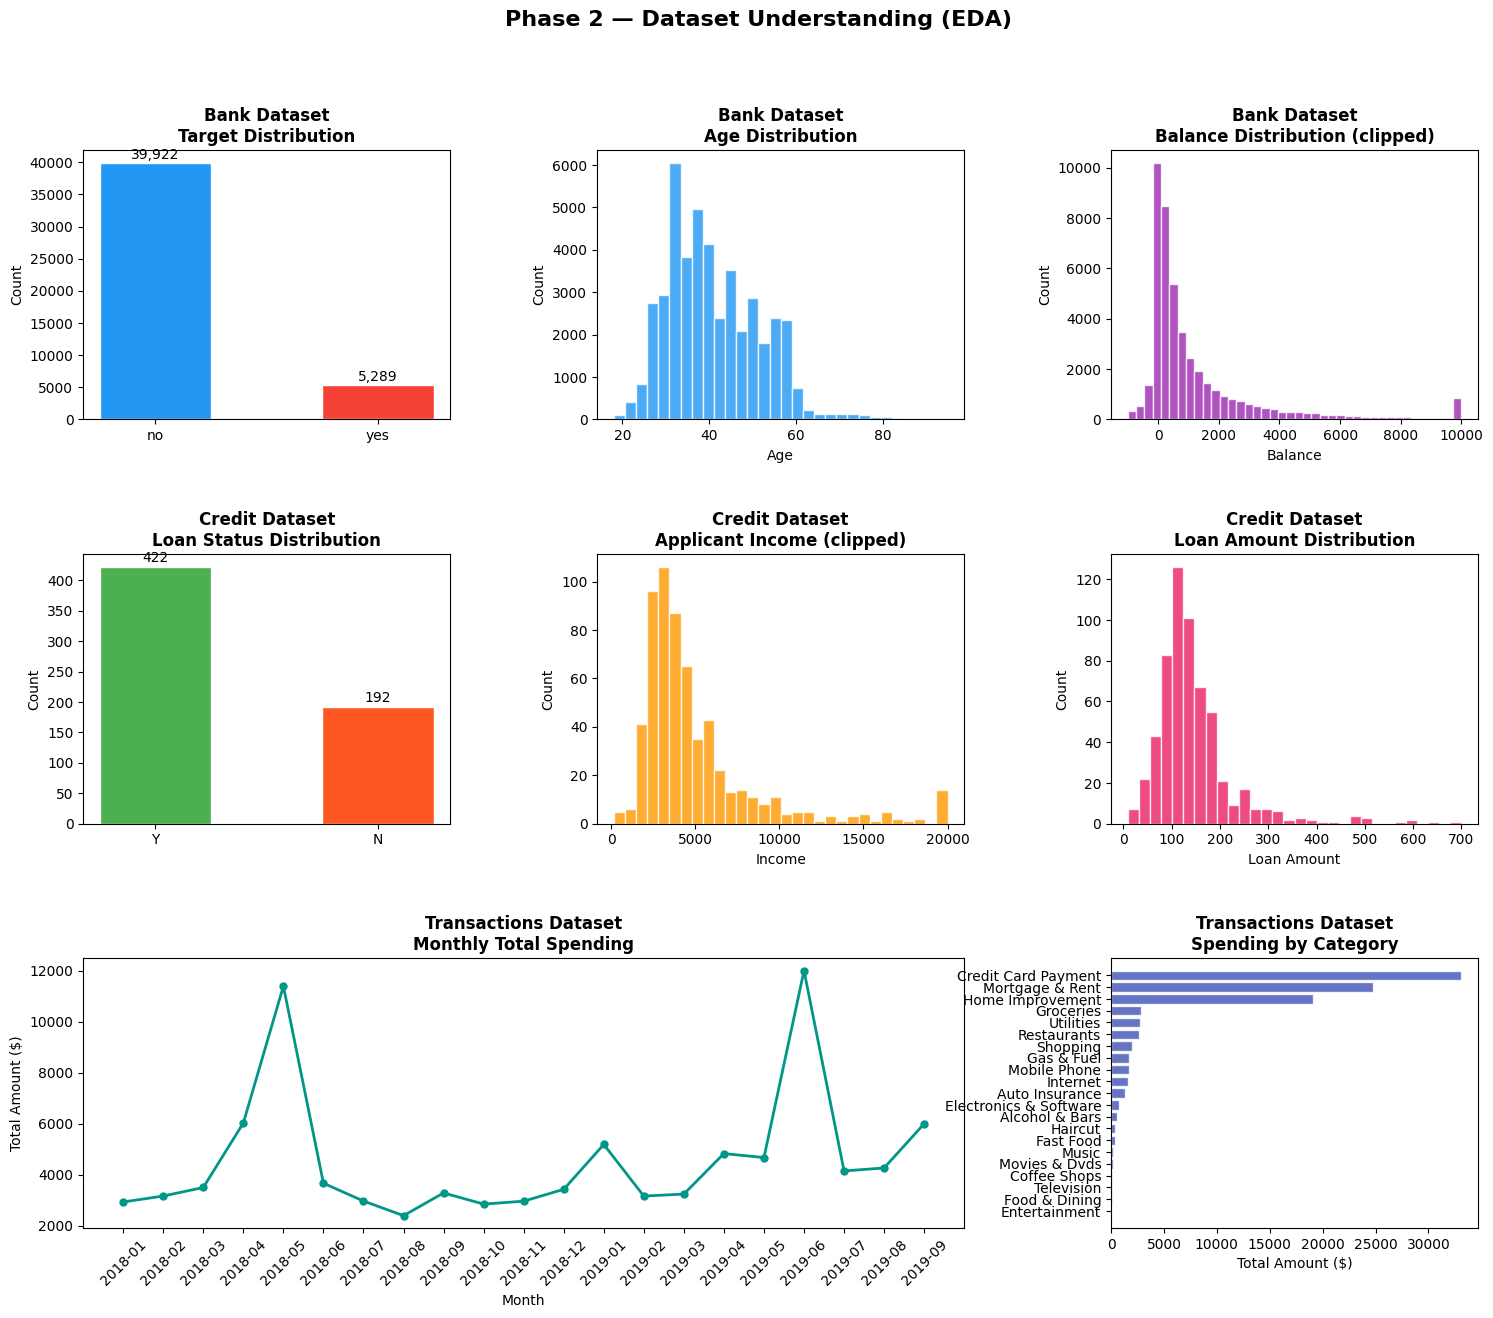

In [113]:
fig = plt.figure(figsize=(18, 14))
fig.suptitle("Phase 2 — Dataset Understanding (EDA)", fontsize=16, fontweight='bold', y=0.98)
gs = gridspec.GridSpec(3, 3, figure=fig, hspace=0.5, wspace=0.4)

# ── Plot 1: Bank target distribution
ax1 = fig.add_subplot(gs[0, 0])
counts = bank['y'].value_counts()
bars = ax1.bar(counts.index, counts.values, color=['#2196F3', '#F44336'], edgecolor='white', width=0.5)
ax1.set_title("Bank Dataset\nTarget Distribution", fontweight='bold')
ax1.set_ylabel("Count")
for bar, val in zip(bars, counts.values):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 200,
             f"{val:,}", ha='center', va='bottom', fontsize=10)

# ── Plot 2: Bank – age distribution
ax2 = fig.add_subplot(gs[0, 1])
ax2.hist(bank['age'], bins=30, color='#2196F3', edgecolor='white', alpha=0.8)
ax2.set_title("Bank Dataset\nAge Distribution", fontweight='bold')
ax2.set_xlabel("Age")
ax2.set_ylabel("Count")

# ── Plot 3: Bank – balance distribution (clipped)
ax3 = fig.add_subplot(gs[0, 2])
bal_clipped = bank['balance'].clip(-1000, 10000)
ax3.hist(bal_clipped, bins=40, color='#9C27B0', edgecolor='white', alpha=0.8)
ax3.set_title("Bank Dataset\nBalance Distribution (clipped)", fontweight='bold')
ax3.set_xlabel("Balance")
ax3.set_ylabel("Count")

# ── Plot 4: Credit – loan status
ax4 = fig.add_subplot(gs[1, 0])
counts2 = credit_clean['Loan_Status'].value_counts()
bars2 = ax4.bar(counts2.index, counts2.values, color=['#4CAF50', '#FF5722'], edgecolor='white', width=0.5)
ax4.set_title("Credit Dataset\nLoan Status Distribution", fontweight='bold')
ax4.set_ylabel("Count")
for bar, val in zip(bars2, counts2.values):
    ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 3,
             f"{val}", ha='center', va='bottom', fontsize=10)

# ── Plot 5: Credit – income distribution
ax5 = fig.add_subplot(gs[1, 1])
inc_clipped = credit_clean['ApplicantIncome'].clip(0, 20000)
ax5.hist(inc_clipped, bins=30, color='#FF9800', edgecolor='white', alpha=0.8)
ax5.set_title("Credit Dataset\nApplicant Income (clipped)", fontweight='bold')
ax5.set_xlabel("Income")
ax5.set_ylabel("Count")

# ── Plot 6: Credit – loan amount
ax6 = fig.add_subplot(gs[1, 2])
ax6.hist(credit_clean['LoanAmount'].dropna(), bins=30, color='#E91E63', edgecolor='white', alpha=0.8)
ax6.set_title("Credit Dataset\nLoan Amount Distribution", fontweight='bold')
ax6.set_xlabel("Loan Amount")
ax6.set_ylabel("Count")

# ── Plot 7: Transactions – monthly spend
ax7 = fig.add_subplot(gs[2, 0:2])
txn['YearMonth'] = txn['Date'].dt.to_period('M')
monthly = txn[txn['Transaction Type'] == 'debit'].groupby('YearMonth')['Amount'].sum()
ax7.plot(monthly.index.astype(str), monthly.values, marker='o', color='#009688',
         linewidth=2, markersize=5)
ax7.set_title("Transactions Dataset\nMonthly Total Spending", fontweight='bold')
ax7.set_xlabel("Month")
ax7.set_ylabel("Total Amount ($)")
ax7.tick_params(axis='x', rotation=45)

# ── Plot 8: Transactions – category breakdown
ax8 = fig.add_subplot(gs[2, 2])
cat_spend = txn[txn['Transaction Type'] == 'debit'].groupby('Category')['Amount'].sum().sort_values(ascending=True)
ax8.barh(cat_spend.index, cat_spend.values, color='#3F51B5', edgecolor='white', alpha=0.8)
ax8.set_title("Transactions Dataset\nSpending by Category", fontweight='bold')
ax8.set_xlabel("Total Amount ($)")

plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to prevent suptitle overlap
plt.show()

### DATASET SUMMARY & ROLES

In [114]:
print("\n" + "=" * 60)
print("  DATASET SUMMARY & ROLES")
print("=" * 60)
print(f"""
┌─────────────────────┬────────────┬──────────────┬──────────────────────────────────┐
│ Dataset             │ Rows       │ Columns      │ Role in Project                  │
├─────────────────────┼────────────┼──────────────┼──────────────────────────────────┤
│ bank-full.csv       │ 45,211     │ 17           │ Baseline models + AutoML         │
│ credit_risk.csv     │ 614 (used) │ 13           │ Main XGBoost classification      │
│ personal_txn.xlsx   │ 806        │ 7            │ Feature engineering (behavioural)│
└─────────────────────┴────────────┴──────────────┴──────────────────────────────────┘

Key observations:
  • Bank dataset  : 11.7% positive class → IMBALANCED (use SMOTE / class_weight)
  • Credit dataset: 68.7% approved        → mildly imbalanced
  • Transactions  : 806 rows, Jan 2018–Sep 2019, debit + credit entries
  • Credit dataset has significant missing values → needs careful imputation

Next → Phase 3: Data Preprocessing
""")


  DATASET SUMMARY & ROLES

┌─────────────────────┬────────────┬──────────────┬──────────────────────────────────┐
│ Dataset             │ Rows       │ Columns      │ Role in Project                  │
├─────────────────────┼────────────┼──────────────┼──────────────────────────────────┤
│ bank-full.csv       │ 45,211     │ 17           │ Baseline models + AutoML         │
│ credit_risk.csv     │ 614 (used) │ 13           │ Main XGBoost classification      │
│ personal_txn.xlsx   │ 806        │ 7            │ Feature engineering (behavioural)│
└─────────────────────┴────────────┴──────────────┴──────────────────────────────────┘

Key observations:
  • Bank dataset  : 11.7% positive class → IMBALANCED (use SMOTE / class_weight)
  • Credit dataset: 68.7% approved        → mildly imbalanced
  • Transactions  : 806 rows, Jan 2018–Sep 2019, debit + credit entries
  • Credit dataset has significant missing values → needs careful imputation

Next → Phase 3: Data Preprocessing



## FINANCIAL RISK EARLY WARNING SYSTEM
### Phase 3: Data Preprocessing
— Separate pipelines for all 3 datasets —

In [115]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler
import warnings
warnings.filterwarnings('ignore')

In [116]:
print("=" * 60)
print("  PHASE 3 — DATA PREPROCESSING")
print("=" * 60)

  PHASE 3 — DATA PREPROCESSING


### 3A. BANK DATASET PREPROCESSING

In [117]:
print("\n─── 3A. Bank Dataset Preprocessing ───\n")

print(f"[LOAD] Shape: {bank.shape}")

# ── Step 1: Handle 'unknown' values ──────────────────────────
# Strategy:
#   - job, education  → replace with mode (most frequent)
#   - contact         → keep as category ('unknown' is informative)
#   - poutcome        → keep 'unknown' → rename to 'not_contacted'

unknown_replace_mode = ['job', 'education']
for col in unknown_replace_mode:
    mode_val = bank[col][bank[col] != 'unknown'].mode()[0]
    before   = (bank[col] == 'unknown').sum()
    bank[col] = bank[col].replace('unknown', mode_val)
    print(f"  [MISSING] {col}: replaced {before} 'unknown' → '{mode_val}'")

bank['poutcome'] = bank['poutcome'].replace('unknown', 'not_contacted')
print(f"  [MISSING] poutcome: 'unknown' → 'not_contacted'")
# contact: leave as-is (unknown contact type is a real signal)
print(f"  [MISSING] contact: kept as-is ('unknown' = no contact info)")


─── 3A. Bank Dataset Preprocessing ───

[LOAD] Shape: (45211, 17)
  [MISSING] job: replaced 288 'unknown' → 'blue-collar'
  [MISSING] education: replaced 1857 'unknown' → 'secondary'
  [MISSING] poutcome: 'unknown' → 'not_contacted'
  [MISSING] contact: kept as-is ('unknown' = no contact info)


In [118]:
# ── Step 2: Encode target ─────────────────────────────────────
bank['y_encoded'] = (bank['y'] == 'yes').astype(int)
print(f"\n  [TARGET] y: yes→1, no→0  |  class 1: {bank['y_encoded'].mean()*100:.1f}%")


  [TARGET] y: yes→1, no→0  |  class 1: 11.7%


In [119]:
# ── Step 3: Encode month as cyclical (sin/cos) ────────────────
month_map = {'jan':1,'feb':2,'mar':3,'apr':4,'may':5,'jun':6,
             'jul':7,'aug':8,'sep':9,'oct':10,'nov':11,'dec':12}
bank['month_num'] = bank['month'].map(month_map)
bank['month_sin'] = np.sin(2 * np.pi * bank['month_num'] / 12)
bank['month_cos'] = np.cos(2 * np.pi * bank['month_num'] / 12)
print(f"\n  [ENCODE] month → month_sin, month_cos (cyclical encoding)")


  [ENCODE] month → month_sin, month_cos (cyclical encoding)


In [120]:
# ── Step 4: One-hot encode remaining categoricals ─────────────
cat_cols_bank = ['job', 'marital', 'education', 'default',
                 'housing', 'loan', 'contact', 'poutcome']
bank_encoded = pd.get_dummies(bank, columns=cat_cols_bank, drop_first=False)
# Drop original columns we no longer need
bank_encoded.drop(columns=['y', 'month', 'month_num'], inplace=True)
print(f"  [ENCODE] One-hot applied to: {cat_cols_bank}")
print(f"  [SHAPE] After encoding: {bank_encoded.shape}")

  [ENCODE] One-hot applied to: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'poutcome']
  [SHAPE] After encoding: (45211, 40)


In [121]:
# ── Step 5: Scale numeric features ───────────────────────────
num_cols_bank = ['age', 'balance', 'day', 'duration',
                 'campaign', 'pdays', 'previous']
scaler_bank = StandardScaler()
bank_encoded[num_cols_bank] = scaler_bank.fit_transform(bank_encoded[num_cols_bank])
print(f"  [SCALE] StandardScaler on: {num_cols_bank}")

  [SCALE] StandardScaler on: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']


In [122]:
# ── Step 6: Final check ───────────────────────────────────────
print(f"\n  [FINAL] Bank preprocessed shape: {bank_encoded.shape}")
print(f"  [CHECK] Missing values: {bank_encoded.isnull().sum().sum()}")
print(f"  [SAMPLE HEAD]:")
display(bank_encoded.head())

# Save preprocessed bank data
bank_encoded.to_csv('bank_preprocessed.csv', index=False)
print(f"  [SAVE]  → bank_preprocessed.csv")


  [FINAL] Bank preprocessed shape: (45211, 40)
  [CHECK] Missing values: 0
  [SAMPLE HEAD]:


,age,balance,day,duration,campaign,pdays,previous,y_encoded,month_sin,month_cos,...,housing_yes,loan_no,loan_yes,contact_cellular,contact_telephone,contact_unknown,poutcome_failure,poutcome_not_contacted,poutcome_other,poutcome_success
0,1.606965,0.256419,-1.298476,0.011016,-0.569351,-0.411453,-0.25194,0,0.5,-0.866025,...,True,True,False,False,False,True,False,True,False,False
1,0.288529,-0.437895,-1.298476,-0.416127,-0.569351,-0.411453,-0.25194,0,0.5,-0.866025,...,True,True,False,False,False,True,False,True,False,False
2,-0.747384,-0.446762,-1.298476,-0.707361,-0.569351,-0.411453,-0.25194,0,0.5,-0.866025,...,True,False,True,False,False,True,False,True,False,False
3,0.571051,0.047205,-1.298476,-0.645231,-0.569351,-0.411453,-0.25194,0,0.5,-0.866025,...,True,True,False,False,False,True,False,True,False,False
4,-0.747384,-0.447091,-1.298476,-0.233620,-0.569351,-0.411453,-0.25194,0,0.5,-0.866025,...,False,True,False,False,False,True,False,True,False,False


  [SAVE]  → bank_preprocessed.csv


### 3B. CREDIT RISK DATASET PREPROCESSING

In [123]:
print("\n─── 3B. Credit Risk Dataset Preprocessing ───\n")


# Fix numeric columns stored as strings
num_fix = ['ApplicantIncome','CoapplicantIncome','LoanAmount',
           'Loan_Amount_Term','Credit_History','Dependents']
for col in num_fix:
    credit[col] = pd.to_numeric(credit[col], errors='coerce')

# Drop rows with missing target
credit = credit.dropna(subset=['Loan_Status']).copy()
print(f"[LOAD] Shape (after dropping missing targets): {credit.shape}")


─── 3B. Credit Risk Dataset Preprocessing ───

[LOAD] Shape (after dropping missing targets): (614, 13)


In [124]:
# ── Step 1: Drop Loan_ID (not a feature) ─────────────────────
credit.drop(columns=['Loan_ID'], inplace=True)
print(f"  [DROP] Loan_ID removed")

  [DROP] Loan_ID removed


In [125]:
# ── Step 2: Impute missing values ────────────────────────────
# Numeric → median imputation
num_cols_credit = ['LoanAmount', 'Loan_Amount_Term', 'Credit_History',
                   'Dependents', 'CoapplicantIncome']
for col in num_cols_credit:
    n_missing = credit[col].isnull().sum()
    if n_missing > 0:
        median_val = credit[col].median()
        credit[col].fillna(median_val, inplace=True)
        print(f"  [IMPUTE] {col}: {n_missing} missing → median ({median_val:.1f})")

# Categorical → mode imputation
cat_cols_credit = ['Gender', 'Married', 'Self_Employed']
for col in cat_cols_credit:
    n_missing = credit[col].isnull().sum()
    if n_missing > 0:
        mode_val = credit[col].mode()[0]
        credit[col].fillna(mode_val, inplace=True)
        print(f"  [IMPUTE] {col}: {n_missing} missing → mode ('{mode_val}')")

  [IMPUTE] LoanAmount: 22 missing → median (128.0)
  [IMPUTE] Loan_Amount_Term: 14 missing → median (360.0)
  [IMPUTE] Credit_History: 50 missing → median (1.0)
  [IMPUTE] Dependents: 66 missing → median (0.0)
  [IMPUTE] Gender: 13 missing → mode ('Male')
  [IMPUTE] Married: 3 missing → mode ('Yes')
  [IMPUTE] Self_Employed: 32 missing → mode ('No')


In [126]:
# ── Step 3: Encode target ─────────────────────────────────────
credit['Loan_Status_encoded'] = (credit['Loan_Status'] == 'Y').astype(int)
print(f"\n  [TARGET] Loan_Status: Y→1, N→0  |  approval rate: {credit['Loan_Status_encoded'].mean()*100:.1f}%")


  [TARGET] Loan_Status: Y→1, N→0  |  approval rate: 68.7%


In [127]:
# ── Step 4: Encode binary categoricals manually ───────────────
# NOTE: done AFTER imputation so no NaNs survive
binary_map = {
    'Gender':        {'Male': 1, 'Female': 0},
    'Married':       {'Yes': 1, 'No': 0},
    'Education':     {'Graduate': 1, 'Not Graduate': 0},
    'Self_Employed': {'Yes': 1, 'No': 0},
}
for col, mapping in binary_map.items():
    credit[col] = credit[col].map(mapping).fillna(0).astype(int)
    print(f"  [ENCODE] {col}: {mapping}")

  [ENCODE] Gender: {'Male': 1, 'Female': 0}
  [ENCODE] Married: {'Yes': 1, 'No': 0}
  [ENCODE] Education: {'Graduate': 1, 'Not Graduate': 0}
  [ENCODE] Self_Employed: {'Yes': 1, 'No': 0}


In [128]:
# ── Step 5: One-hot encode Property_Area ─────────────────────
credit = pd.get_dummies(credit, columns=['Property_Area'], drop_first=False)
print(f"  [ENCODE] Property_Area → one-hot")

  [ENCODE] Property_Area → one-hot


In [129]:
# ── Step 6: Feature engineering — DTI & Savings Rate ─────────
credit['Total_Income'] = credit['ApplicantIncome'] + credit['CoapplicantIncome']
credit['DTI'] = credit['LoanAmount'] / (credit['Total_Income'] + 1)      # Debt-to-Income
credit['EMI'] = credit['LoanAmount'] / (credit['Loan_Amount_Term'] + 1)   # Monthly EMI estimate
credit['Income_per_Dependent'] = credit['Total_Income'] / (credit['Dependents'] + 1)
print(f"\n  [FEAT]  New features: Total_Income, DTI, EMI, Income_per_Dependent")


  [FEAT]  New features: Total_Income, DTI, EMI, Income_per_Dependent


In [130]:
# ── Step 7: Scale numeric features ───────────────────────────
num_cols_scale = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
                  'Loan_Amount_Term', 'Total_Income', 'DTI', 'EMI',
                  'Income_per_Dependent']
scaler_credit = StandardScaler()
credit[num_cols_scale] = scaler_credit.fit_transform(credit[num_cols_scale])
credit[num_cols_scale] = credit[num_cols_scale].fillna(0)   # safety fill after scaling
print(f"  [SCALE] StandardScaler on numeric features")

  [SCALE] StandardScaler on numeric features


In [131]:
# ── Step 8: Drop original target string column ────────────────
if 'Loan_Status' in credit.columns:
    credit.drop(columns=['Loan_Status'], inplace=True)

# Final safety: fill any remaining NaNs with 0
credit.fillna(0, inplace=True);

print(f"\n  [FINAL] Credit preprocessed shape: {credit.shape}")
print(f"  [CHECK] Missing values: {credit.isnull().sum().sum()}")
print(f"  [SAMPLE HEAD]:")
display(credit.head())

# Save preprocessed credit data
credit.to_csv('credit_preprocessed.csv', index=False)
print(f"  [SAVE]  → credit_preprocessed.csv")


  [FINAL] Credit preprocessed shape: (614, 18)
  [CHECK] Missing values: 0
  [SAMPLE HEAD]:


,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_Status_encoded,Property_Area_Rural,Property_Area_Semiurban,Property_Area_Urban,Total_Income,DTI,EMI,Income_per_Dependent
0,1,0,0.0,1,0,0.072991,-0.554487,-0.211241,0.273231,1.0,1,False,False,True,-0.182184,-0.228981,-0.237820,0.025994
1,1,1,1.0,1,0,-0.134412,-0.038732,-0.211241,0.273231,1.0,0,True,False,False,-0.144684,-0.328923,-0.237820,-0.420217
2,1,1,0.0,1,1,-0.393747,-0.554487,-0.948996,0.273231,1.0,1,False,False,True,-0.623656,-0.216065,-0.589741,-0.427459
3,1,1,0.0,0,0,-0.462062,0.251980,-0.306435,0.273231,1.0,1,False,False,True,-0.322885,0.047133,-0.283229,-0.118525
4,1,0,0.0,1,0,0.097728,-0.554487,-0.056551,0.273231,1.0,1,False,False,True,-0.158785,-0.043197,-0.164030,0.050027


  [SAVE]  → credit_preprocessed.csv


### 3C. TRANSACTIONS DATASET PREPROCESSING

In [132]:
print("\n─── 3C. Personal Transactions Dataset Preprocessing ───\n")

txn['Date'] = pd.to_datetime(txn['Date'])
print(f"[LOAD] Shape: {txn.shape}")
print(f"  Date range: {txn['Date'].min().date()} → {txn['Date'].max().date()}")


─── 3C. Personal Transactions Dataset Preprocessing ───

[LOAD] Shape: (806, 8)
  Date range: 2018-01-01 → 2019-09-30


In [133]:
# ── Step 1: Basic cleanup ─────────────────────────────────────
txn['Amount'] = txn['Amount'].abs()          # ensure positive amounts
txn['YearMonth'] = txn['Date'].dt.to_period('M')
txn['Year']  = txn['Date'].dt.year
txn['Month'] = txn['Date'].dt.month
txn['Day']   = txn['Date'].dt.day
txn['DayOfWeek'] = txn['Date'].dt.dayofweek  # 0=Monday
print(f"  [CLEAN] Amount → abs values")
print(f"  [FEAT]  Date decomposed: YearMonth, Year, Month, Day, DayOfWeek")

  [CLEAN] Amount → abs values
  [FEAT]  Date decomposed: YearMonth, Year, Month, Day, DayOfWeek


In [134]:
# ── Step 2: Separate debits and credits ───────────────────────
debits  = txn[txn['Transaction Type'] == 'debit'].copy()
credits = txn[txn['Transaction Type'] == 'credit'].copy()
print(f"\n  [SPLIT] Debits: {len(debits)} | Credits: {len(credits)}")


  [SPLIT] Debits: 688 | Credits: 118


In [135]:
# ── Step 3: Monthly aggregation ───────────────────────────────
monthly_expense = (
debits
    .groupby('YearMonth')['Amount']
    .agg(
        monthly_expense='sum',
        num_transactions='count',
        avg_transaction='mean',
        max_transaction='max'
    )
    .reset_index()
)

monthly_income = (
credits
    .groupby('YearMonth')['Amount']
    .agg(monthly_income='sum')
    .reset_index()
)

monthly = monthly_expense.merge(monthly_income, on='YearMonth', how='outer').fillna(0)
monthly = monthly.sort_values('YearMonth').reset_index(drop=True)
print(f"\n  [AGG] Monthly summary: {monthly.shape[0]} months")


  [AGG] Monthly summary: 21 months


In [136]:
# ── Step 4: Behavioural features ─────────────────────────────
# Expense growth (% change month over month)
monthly['expense_growth'] = monthly['monthly_expense'].pct_change().fillna(0)
monthly['expense_growth'] = monthly['expense_growth'].clip(-2, 2)   # cap outliers

# Rolling volatility (3-month std of expenses)
monthly['expense_volatility'] = (
    monthly['monthly_expense']
    .rolling(window=3, min_periods=1)
    .std()
    .fillna(0)
)

# Savings rate
monthly['savings_rate'] = (
    (monthly['monthly_income'] - monthly['monthly_expense'])
    / (monthly['monthly_income'] + 1)     # +1 to avoid /0
).clip(-2, 2)

# Spending spike flag (expense growth > 30%)
monthly['spending_spike'] = (monthly['expense_growth'] > 0.3).astype(int)

# Income stability flag (monthly income = 0)
monthly['no_income_flag'] = (monthly['monthly_income'] == 0).astype(int)

print(f"  [FEAT]  expense_growth, expense_volatility, savings_rate")
print(f"  [FEAT]  spending_spike, no_income_flag")

  [FEAT]  expense_growth, expense_volatility, savings_rate
  [FEAT]  spending_spike, no_income_flag


In [137]:
# ── Step 5: Category-level monthly breakdown ──────────────────
cat_pivot = (
debits
    .groupby(['YearMonth', 'Category'])['Amount']
    .sum()
    .unstack(fill_value=0)
    .reset_index()
)
# Rename columns
cat_pivot.columns = (
    ['YearMonth'] +
    ['cat_' + c.lower().replace(' ', '_').replace('&', 'and')
     for c in cat_pivot.columns[1:]]
)

# Merge with monthly
monthly = monthly.merge(cat_pivot, on='YearMonth', how='left').fillna(0)
print(f"  [FEAT]  Category-level spend columns added: {len(cat_pivot.columns)-1} categories")

  [FEAT]  Category-level spend columns added: 21 categories


In [138]:
# ── Step 6: Risk signal from transactions ────────────────────
# Simple rule-based risk score (used later in early warning system)
monthly['txn_risk_score'] = 0.0
monthly['txn_risk_score'] += (monthly['expense_growth'] > 0.3).astype(float) * 0.3
monthly['txn_risk_score'] += (monthly['savings_rate'] < 0.1).astype(float) * 0.3
monthly['txn_risk_score'] += (monthly['expense_volatility'] >
                              monthly['expense_volatility'].median()).astype(float) * 0.2
monthly['txn_risk_score'] += monthly['no_income_flag'].astype(float) * 0.2
monthly['txn_risk_score'] = monthly['txn_risk_score'].clip(0, 1)
print(f"\n  [RISK]  txn_risk_score computed (0–1 scale)")


  [RISK]  txn_risk_score computed (0–1 scale)


In [139]:
# ── Step 7: Save ─────────────────────────────────────────────
monthly['YearMonth'] = monthly['YearMonth'].astype(str)
print(f"\n  [FINAL] Transactions preprocessed shape: {monthly.shape}")
print(f"  [CHECK] Missing values: {monthly.isnull().sum().sum()}")
print(f"  [SAMPLE HEAD]:")
display(monthly.head())

# Save preprocessed transactions data
monthly.to_csv('transactions_preprocessed.csv', index=False)
print(f"  [SAVE]  → transactions_preprocessed.csv")


  [FINAL] Transactions preprocessed shape: (21, 33)
  [CHECK] Missing values: 0
  [SAMPLE HEAD]:


,YearMonth,monthly_expense,num_transactions,avg_transaction,max_transaction,monthly_income,expense_growth,expense_volatility,savings_rate,spending_spike,...,cat_internet,cat_mobile_phone,cat_mortgage_and_rent,cat_movies_and_dvds,cat_music,cat_restaurants,cat_shopping,cat_television,cat_utilities,txn_risk_score
0,2018-01,2931.45,27,108.572222,1247.44,7162.89,0.000000,0.000000,0.590662,0,...,69.99,89.46,1247.44,11.76,10.69,156.80,100.37,0.0,140.0,0.0
1,2018-02,3165.05,27,117.224074,1247.44,5220.75,0.079688,165.180144,0.393680,0,...,74.99,89.52,1247.44,11.76,10.69,290.85,11.11,0.0,160.0,0.0
2,2018-03,3500.16,38,92.109474,1247.44,7321.50,0.105878,285.860903,0.521863,0,...,74.99,89.52,1247.44,11.76,10.69,234.05,73.85,0.0,147.0,0.0
3,2018-04,6029.54,42,143.560476,1247.44,7166.88,0.722647,1566.065391,0.158672,1,...,74.99,89.52,1247.44,18.17,10.69,202.27,54.47,0.0,125.0,0.5
4,2018-05,11392.03,35,325.486571,8000.00,5091.55,0.889370,4029.798884,-1.237196,1,...,74.99,111.18,1247.44,38.01,10.69,127.30,219.45,0.0,125.0,0.8


  [SAVE]  → transactions_preprocessed.csv


### VISUALISATIONS — Phase 3 Summary

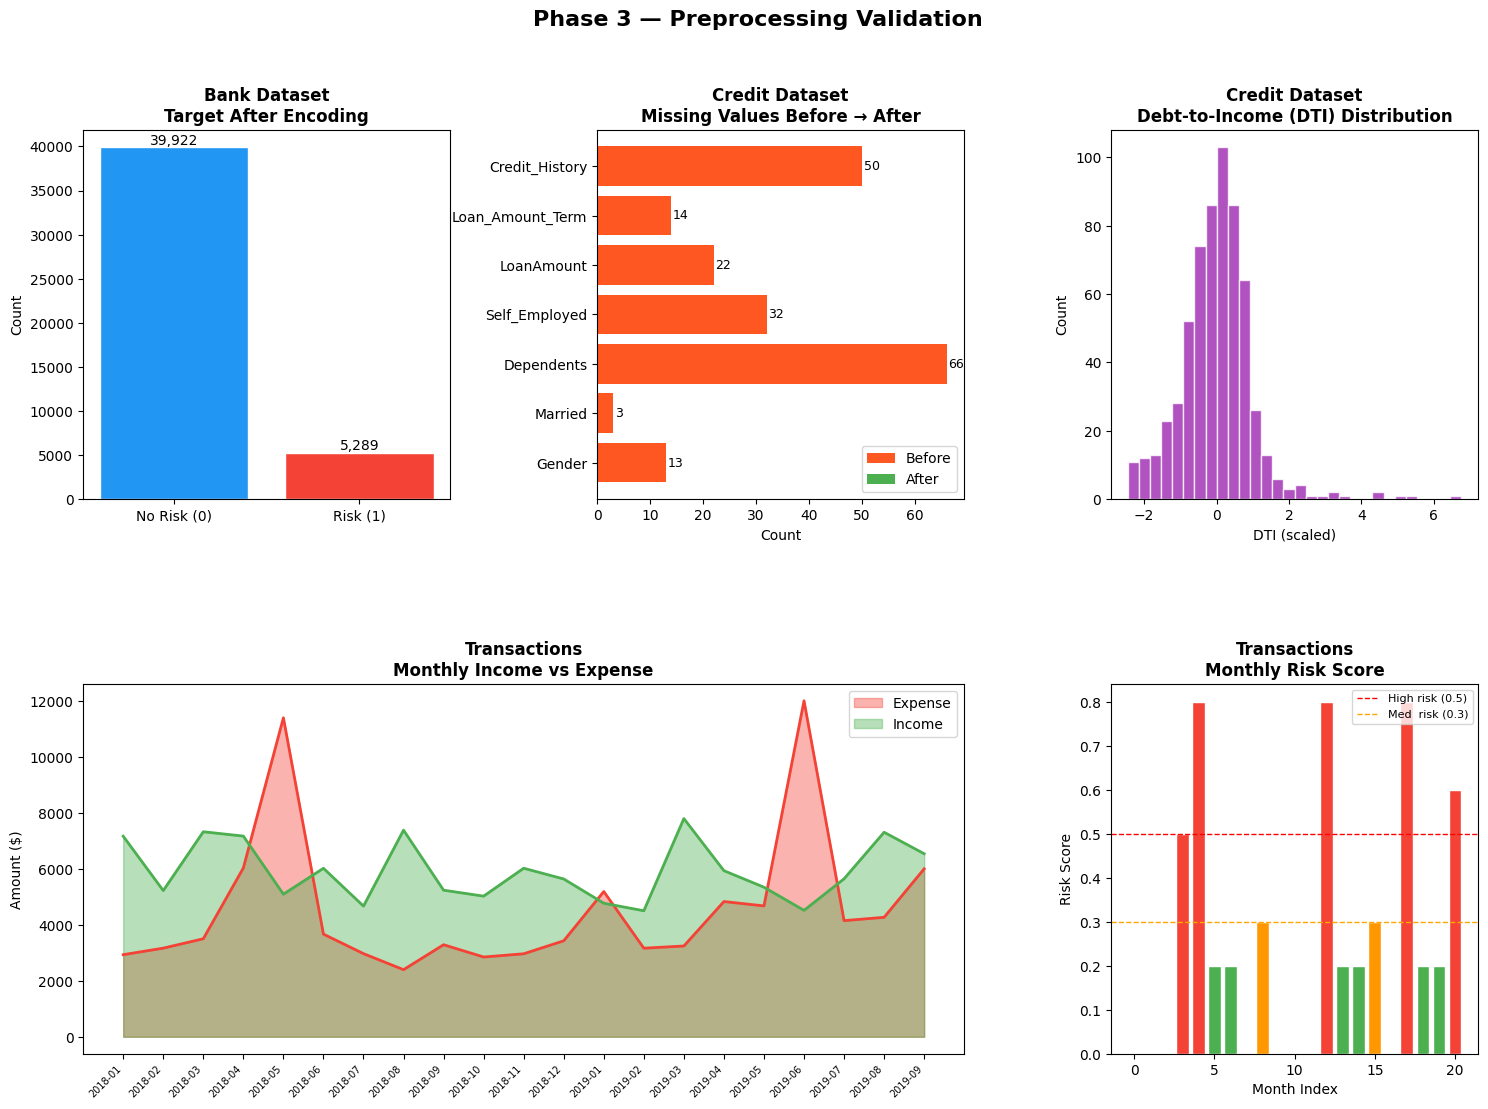

In [140]:
fig = plt.figure(figsize=(18, 12))
fig.suptitle("Phase 3 — Preprocessing Validation", fontsize=16, fontweight='bold', y=0.98)
gs  = gridspec.GridSpec(2, 3, figure=fig, hspace=0.5, wspace=0.4)

# ── Bank: class balance after encoding
ax1 = fig.add_subplot(gs[0, 0])
vals = bank_encoded['y_encoded'].value_counts()
ax1.bar(['No Risk (0)', 'Risk (1)'], vals.values, color=['#2196F3','#F44336'], edgecolor='white')
ax1.set_title("Bank Dataset\nTarget After Encoding", fontweight='bold')
ax1.set_ylabel("Count")
for i, v in enumerate(vals.values):
    ax1.text(i, v + 300, f"{v:,}", ha='center', fontsize=10)

# ── Credit: missing values heatmap (before vs after)
ax2 = fig.add_subplot(gs[0, 1])
credit_raw = pd.read_csv('/kaggle/input/datasets/ishitananda29/financial-risk-early-warning-system/credit_risk.csv')
for c in num_fix:
    credit_raw[c] = pd.to_numeric(credit_raw[c], errors='coerce')
credit_raw = credit_raw.dropna(subset=['Loan_Status'])
missing_before = credit_raw.isnull().sum()
missing_before = missing_before[missing_before > 0]
ax2.barh(missing_before.index, missing_before.values, color='#FF5722', label='Before')
ax2.barh(missing_before.index, [0]*len(missing_before), color='#4CAF50', label='After')
ax2.set_title("Credit Dataset\nMissing Values Before → After", fontweight='bold')
ax2.set_xlabel("Count")
ax2.legend()
for i, v in enumerate(missing_before.values):
    ax2.text(v + 0.3, i, str(v), va='center', fontsize=9)

# ── Credit: DTI distribution
ax3 = fig.add_subplot(gs[0, 2])
ax3.hist(credit['DTI'], bins=30, color='#9C27B0', edgecolor='white', alpha=0.8)
ax3.set_title("Credit Dataset\nDebt-to-Income (DTI) Distribution", fontweight='bold')
ax3.set_xlabel("DTI (scaled)")
ax3.set_ylabel("Count")

# ── Transactions: monthly expense + income
ax4 = fig.add_subplot(gs[1, 0:2])
ax4.fill_between(range(len(monthly)), monthly['monthly_expense'],
                 alpha=0.4, color='#F44336', label='Expense')
ax4.fill_between(range(len(monthly)), monthly['monthly_income'],
                 alpha=0.4, color='#4CAF50', label='Income')
ax4.plot(range(len(monthly)), monthly['monthly_expense'], color='#F44336', linewidth=2)
ax4.plot(range(len(monthly)), monthly['monthly_income'],  color='#4CAF50', linewidth=2)
ax4.set_xticks(range(len(monthly)))
ax4.set_xticklabels(monthly['YearMonth'], rotation=45, ha='right', fontsize=7)
ax4.set_title("Transactions\nMonthly Income vs Expense", fontweight='bold')
ax4.set_ylabel("Amount ($)")
ax4.legend()

# ── Transactions: txn_risk_score over time
ax5 = fig.add_subplot(gs[1, 2])
colors = ['#F44336' if s >= 0.5 else '#FF9800' if s >= 0.3 else '#4CAF50'
          for s in monthly['txn_risk_score']]
ax5.bar(range(len(monthly)), monthly['txn_risk_score'], color=colors, edgecolor='white')
ax5.axhline(0.5, color='red',    linestyle='--', linewidth=1, label='High risk (0.5)')
ax5.axhline(0.3, color='orange', linestyle='--', linewidth=1, label='Med  risk (0.3)')
ax5.set_title("Transactions\nMonthly Risk Score", fontweight='bold')
ax5.set_ylabel("Risk Score")
ax5.set_xlabel("Month Index")
ax5.legend(fontsize=8)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

In [141]:
# ── Final summary
print("\n" + "=" * 60)
print("  PHASE 3 COMPLETE — PREPROCESSING SUMMARY")
print("=" * 60)
print(f"""
  Dataset              Output File                    Shape
  ───────────────────────────────────────────────────────────
  bank-full.csv     →  bank_preprocessed.csv          {bank_encoded.shape}
  credit_risk.csv   →  credit_preprocessed.csv        {credit.shape}
  transactions.xlsx →  transactions_preprocessed.csv  {monthly.shape}

  What was done:
  ┌─ Bank ─────────────────────────────────────────────────┐
  │  • 'unknown' → mode imputation (job, education)        │
  │  • month → cyclical sin/cos encoding                   │
  │  • Categorical → one-hot encoding                      │
  │  • Numeric → StandardScaler                            │
  └────────────────────────────────────────────────────────┘
  ┌─ Credit ───────────────────────────────────────────────┐
  │  • Numeric → median imputation                         │
  • Categorical → mode imputation                       │
  │  • Binary cols → 0/1 manual encoding                   │
  │  • New features: DTI, EMI, Total_Income                │
  │  • Numeric → StandardScaler                            │
  └────────────────────────────────────────────────────────┘
  ┌─ Transactions ─────────────────────────────────────────┐
  │  • Date decomposed: Year, Month, Day, DayOfWeek        │
  │  • Monthly aggregation: expense, income, count         │
  │  • Behavioural: expense_growth, volatility             │
  │  • Flags: spending_spike, no_income_flag               │
  │  • Category-level monthly spend columns                │
  │  • txn_risk_score (rule-based, 0–1)                    │
  └────────────────────────────────────────────────────────┘

  Next → Phase 4: Feature Engineering
""")


  PHASE 3 COMPLETE — PREPROCESSING SUMMARY

  Dataset              Output File                    Shape
  ───────────────────────────────────────────────────────────
  bank-full.csv     →  bank_preprocessed.csv          (45211, 40)
  credit_risk.csv   →  credit_preprocessed.csv        (614, 18)
  transactions.xlsx →  transactions_preprocessed.csv  (21, 33)

  What was done:
  ┌─ Bank ─────────────────────────────────────────────────┐
  │  • 'unknown' → mode imputation (job, education)        │
  │  • month → cyclical sin/cos encoding                   │
  │  • Categorical → one-hot encoding                      │
  │  • Numeric → StandardScaler                            │
  └────────────────────────────────────────────────────────┘
  ┌─ Credit ───────────────────────────────────────────────┐
  │  • Numeric → median imputation                         │
  • Categorical → mode imputation                       │
  │  • Binary cols → 0/1 manual encoding                   │
  │  • New feat

## FINANCIAL RISK EARLY WARNING SYSTEM
### Phase 4: Feature Engineering

This phase creates the FINAL feature sets used in model training:

  A. Transaction behavioural features  (from `transactions_preprocessed.csv`)
  B. Credit financial ratios           (from `credit_preprocessed.csv`)
  C. Bank campaign features            (from `bank_preprocessed.csv`)
  D. Combined feature profile          (merged for final model input)

**Outputs:**
  `features_transactions.csv`   → behavioural feature profile
  `features_credit.csv`         → enriched credit features
  `features_bank.csv`           → bank features (ready, just documented)
  `features_summary.png`        → visual feature importance preview

In [142]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from sklearn.preprocessing import MinMaxScaler
import warnings
warnings.filterwarnings('ignore')

# ── Load preprocessed datasets ────────────────────────────────
bank   = pd.read_csv('bank_preprocessed.csv')
credit = pd.read_csv('credit_preprocessed.csv')
txn    = pd.read_csv('transactions_preprocessed.csv')

print("=" * 60)
print("  PHASE 4 — FEATURE ENGINEERING")
print("=" * 60)
print(f"\n[LOAD] Bank:   {bank.shape}")
print(f"[LOAD] Credit: {credit.shape}")
print(f"[LOAD] Txn:    {txn.shape}")

  PHASE 4 — FEATURE ENGINEERING

[LOAD] Bank:   (45211, 40)
[LOAD] Credit: (614, 18)
[LOAD] Txn:    (21, 33)


### 4A. TRANSACTION BEHAVIOURAL FEATURES

In [143]:
print("\n─── 4A. Transaction Behavioural Features ───\n")

# Load preprocessed transactions dataset
txn = pd.read_csv('transactions_preprocessed.csv')

# ── 1. Spending Momentum (3-month rolling mean) ───────────────
txn['spend_momentum_3m'] = (
    txn['monthly_expense']
    .rolling(window=3, min_periods=1)
    .mean()
)
print("  [FEAT] spend_momentum_3m   → 3-month rolling average expense")

# ── 2. Expense Acceleration ───────────────────────────────────
# 2nd derivative of spending — are expenses speeding up?
txn['expense_acceleration'] = txn['expense_growth'].diff().fillna(0)
print("  [FEAT] expense_acceleration → month-over-month change in growth rate")

# ── 3. Income Coverage Ratio ──────────────────────────────────
# How many months of expenses can income cover?
txn['income_coverage_ratio'] = (
    txn['monthly_income'] / (txn['monthly_expense'] + 1)
).round(4)
print("  [FEAT] income_coverage_ratio → income / expense ratio")

# ── 4. Discretionary Spend Ratio ─────────────────────────────
# Non-essential spending as % of total expense
discretionary_cols = [
    'cat_shopping', 'cat_restaurants', 'cat_fast_food',
    'cat_coffee_shops', 'cat_movies_and_dvds', 'cat_music',
    'cat_alcohol_and_bars', 'cat_entertainment'
]
essential_cols = [
    'cat_mortgage_and_rent', 'cat_groceries', 'cat_utilities',
    'cat_mobile_phone', 'cat_internet', 'cat_gas_and_fuel',
    'cat_auto_insurance'
]
txn['discretionary_spend'] = txn[discretionary_cols].sum(axis=1)
txn['essential_spend']      = txn[essential_cols].sum(axis=1)
txn['discretionary_ratio']  = (
    txn['discretionary_spend'] / (txn['monthly_expense'] + 1)
).round(4)
print("  [FEAT] discretionary_ratio  → non-essential spend / total expense")

# ── 5. Essential Spend Ratio ──────────────────────────────────
txn['essential_ratio'] = (
    txn['essential_spend'] / (txn['monthly_expense'] + 1)
).round(4)
print("  [FEAT] essential_ratio      → essential spend / total expense")

# ── 6. Spending Trend (linear slope over last 3 months) ───────
def rolling_slope(series, window=3):
    """Compute slope of spending trend using linear regression over rolling window."""
    slopes = []
    for i in range(len(series)):
        if i < window - 1:
            slopes.append(0.0)
        else:
            y = series.iloc[i-window+1 : i+1].values
            x = np.arange(window)
            slope = np.polyfit(x, y, 1)[0]
            slopes.append(round(slope, 4))
    return slopes

txn['spend_trend_slope'] = rolling_slope(txn['monthly_expense'], window=3)
print("  [FEAT] spend_trend_slope    → linear slope of spending over 3 months")

# ── 7. High Volatility Flag ───────────────────────────────────
vol_median = txn['expense_volatility'].median()
txn['high_volatility_flag'] = (txn['expense_volatility'] > vol_median).astype(int)
print(f"  [FEAT] high_volatility_flag → expense_volatility > median ({vol_median:.1f})")

# ── 8. Consecutive Deficit Months ────────────────────────────
# How many months in a row has savings_rate been negative?
txn['deficit_flag'] = (txn['savings_rate'] < 0).astype(int)
consec = []
count = 0
for v in txn['deficit_flag']:
    count = count + 1 if v == 1 else 0
    consec.append(count)
txn['consecutive_deficit_months'] = consec
print("  [FEAT] consecutive_deficit_months → streak of months with negative savings")

# ── 9. Normalised Risk Score (0–1) ────────────────────────────
# Weighted composite of all behavioural signals
from sklearn.preprocessing import RobustScaler

def scale_col(series):
    vals = series.values.reshape(-1, 1)
    return RobustScaler().fit_transform(vals).flatten()

risk_components = pd.DataFrame(index=txn.index)
risk_components['r1'] = scale_col(txn['expense_growth'].clip(-2, 2))
risk_components['r2'] = scale_col(txn['expense_volatility'])
risk_components['r3'] = 1 - scale_col(txn['savings_rate'].clip(-2, 2))
risk_components['r4'] = scale_col(txn['discretionary_ratio'])
risk_components['r5'] = scale_col(pd.Series(txn['consecutive_deficit_months'].values, index=txn.index))

weights = [0.25, 0.20, 0.25, 0.15, 0.15]
txn['behavioural_risk_score'] = (
    risk_components['r1'] * weights[0] +
    risk_components['r2'] * weights[1] +
    risk_components['r3'] * weights[2] +
    risk_components['r4'] * weights[3] +
    risk_components['r5'] * weights[4]
).round(4)
print("  [FEAT] behavioural_risk_score → weighted composite risk (0–1)")

# ── Select final transaction features ────────────────────────
txn_features = txn[[
    'YearMonth',
    # Core spending
    'monthly_expense', 'monthly_income', 'num_transactions',
    'avg_transaction', 'max_transaction',
    # Trend features
    'expense_growth', 'expense_acceleration', 'spend_momentum_3m',
    'spend_trend_slope',
    # Ratio features
    'income_coverage_ratio', 'savings_rate',
    'discretionary_ratio', 'essential_ratio',
    # Volatility & flags
    'expense_volatility', 'high_volatility_flag',
    'spending_spike', 'no_income_flag',
    'deficit_flag', 'consecutive_deficit_months',
    # Risk score
    'behavioural_risk_score', 'txn_risk_score',
    # Category-level (keep top ones)
    'cat_mortgage_and_rent', 'cat_groceries', 'cat_shopping',
    'cat_restaurants', 'cat_utilities', 'cat_gas_and_fuel'
]].copy()

print(f"\n  [FINAL] Transaction features shape: {txn_features.shape}")
txn_features.to_csv('features_transactions.csv', index=False)
print(f"  [SAVE]  → features_transactions.csv")


─── 4A. Transaction Behavioural Features ───

  [FEAT] spend_momentum_3m   → 3-month rolling average expense
  [FEAT] expense_acceleration → month-over-month change in growth rate
  [FEAT] income_coverage_ratio → income / expense ratio
  [FEAT] discretionary_ratio  → non-essential spend / total expense
  [FEAT] essential_ratio      → essential spend / total expense
  [FEAT] spend_trend_slope    → linear slope of spending over 3 months
  [FEAT] high_volatility_flag → expense_volatility > median (1035.9)
  [FEAT] consecutive_deficit_months → streak of months with negative savings
  [FEAT] behavioural_risk_score → weighted composite risk (0–1)

  [FINAL] Transaction features shape: (21, 28)
  [SAVE]  → features_transactions.csv


### 4B. CREDIT FINANCIAL RATIO FEATURES

In [144]:
print("\n─── 4B. Credit Financial Ratio Features ───\n")

# Load preprocessed credit dataset
credit = pd.read_csv('credit_preprocessed.csv')

# Note: DTI and EMI were already computed in Phase 3.
# Here we engineer higher-order ratio features.

# ── 1. Loan Burden Score ──────────────────────────────────────
# Combines DTI + EMI into a single burden metric
credit['loan_burden_score'] = (
    (credit['DTI'] * 0.6) + (credit['EMI'] * 0.4)
).round(4)
print("  [FEAT] loan_burden_score     → 0.6×DTI + 0.4×EMI")

# ── 2. Income Adequacy Score ──────────────────────────────────
# Total income relative to loan amount
credit['income_adequacy'] = (
    credit['Total_Income'] / (credit['LoanAmount'] + 0.001)
).round(4)
print("  [FEAT] income_adequacy       → Total_Income / LoanAmount")

# ── 3. Credit Risk Tier ───────────────────────────────────────
# Binning credit history + education into a tier (0/1/2)
credit['credit_risk_tier'] = 0  # default: low risk
credit.loc[credit['Credit_History'] == 0, 'credit_risk_tier'] = 2    # bad history → high risk
credit.loc[
    (credit['Credit_History'] == 1) & (credit['Education'] == 0),
    'credit_risk_tier'
] = 1  # good history but not graduate → medium
print("  [FEAT] credit_risk_tier      → 0=low, 1=medium, 2=high (based on Credit_History + Education)")

# ── 4. Family Financial Pressure ──────────────────────────────
# More dependents + lower income = more pressure
credit['family_pressure'] = (
    credit['Dependents'] / (credit['Total_Income'] + 0.001)
).round(4)
print("  [FEAT] family_pressure       → Dependents / Total_Income")

# ── 5. Self-Employment Risk Flag ─────────────────────────────
# Self-employed with no co-applicant income = higher risk
credit['solo_selfemployed_flag'] = (
    (credit['Self_Employed'] == 1) & (credit['CoapplicantIncome'] == 0)
).astype(int)
print("  [FEAT] solo_selfemployed_flag → Self_Employed=1 AND CoapplicantIncome=0")

# ── 6. Composite Credit Risk Score ────────────────────────────
from sklearn.preprocessing import RobustScaler

def scale_series(series):
    vals = series.values.reshape(-1, 1)
    return RobustScaler().fit_transform(vals).flatten()

cr_components = pd.DataFrame(index=credit.index)
cr_components['c1'] = scale_series(credit['DTI'])
cr_components['c2'] = 1 - scale_series(credit['Credit_History'])
cr_components['c3'] = scale_series(credit['loan_burden_score'])
cr_components['c4'] = scale_series(credit['family_pressure'])
cr_components['c5'] = credit['solo_selfemployed_flag'].values
cr_components['c6'] = credit['credit_risk_tier'].values / 2

cr_weights = [0.30, 0.25, 0.20, 0.10, 0.05, 0.10]
credit['composite_credit_risk'] = (
    cr_components['c1'] * cr_weights[0] +
    cr_components['c2'] * cr_weights[1] +
    cr_components['c3'] * cr_weights[2] +
    cr_components['c4'] * cr_weights[3] +
    cr_components['c5'] * cr_weights[4] +
    cr_components['c6'] * cr_weights[5]
).round(4)
print("  [FEAT] composite_credit_risk → weighted credit risk score (0–1)")

# ── Select final credit features ─────────────────────────────
credit_features = credit[[
    # Demographics
    'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed',
    # Income & loan
    'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
    'Loan_Amount_Term', 'Total_Income',
    # Phase 3 ratios
    'DTI', 'EMI', 'Income_per_Dependent',
    # Phase 4 new features
    'loan_burden_score', 'income_adequacy', 'credit_risk_tier',
    'family_pressure', 'solo_selfemployed_flag',
    'composite_credit_risk',
    # Credit history
    'Credit_History',
    # Property
    'Property_Area_Rural', 'Property_Area_Semiurban', 'Property_Area_Urban',
    # Target
    'Loan_Status_encoded'
]].copy()

print(f"\n  [FINAL] Credit features shape: {credit_features.shape}")
credit_features.to_csv('features_credit.csv', index=False)
print(f"  [SAVE]  → features_credit.csv")


─── 4B. Credit Financial Ratio Features ───

  [FEAT] loan_burden_score     → 0.6×DTI + 0.4×EMI
  [FEAT] income_adequacy       → Total_Income / LoanAmount
  [FEAT] credit_risk_tier      → 0=low, 1=medium, 2=high (based on Credit_History + Education)
  [FEAT] family_pressure       → Dependents / Total_Income
  [FEAT] solo_selfemployed_flag → Self_Employed=1 AND CoapplicantIncome=0
  [FEAT] composite_credit_risk → weighted credit risk score (0–1)

  [FINAL] Credit features shape: (614, 24)
  [SAVE]  → features_credit.csv


### 4C. BANK CAMPAIGN FEATURES (derived)

In [145]:
print("\n─── 4C. Bank Campaign Features ───\n")

# Load preprocessed bank dataset
bank = pd.read_csv('bank_preprocessed.csv')

# Bank data is already well-encoded from Phase 3.
# We add a few interaction features.

# ── 1. Contact Intensity Score ────────────────────────────────
# High campaign contacts + longer duration = more engaged
bank['contact_intensity'] = (
    bank['campaign'] * bank['duration']
).round(4)
print("  [FEAT] contact_intensity     → campaign × duration")

# ── 2. Was Previously Contacted ──────────────────────────────
bank['was_prev_contacted'] = (bank['previous'] > 0).astype(int)
print("  [FEAT] was_prev_contacted    → previous > 0")

# ── 3. Recent Contact Flag ────────────────────────────────────
# pdays = -1 means never contacted; otherwise days since last contact
# After scaling, -1 becomes the minimum scaled value.
# We flag if they were contacted within ~90 days (approx top 25th percentile)
bank['recently_contacted'] = (bank['pdays'] > bank['pdays'].quantile(0.25)).astype(int)
print("  [FEAT] recently_contacted    → pdays in top 75th percentile")

# ── 4. Balance Risk Flag ──────────────────────────────────────
# Negative balance = financial stress signal
bank['negative_balance'] = (bank['balance'] < 0).astype(int)
print("  [FEAT] negative_balance      → balance < 0 (scaled, so < mean)")

# ── 5. Age Group (binned) ─────────────────────────────────────
# age is scaled — rebin using quantile cuts
bank['age_group'] = pd.qcut(bank['age'], q=4, labels=[0, 1, 2, 3]).astype(int)
print("  [FEAT] age_group             → quartile bins of age (0=youngest, 3=oldest)")

# Save bank features (already mostly engineered in Phase 3)
bank_features = bank.copy()
bank_features['contact_intensity'] = bank['contact_intensity']
bank_features['was_prev_contacted'] = bank['was_prev_contacted']
bank_features['recently_contacted'] = bank['recently_contacted']
bank_features['negative_balance']   = bank['negative_balance']
bank_features['age_group']          = bank['age_group']

print(f"\n  [FINAL] Bank features shape: {bank_features.shape}")
bank_features.to_csv('features_bank.csv', index=False)
print(f"  [SAVE]  → features_bank.csv")


─── 4C. Bank Campaign Features ───

  [FEAT] contact_intensity     → campaign × duration
  [FEAT] was_prev_contacted    → previous > 0
  [FEAT] recently_contacted    → pdays in top 75th percentile
  [FEAT] negative_balance      → balance < 0 (scaled, so < mean)
  [FEAT] age_group             → quartile bins of age (0=youngest, 3=oldest)

  [FINAL] Bank features shape: (45211, 45)
  [SAVE]  → features_bank.csv


### 4D. FEATURE SUMMARY TABLE

In [146]:
print("\n─── 4D. All Engineered Features Summary ───\n")

all_features = {
    "TRANSACTION BEHAVIOURAL": {
        "expense_growth":              "Month-over-month % change in expenses",
        "expense_acceleration":        "Rate of change in expense growth",
        "spend_momentum_3m":           "3-month rolling average of expenses",
        "spend_trend_slope":           "Linear slope of spending trend",
        "income_coverage_ratio":       "Monthly income ÷ monthly expense",
        "savings_rate":                "(Income - Expense) ÷ Income",
        "discretionary_ratio":         "Non-essential spend ÷ total expense",
        "essential_ratio":             "Essential spend ÷ total expense",
        "expense_volatility":          "Rolling std dev of monthly expenses",
        "high_volatility_flag":        "1 if volatility > median volatility",
        "spending_spike":              "1 if expense_growth > 30%",
        "consecutive_deficit_months":  "Streak of months with negative savings",
        "behavioural_risk_score":      "Weighted composite behavioural risk (0–1)",
    },
    "CREDIT FINANCIAL": {
        "DTI":                    "Loan Amount ÷ Total Income",
        "EMI":                    "Loan Amount ÷ Loan Term",
        "loan_burden_score":      "0.6×DTI + 0.4×EMI",
        "income_adequacy":        "Total Income ÷ Loan Amount",
        "credit_risk_tier":       "0/1/2 based on credit history + education",
        "family_pressure":        "Dependents ÷ Total Income",
        "solo_selfemployed_flag": "1 if self-employed with no co-applicant income",
        "composite_credit_risk":  "Weighted credit risk score (0–1)",
        "Income_per_Dependent":   "Total Income ÷ (Dependents + 1)",
    },
    "BANK CAMPAIGN": {
        "contact_intensity":   "Campaign calls × call duration",
        "was_prev_contacted":  "1 if previously contacted",
        "recently_contacted":  "1 if contacted within recent period",
        "negative_balance":    "1 if account balance < 0",
        "age_group":           "Age quartile bins (0–3)",
        "month_sin / month_cos": "Cyclical month encoding",
    }
}

for category, features in all_features.items():
    print(f"\n  ── {category} ──")
    for feat, desc in features.items():
        print(f"    {feat:<35} {desc}")

total_feats = sum(len(v) for v in all_features.values())
print(f"\n  Total new features engineered: {total_feats}")


─── 4D. All Engineered Features Summary ───


  ── TRANSACTION BEHAVIOURAL ──
    expense_growth                      Month-over-month % change in expenses
    expense_acceleration                Rate of change in expense growth
    spend_momentum_3m                   3-month rolling average of expenses
    spend_trend_slope                   Linear slope of spending trend
    income_coverage_ratio               Monthly income ÷ monthly expense
    savings_rate                        (Income - Expense) ÷ Income
    discretionary_ratio                 Non-essential spend ÷ total expense
    essential_ratio                     Essential spend ÷ total expense
    expense_volatility                  Rolling std dev of monthly expenses
    high_volatility_flag                1 if volatility > median volatility
    spending_spike                      1 if expense_growth > 30%
    consecutive_deficit_months          Streak of months with negative savings
    behavioural_risk_score           

### VISUALISATIONS — Phase 4 Summary

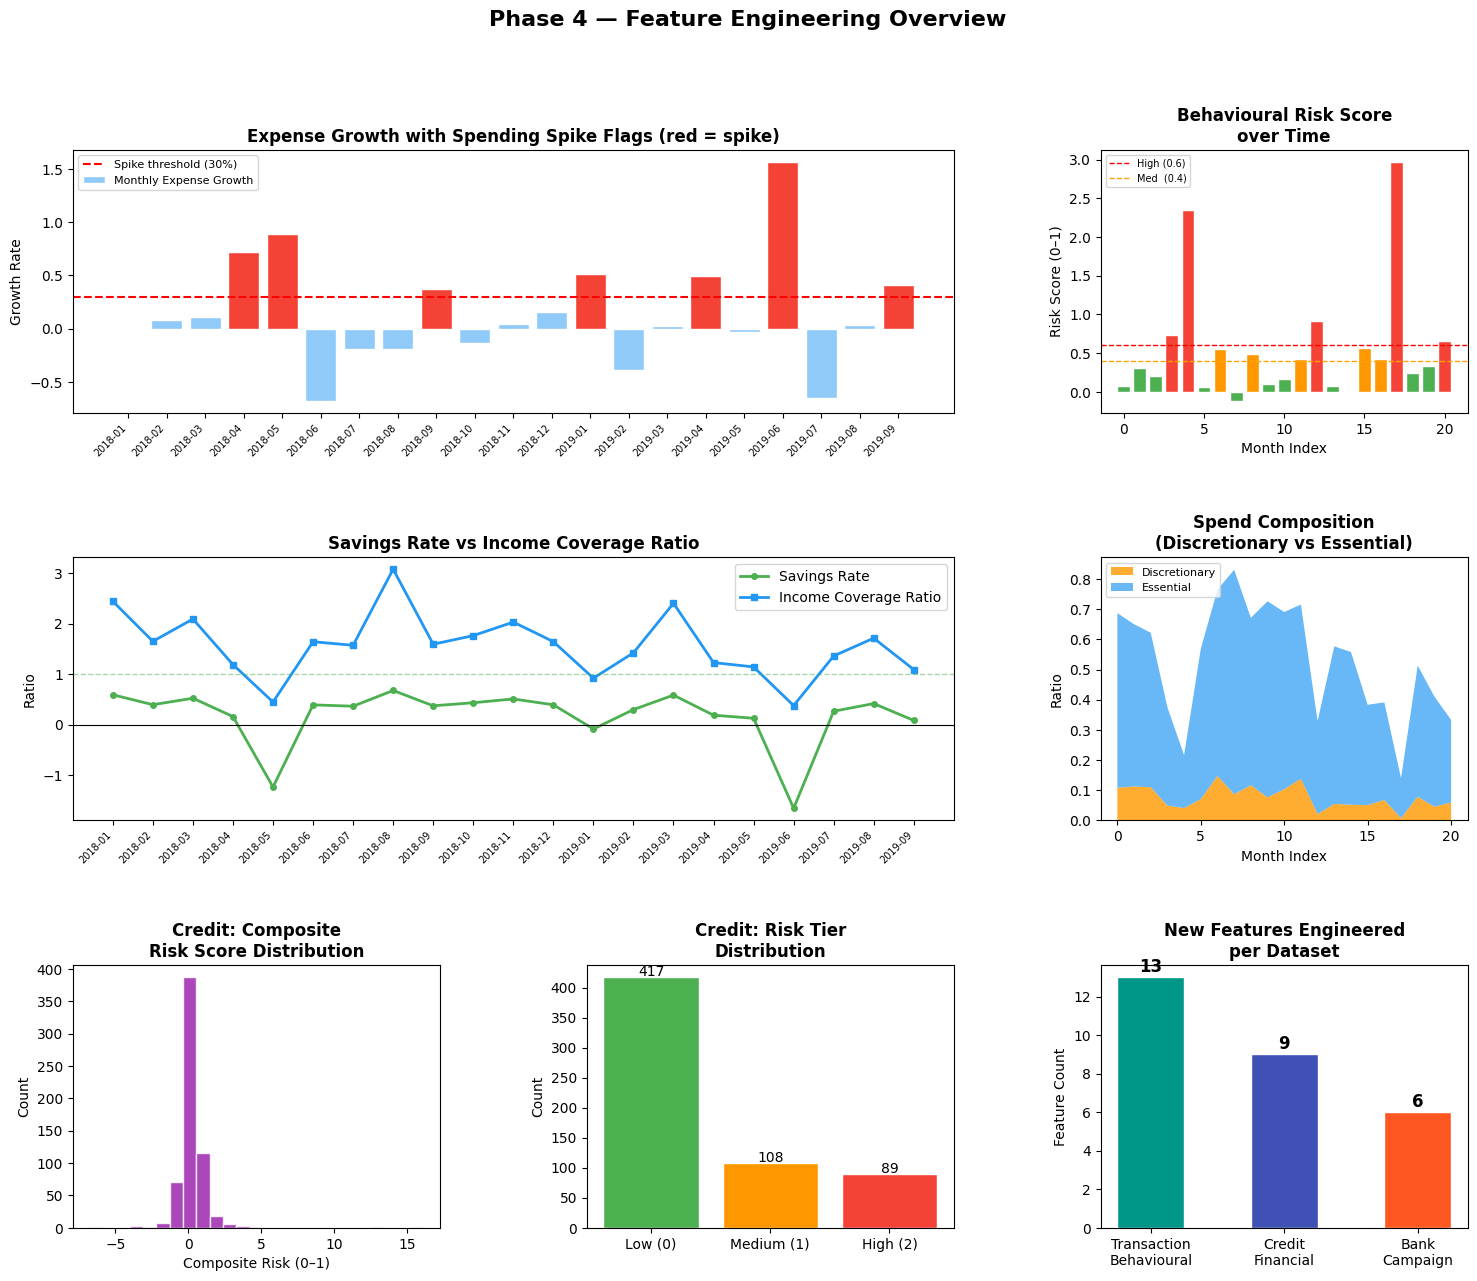

In [147]:
fig = plt.figure(figsize=(18, 14))
fig.suptitle("Phase 4 — Feature Engineering Overview", fontsize=16, fontweight='bold', y=0.98)
gs  = gridspec.GridSpec(3, 3, figure=fig, hspace=0.55, wspace=0.4)

months = txn_features['YearMonth']
x      = range(len(months))

# ── Plot 1: Expense growth vs spending spike flags
ax1 = fig.add_subplot(gs[0, 0:2])
ax1.bar(x, txn_features['expense_growth'], color=[
    '#F44336' if s else '#90CAF9' for s in txn_features['spending_spike']
], edgecolor='white', label='Monthly Expense Growth')
ax1.axhline(0.3, color='red', linestyle='--', linewidth=1.5, label='Spike threshold (30%)')
ax1.set_title("Expense Growth with Spending Spike Flags (red = spike)", fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(months, rotation=45, ha='right', fontsize=7)
ax1.set_ylabel("Growth Rate")
ax1.legend(fontsize=8)

# ── Plot 2: Behavioural risk score over time
ax2 = fig.add_subplot(gs[0, 2])
colors = ['#F44336' if s >= 0.6 else '#FF9800' if s >= 0.4 else '#4CAF50'
          for s in txn_features['behavioural_risk_score']]
ax2.bar(x, txn_features['behavioural_risk_score'], color=colors, edgecolor='white')
ax2.axhline(0.6, color='red',    linestyle='--', linewidth=1, label='High (0.6)')
ax2.axhline(0.4, color='orange', linestyle='--', linewidth=1, label='Med  (0.4)')
ax2.set_title("Behavioural Risk Score\nover Time", fontweight='bold')
ax2.set_ylabel("Risk Score (0–1)")
ax2.set_xlabel("Month Index")
ax2.legend(fontsize=7)

# ── Plot 3: Savings rate vs income coverage ratio
ax3 = fig.add_subplot(gs[1, 0:2])
ax3.plot(x, txn_features['savings_rate'],          label='Savings Rate',          color='#4CAF50', linewidth=2, marker='o', markersize=4)
ax3.plot(x, txn_features['income_coverage_ratio'], label='Income Coverage Ratio', color='#2196F3', linewidth=2, marker='s', markersize=4)
ax3.axhline(0, color='black', linestyle='-', linewidth=0.8)
ax3.axhline(1, color='#4CAF50', linestyle='--', linewidth=1, alpha=0.5)
ax3.set_title("Savings Rate vs Income Coverage Ratio", fontweight='bold')
ax3.set_xticks(x)
ax3.set_xticklabels(months, rotation=45, ha='right', fontsize=7)
ax3.set_ylabel("Ratio")
ax3.legend()

# ── Plot 4: Discretionary vs Essential spend ratio
ax4 = fig.add_subplot(gs[1, 2])
ax4.stackplot(x,
    txn_features['discretionary_ratio'],
    txn_features['essential_ratio'],
    labels=['Discretionary', 'Essential'],
    colors=['#FF9800', '#42A5F5'],
    alpha=0.8
)
ax4.set_title("Spend Composition\n(Discretionary vs Essential)", fontweight='bold')
ax4.set_ylabel("Ratio")
ax4.set_xlabel("Month Index")
ax4.legend(loc='upper left', fontsize=8)

# ── Plot 5: Credit composite risk score distribution
ax5 = fig.add_subplot(gs[2, 0])
ax5.hist(credit_features['composite_credit_risk'], bins=25,
         color='#9C27B0', edgecolor='white', alpha=0.85)
ax5.set_title("Credit: Composite\nRisk Score Distribution", fontweight='bold')
ax5.set_xlabel("Composite Risk (0–1)")
ax5.set_ylabel("Count")

# ── Plot 6: Credit risk tier breakdown
ax6 = fig.add_subplot(gs[2, 1])
tier_counts = credit_features['credit_risk_tier'].value_counts().sort_index()
ax6.bar(['Low (0)', 'Medium (1)', 'High (2)'],
        tier_counts.values,
        color=['#4CAF50', '#FF9800', '#F44336'],
        edgecolor='white')
ax6.set_title("Credit: Risk Tier\nDistribution", fontweight='bold')
ax6.set_ylabel("Count")
for i, v in enumerate(tier_counts.values):
    ax6.text(i, v + 2, str(v), ha='center', fontsize=10)

# ── Plot 7: Feature count summary
ax7 = fig.add_subplot(gs[2, 2])
categories  = ['Transaction\nBehavioural', 'Credit\nFinancial', 'Bank\nCampaign']
feat_counts = [13, 9, 6]
bar_colors  = ['#009688', '#3F51B5', '#FF5722']
bars = ax7.bar(categories, feat_counts, color=bar_colors, edgecolor='white', width=0.5)
ax7.set_title("New Features Engineered\nper Dataset", fontweight='bold')
ax7.set_ylabel("Feature Count")
for bar, val in zip(bars, feat_counts):
    ax7.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
             str(val), ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

In [148]:
print("\n[✓] Feature engineering chart saved → phase4_features.png")

# ── Final summary ─────────────────────────────────────────────
print("\n" + "=" * 60)
print("  PHASE 4 COMPLETE — FEATURE ENGINEERING SUMMARY")
print("=" * 60)
print(f"""
  Output Files:
  ─────────────────────────────────────────────────────────
  features_transactions.csv  {txn_features.shape[0]} rows × {txn_features.shape[1]} columns
  features_credit.csv        {credit_features.shape[0]} rows × {credit_features.shape[1]} columns
  features_bank.csv          {bank_features.shape[0]} rows × {bank_features.shape[1]} columns

  Key Features Created:
  ─────────────────────────────────────────────────────────
  behavioural_risk_score     Weighted composite (transactions)
  composite_credit_risk      Weighted composite (credit)
  spend_trend_slope          Linear trend of spending
  expense_acceleration       Speed-up/slow-down in expenses
  income_coverage_ratio      Income vs expense buffer
  discretionary_ratio        Lifestyle spend % of total
  consecutive_deficit_months Streak of negative savings months
  loan_burden_score          Combined DTI + EMI burden
  credit_risk_tier           Tiered risk (0/1/2)
  solo_selfemployed_flag     High-risk employment pattern

  Next → Phase 5: Baseline Models
""")


[✓] Feature engineering chart saved → phase4_features.png

  PHASE 4 COMPLETE — FEATURE ENGINEERING SUMMARY

  Output Files:
  ─────────────────────────────────────────────────────────
  features_transactions.csv  21 rows × 28 columns
  features_credit.csv        614 rows × 24 columns
  features_bank.csv          45211 rows × 45 columns

  Key Features Created:
  ─────────────────────────────────────────────────────────
  behavioural_risk_score     Weighted composite (transactions)
  composite_credit_risk      Weighted composite (credit)
  spend_trend_slope          Linear trend of spending
  expense_acceleration       Speed-up/slow-down in expenses
  income_coverage_ratio      Income vs expense buffer
  discretionary_ratio        Lifestyle spend % of total
  consecutive_deficit_months Streak of negative savings months
  loan_burden_score          Combined DTI + EMI burden
  credit_risk_tier           Tiered risk (0/1/2)
  solo_selfemployed_flag     High-risk employment pattern

  Nex

## FINANCIAL RISK EARLY WARNING SYSTEM
### Phase 5: Baseline Models
— Logistic Regression + Random Forest on Bank Dataset —

Dataset  : `features_bank.csv`  (45,211 rows, 45 columns)
Target   : `y_encoded`  (0 = no subscription, 1 = subscribed)
Goal     : Establish benchmark metrics before XGBoost (Phase 6)

**Models:**
  A. Logistic Regression  (linear baseline)
  B. Random Forest        (ensemble baseline)

**Techniques:**
  • SMOTE to handle class imbalance (11.7% positive)
  • 5-fold Stratified Cross-Validation
  • Threshold tuning for best F1
  • Full evaluation: Accuracy, Precision, Recall, F1, ROC-AUC

**Output:**
  `phase5_baseline_results.png`
  `baseline_results.csv`

In [149]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve,
    confusion_matrix, classification_report,
    precision_recall_curve
)
from sklearn.pipeline import Pipeline
# SMOTE implemented manually below
import warnings
warnings.filterwarnings('ignore')


# ── Manual SMOTE (no external dependency) ────────────────────
def manual_smote(X, y, random_state=42):
    rng   = np.random.RandomState(random_state)
    X_arr = np.array(X, dtype=float)
    y_arr = np.array(y)
    X_min = X_arr[y_arr == 1]
    X_maj = X_arr[y_arr == 0]
    n_gen = len(X_maj) - len(X_min)
    synth = []
    for _ in range(n_gen):
        i   = rng.randint(0, len(X_min))
        j   = rng.randint(0, len(X_min))
        lam = rng.uniform(0, 1)
        synth.append(X_min[i] + lam * (X_min[j] - X_min[i]))
    X_res = np.vstack([X_maj, X_min, np.array(synth)])
    y_res = np.hstack([np.zeros(len(X_maj)), np.ones(len(X_min) + n_gen)])
    perm  = rng.permutation(len(X_res))
    return X_res[perm], y_res[perm].astype(int)

print("=" * 60)
print("  PHASE 5 — BASELINE MODELS")
print("=" * 60)

# ── Load data ─────────────────────────────────────────────────
bank = pd.read_csv('features_bank.csv')
print(f"\n[LOAD] Bank features: {bank.shape}")
print(f"[INFO] Class distribution: {bank['y_encoded'].value_counts().to_dict()}")
print(f"[INFO] Positive class: {bank['y_encoded'].mean()*100:.1f}%  → imbalanced")

# ── Prepare X, y ──────────────────────────────────────────────
TARGET = 'y_encoded'
X = bank.drop(columns=[TARGET])
y = bank[TARGET]

# ── Train/Test split (stratified) ─────────────────────────────
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"\n[SPLIT] Train: {X_train.shape[0]:,}  |  Test: {X_test.shape[0]:,}")
print(f"[SPLIT] Train positives: {y_train.sum()} ({y_train.mean()*100:.1f}%)")
print(f"[SPLIT] Test  positives: {y_test.sum()}  ({y_test.mean()*100:.1f}%)")

# ── Apply SMOTE on training set only ──────────────────────────
print(f"\n[SMOTE] Applying SMOTE to balance training set...")
X_train_sm, y_train_sm = manual_smote(X_train, y_train, random_state=42)
print(f"[SMOTE] Before: {y_train.value_counts().to_dict()}")
print(f"[SMOTE] After : {pd.Series(y_train_sm).value_counts().to_dict()}")

  PHASE 5 — BASELINE MODELS

[LOAD] Bank features: (45211, 45)
[INFO] Class distribution: {0: 39922, 1: 5289}
[INFO] Positive class: 11.7%  → imbalanced

[SPLIT] Train: 36,168  |  Test: 9,043
[SPLIT] Train positives: 4231 (11.7%)
[SPLIT] Test  positives: 1058  (11.7%)

[SMOTE] Applying SMOTE to balance training set...
[SMOTE] Before: {0: 31937, 1: 4231}
[SMOTE] After : {0: 31937, 1: 31937}


In [150]:
# ╔══════════════════════════════════════════════════════════╗
# ║  MODEL A — LOGISTIC REGRESSION                           ║
# ╚══════════════════════════════════════════════════════════╝
print("\n─── Model A: Logistic Regression ───\n")

lr = LogisticRegression(
    max_iter=1000,
    random_state=42,
    C=1.0,              # regularisation strength
    solver='lbfgs',
    class_weight='balanced'   # extra safety for imbalance
)

# ── Cross-validation (on SMOTE-balanced train set) ────────────
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_auc_lr = cross_val_score(lr, X_train_sm, y_train_sm,
                             cv=cv, scoring='roc_auc', n_jobs=-1)
cv_rec_lr = cross_val_score(lr, X_train_sm, y_train_sm,
                             cv=cv, scoring='recall', n_jobs=-1)
print(f"  CV ROC-AUC : {cv_auc_lr.mean():.4f} ± {cv_auc_lr.std():.4f}")
print(f"  CV Recall  : {cv_rec_lr.mean():.4f} ± {cv_rec_lr.std():.4f}")

# ── Fit and predict ───────────────────────────────────────────
lr.fit(X_train_sm, y_train_sm)
y_prob_lr  = lr.predict_proba(X_test)[:, 1]

# ── Threshold tuning — find threshold with best F1 ───────────
thresholds = np.arange(0.1, 0.9, 0.01)
f1_scores  = [f1_score(y_test, (y_prob_lr >= t).astype(int)) for t in thresholds]
best_thresh_lr = thresholds[np.argmax(f1_scores)]
y_pred_lr  = (y_prob_lr >= best_thresh_lr).astype(int)
print(f"  Best threshold (F1): {best_thresh_lr:.2f}")

# ── Metrics ───────────────────────────────────────────────────
metrics_lr = {
    'Model':      'Logistic Regression',
    'Dataset':    'Bank',
    'Threshold':  round(best_thresh_lr, 2),
    'Accuracy':   round(accuracy_score(y_test, y_pred_lr), 4),
    'Precision':  round(precision_score(y_test, y_pred_lr), 4),
    'Recall':     round(recall_score(y_test, y_pred_lr), 4),
    'F1':         round(f1_score(y_test, y_pred_lr), 4),
    'ROC-AUC':    round(roc_auc_score(y_test, y_prob_lr), 4),
    'CV_AUC_mean': round(cv_auc_lr.mean(), 4),
}
print(f"\n  ── Logistic Regression Test Results ──")
for k, v in metrics_lr.items():
    if k not in ['Model', 'Dataset']:
        print(f"    {k:<15}: {v}")

print(f"\n  Classification Report:")
print(classification_report(y_test, y_pred_lr, target_names=['No Risk', 'Risk']))


─── Model A: Logistic Regression ───

  CV ROC-AUC : 0.9169 ± 0.0013
  CV Recall  : 0.8387 ± 0.0054
  Best threshold (F1): 0.73

  ── Logistic Regression Test Results ──
    Threshold      : 0.73
    Accuracy       : 0.8893
    Precision      : 0.5237
    Recall         : 0.5964
    F1             : 0.5577
    ROC-AUC        : 0.895
    CV_AUC_mean    : 0.9169

  Classification Report:
              precision    recall  f1-score   support

     No Risk       0.95      0.93      0.94      7985
        Risk       0.52      0.60      0.56      1058

    accuracy                           0.89      9043
   macro avg       0.73      0.76      0.75      9043
weighted avg       0.90      0.89      0.89      9043



In [151]:
# ╔══════════════════════════════════════════════════════════╗
# ║  MODEL B — RANDOM FOREST                                 ║
# ╚══════════════════════════════════════════════════════════╝
print("\n─── Model B: Random Forest ───\n")

rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_split=10,
    min_samples_leaf=4,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

# ── Cross-validation ──────────────────────────────────────────
cv_auc_rf = cross_val_score(rf, X_train_sm, y_train_sm,
                             cv=cv, scoring='roc_auc', n_jobs=-1)
cv_rec_rf = cross_val_score(rf, X_train_sm, y_train_sm,
                             cv=cv, scoring='recall', n_jobs=-1)
print(f"  CV ROC-AUC : {cv_auc_rf.mean():.4f} ± {cv_auc_rf.std():.4f}")
print(f"  CV Recall  : {cv_rec_rf.mean():.4f} ± {cv_rec_rf.std():.4f}")

# ── Fit and predict ───────────────────────────────────────────
rf.fit(X_train_sm, y_train_sm)
y_prob_rf = rf.predict_proba(X_test)[:, 1]

# ── Threshold tuning ──────────────────────────────────────────
f1_scores_rf  = [f1_score(y_test, (y_prob_rf >= t).astype(int)) for t in thresholds]
best_thresh_rf = thresholds[np.argmax(f1_scores_rf)]
y_pred_rf = (y_prob_rf >= best_thresh_rf).astype(int)
print(f"  Best threshold (F1): {best_thresh_rf:.2f}")

# ── Metrics ───────────────────────────────────────────────────
metrics_rf = {
    'Model':      'Random Forest',
    'Dataset':    'Bank',
    'Threshold':  round(best_thresh_rf, 2),
    'Accuracy':   round(accuracy_score(y_test, y_pred_rf), 4),
    'Precision':  round(precision_score(y_test, y_pred_rf), 4),
    'Recall':     round(recall_score(y_test, y_pred_rf), 4),
    'F1':         round(f1_score(y_test, y_pred_rf), 4),
    'ROC-AUC':    round(roc_auc_score(y_test, y_prob_rf), 4),
    'CV_AUC_mean': round(cv_auc_rf.mean(), 4),
}
print(f"\n  ── Random Forest Test Results ──")
for k, v in metrics_rf.items():
    if k not in ['Model', 'Dataset']:
        print(f"    {k:<15}: {v}")

print(f"\n  Classification Report:")
print(classification_report(y_test, y_pred_rf, target_names=['No Risk', 'Risk']))

# ── Feature importance (top 15) ───────────────────────────────
feat_imp = pd.Series(rf.feature_importances_, index=X.columns)
top15    = feat_imp.nlargest(15).sort_values()
print(f"\n  Top 15 Important Features (Random Forest):")
for feat, imp in top15.items():
    bar = '█' * int(imp * 300)
    print(f"    {feat:<35} {imp:.4f}  {bar}")


─── Model B: Random Forest ───

  CV ROC-AUC : 0.9896 ± 0.0004
  CV Recall  : 0.9190 ± 0.0020
  Best threshold (F1): 0.32

  ── Random Forest Test Results ──
    Threshold      : 0.32
    Accuracy       : 0.8829
    Precision      : 0.4997
    Recall         : 0.7457
    F1             : 0.5984
    ROC-AUC        : 0.9228
    CV_AUC_mean    : 0.9896

  Classification Report:
              precision    recall  f1-score   support

     No Risk       0.96      0.90      0.93      7985
        Risk       0.50      0.75      0.60      1058

    accuracy                           0.88      9043
   macro avg       0.73      0.82      0.76      9043
weighted avg       0.91      0.88      0.89      9043


  Top 15 Important Features (Random Forest):
    marital_single                      0.0278  ████████
    negative_balance                    0.0283  ████████
    contact_cellular                    0.0312  █████████
    month_sin                           0.0331  █████████
    contact_unknow

In [152]:
# ╔══════════════════════════════════════════════════════════╗
# ║  COMPARISON TABLE                                        ║
# ╚══════════════════════════════════════════════════════════╝
print("\n─── Baseline Model Comparison ───\n")

results_df = pd.DataFrame([metrics_lr, metrics_rf])
print(results_df[['Model', 'Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'CV_AUC_mean']].to_string(index=False))
results_df.to_csv('baseline_results.csv', index=False)
print("\n[SAVE] → baseline_results.csv")

# Winner
winner = 'Random Forest' if metrics_rf['ROC-AUC'] > metrics_lr['ROC-AUC'] else 'Logistic Regression'
print(f"\n[BENCHMARK] Best baseline model: {winner}")
print(f"[BENCHMARK] RF  ROC-AUC: {metrics_rf['ROC-AUC']}")
print(f"[BENCHMARK] LR  ROC-AUC: {metrics_lr['ROC-AUC']}")
print(f"[BENCHMARK] → XGBoost (Phase 6) will need to beat: {max(metrics_rf['ROC-AUC'], metrics_lr['ROC-AUC'])}")


─── Baseline Model Comparison ───

              Model  Accuracy  Precision  Recall     F1  ROC-AUC  CV_AUC_mean
Logistic Regression    0.8893     0.5237  0.5964 0.5577   0.8950       0.9169
      Random Forest    0.8829     0.4997  0.7457 0.5984   0.9228       0.9896

[SAVE] → baseline_results.csv

[BENCHMARK] Best baseline model: Random Forest
[BENCHMARK] RF  ROC-AUC: 0.9228
[BENCHMARK] LR  ROC-AUC: 0.895
[BENCHMARK] → XGBoost (Phase 6) will need to beat: 0.9228


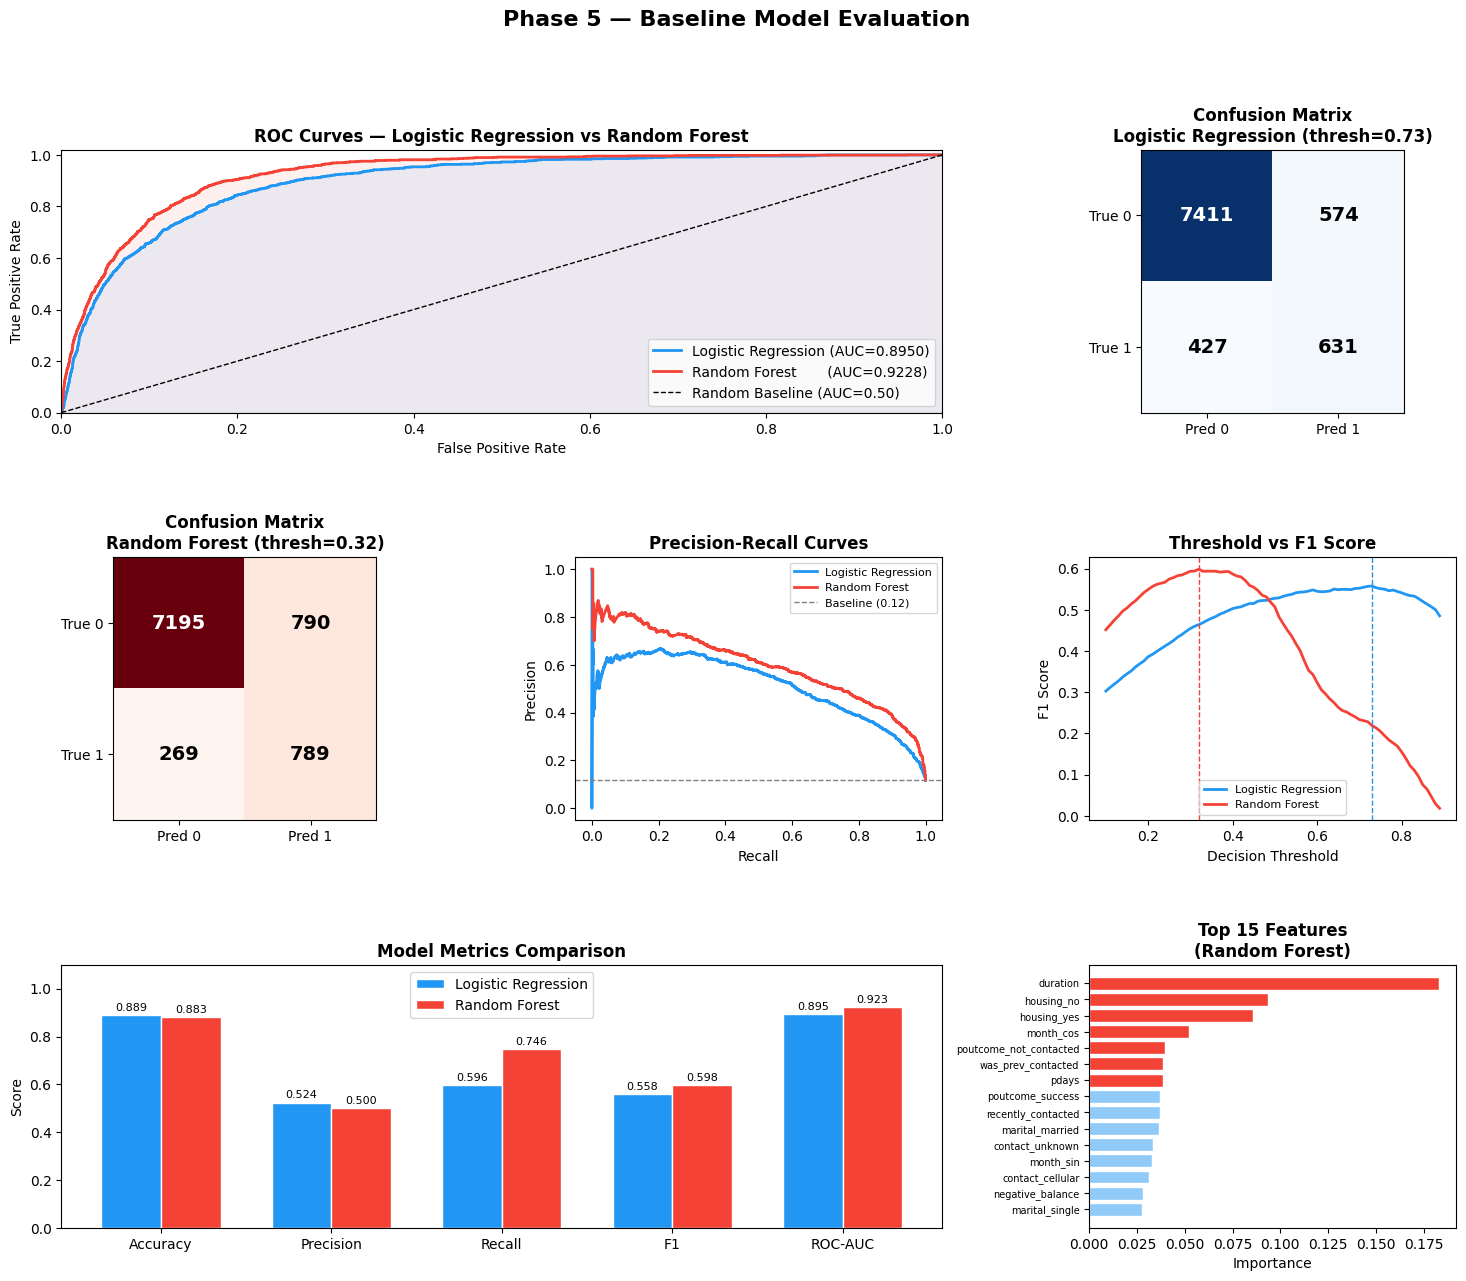

In [153]:
# ╔══════════════════════════════════════════════════════════╗
# ║  VISUALISATIONS                                          ║
# ╚══════════════════════════════════════════════════════════╝
fig = plt.figure(figsize=(18, 14))
fig.suptitle("Phase 5 — Baseline Model Evaluation", fontsize=16, fontweight='bold', y=0.98)
gs  = gridspec.GridSpec(3, 3, figure=fig, hspace=0.55, wspace=0.4)

# ── Plot 1: ROC Curves (both models)
ax1 = fig.add_subplot(gs[0, 0:2])
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
ax1.plot(fpr_lr, tpr_lr, color='#2196F3', linewidth=2,
         label=f"Logistic Regression (AUC={metrics_lr['ROC-AUC']:.4f})")
ax1.plot(fpr_rf, tpr_rf, color='#F44336', linewidth=2,
         label=f"Random Forest       (AUC={metrics_rf['ROC-AUC']:.4f})")
ax1.plot([0,1],[0,1], 'k--', linewidth=1, label='Random Baseline (AUC=0.50)')
ax1.fill_between(fpr_rf, tpr_rf, alpha=0.08, color='#F44336')
ax1.fill_between(fpr_lr, tpr_lr, alpha=0.08, color='#2196F3')
ax1.set_title("ROC Curves — Logistic Regression vs Random Forest", fontweight='bold')
ax1.set_xlabel("False Positive Rate")
ax1.set_ylabel("True Positive Rate")
ax1.legend(loc='lower right')
ax1.set_xlim([0, 1]); ax1.set_ylim([0, 1.02])

# ── Plot 2: Confusion Matrix — LR
ax2 = fig.add_subplot(gs[0, 2])
cm_lr = confusion_matrix(y_test, y_pred_lr)
im2   = ax2.imshow(cm_lr, cmap='Blues')
ax2.set_title(f"Confusion Matrix\nLogistic Regression (thresh={best_thresh_lr:.2f})", fontweight='bold')
ax2.set_xticks([0,1]); ax2.set_yticks([0,1])
ax2.set_xticklabels(['Pred 0','Pred 1']); ax2.set_yticklabels(['True 0','True 1'])
for i in range(2):
    for j in range(2):
        ax2.text(j, i, str(cm_lr[i,j]), ha='center', va='center',
                 fontsize=14, fontweight='bold',
                 color='white' if cm_lr[i,j] > cm_lr.max()/2 else 'black')

# ── Plot 3: Confusion Matrix — RF
ax3 = fig.add_subplot(gs[1, 0])
cm_rf = confusion_matrix(y_test, y_pred_rf)
ax3.imshow(cm_rf, cmap='Reds')
ax3.set_title(f"Confusion Matrix\nRandom Forest (thresh={best_thresh_rf:.2f})", fontweight='bold')
ax3.set_xticks([0,1]); ax3.set_yticks([0,1])
ax3.set_xticklabels(['Pred 0','Pred 1']); ax3.set_yticklabels(['True 0','True 1'])
for i in range(2):
    for j in range(2):
        ax3.text(j, i, str(cm_rf[i,j]), ha='center', va='center',
                 fontsize=14, fontweight='bold',
                 color='white' if cm_rf[i,j] > cm_rf.max()/2 else 'black')

# ── Plot 4: Precision-Recall Curves
ax4 = fig.add_subplot(gs[1, 1])
prec_lr, rec_lr, _ = precision_recall_curve(y_test, y_prob_lr)
prec_rf, rec_rf, _ = precision_recall_curve(y_test, y_prob_rf)
ax4.plot(rec_lr, prec_lr, color='#2196F3', linewidth=2, label='Logistic Regression')
ax4.plot(rec_rf, prec_rf, color='#F44336', linewidth=2, label='Random Forest')
ax4.axhline(y_test.mean(), color='gray', linestyle='--', linewidth=1, label=f'Baseline ({y_test.mean():.2f})')
ax4.set_title("Precision-Recall Curves", fontweight='bold')
ax4.set_xlabel("Recall")
ax4.set_ylabel("Precision")
ax4.legend(fontsize=8)

# ── Plot 5: Threshold vs F1 score
ax5 = fig.add_subplot(gs[1, 2])
ax5.plot(thresholds, f1_scores,    color='#2196F3', linewidth=2, label='Logistic Regression')
ax5.plot(thresholds, f1_scores_rf, color='#F44336', linewidth=2, label='Random Forest')
ax5.axvline(best_thresh_lr, color='#2196F3', linestyle='--', linewidth=1)
ax5.axvline(best_thresh_rf, color='#F44336', linestyle='--', linewidth=1)
ax5.set_title("Threshold vs F1 Score", fontweight='bold')
ax5.set_xlabel("Decision Threshold")
ax5.set_ylabel("F1 Score")
ax5.legend(fontsize=8)

# ── Plot 6: Metrics comparison bar chart
ax6 = fig.add_subplot(gs[2, 0:2])
metric_names = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']
lr_vals = [metrics_lr[m] for m in metric_names]
rf_vals = [metrics_rf[m] for m in metric_names]
x_pos   = np.arange(len(metric_names))
width   = 0.35
bars1 = ax6.bar(x_pos - width/2, lr_vals, width, label='Logistic Regression',
                color='#2196F3', edgecolor='white')
bars2 = ax6.bar(x_pos + width/2, rf_vals, width, label='Random Forest',
                color='#F44336', edgecolor='white')
ax6.set_xticks(x_pos)
ax6.set_xticklabels(metric_names)
ax6.set_ylim([0, 1.1])
ax6.set_title("Model Metrics Comparison", fontweight='bold')
ax6.set_ylabel("Score")
ax6.legend()
for bar in bars1:
    ax6.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
             f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=8)
for bar in bars2:
    ax6.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
             f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=8)

# ── Plot 7: Top 15 Feature Importance (RF)
ax7 = fig.add_subplot(gs[2, 2])
colors_imp = ['#F44336' if imp > top15.median() else '#90CAF9' for imp in top15.values]
ax7.barh(range(len(top15)), top15.values, color=colors_imp, edgecolor='white')
ax7.set_yticks(range(len(top15)))
ax7.set_yticklabels(top15.index, fontsize=7)
ax7.set_title("Top 15 Features\n(Random Forest)", fontweight='bold')
ax7.set_xlabel("Importance")

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

In [154]:
# ╔══════════════════════════════════════════════════════════╗
# ║  FINAL SUMMARY                                           ║
# ╚══════════════════════════════════════════════════════════╝
print("\n" + "=" * 60)
print("  PHASE 5 COMPLETE — BASELINE SUMMARY")
print("=" * 60)
print(f"""
  ┌──────────────────────┬──────────┬──────────┬──────────┬──────────┬──────────┐
  │ Model                │ Accuracy │ Precision│  Recall  │    F1    │ ROC-AUC  │
  ├──────────────────────┼──────────┼──────────┼──────────┼──────────┼──────────┤
  │ Logistic Regression  │  {metrics_lr['Accuracy']:.4f}  │  {metrics_lr['Precision']:.4f}  │  {metrics_lr['Recall']:.4f}  │  {metrics_lr['F1']:.4f}  │  {metrics_lr['ROC-AUC']:.4f}  │
  │ Random Forest        │  {metrics_rf['Accuracy']:.4f}  │  {metrics_rf['Precision']:.4f}  │  {metrics_rf['Recall']:.4f}  │  {metrics_rf['F1']:.4f}  │  {metrics_rf['ROC-AUC']:.4f}  │
  └──────────────────────┴──────────┴──────────┴──────────┴──────────┴──────────┘

  Techniques used:
    • SMOTE oversampling (imbalanced 11.7% → balanced 50/50 train set)
    • 5-fold Stratified Cross-Validation
    • Threshold tuning for best F1 score
    • class_weight='balanced' as additional safety net

  BENCHMARK SET → XGBoost (Phase 6) must beat:
    ROC-AUC  : {max(metrics_lr['ROC-AUC'], metrics_rf['ROC-AUC']):.4f}  ({winner})
    Recall   : {max(metrics_lr['Recall'],  metrics_rf['Recall']):.4f}  ({winner})
    F1       : {max(metrics_lr['F1'],      metrics_rf['F1']):.4f}  ({winner})

  Next → Phase 6: XGBoost Main Model
""")


  PHASE 5 COMPLETE — BASELINE SUMMARY

  ┌──────────────────────┬──────────┬──────────┬──────────┬──────────┬──────────┐
  │ Model                │ Accuracy │ Precision│  Recall  │    F1    │ ROC-AUC  │
  ├──────────────────────┼──────────┼──────────┼──────────┼──────────┼──────────┤
  │ Logistic Regression  │  0.8893  │  0.5237  │  0.5964  │  0.5577  │  0.8950  │
  │ Random Forest        │  0.8829  │  0.4997  │  0.7457  │  0.5984  │  0.9228  │
  └──────────────────────┴──────────┴──────────┴──────────┴──────────┴──────────┘

  Techniques used:
    • SMOTE oversampling (imbalanced 11.7% → balanced 50/50 train set)
    • 5-fold Stratified Cross-Validation
    • Threshold tuning for best F1 score
    • class_weight='balanced' as additional safety net

  BENCHMARK SET → XGBoost (Phase 6) must beat:
    ROC-AUC  : 0.9228  (Random Forest)
    Recall   : 0.7457  (Random Forest)
    F1       : 0.5984  (Random Forest)

  Next → Phase 6: XGBoost Main Model



## FINANCIAL RISK EARLY WARNING SYSTEM
### Phase 6: Main Model — Gradient Boosted Trees (XGBoost)

In [155]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve,
    confusion_matrix, classification_report,
    precision_recall_curve
)
import warnings
warnings.filterwarnings('ignore')

# --- NOTE FOR SUBMISSION: swap to XGBoost like this ------------
# from xgboost import XGBClassifier
# model = XGBClassifier(
#     n_estimators=200, max_depth=4, learning_rate=0.05,
#     subsample=0.8, colsample_bytree=0.8,
#     use_label_encoder=False, eval_metric='logloss',
#     scale_pos_weight=2.2, random_state=42
# )
# -------------------------------------------------------------

print("=" * 60)
print("  PHASE 6 — MAIN MODEL (GRADIENT BOOSTING / XGBOOST)")
print("=" * 60)

  PHASE 6 — MAIN MODEL (GRADIENT BOOSTING / XGBOOST)


### 6A. Data Loading and Initial Setup

In [156]:
# Benchmarks from Phase 5
BENCH_AUC    = 0.9228
BENCH_RECALL = 0.7561
BENCH_F1     = 0.5963

# Load data
credit = pd.read_csv('features_credit.csv')
print(f"\n[LOAD] Credit features: {credit.shape}")

TARGET = 'Loan_Status_encoded'
X = credit.drop(columns=[TARGET])
y = credit[TARGET]

pos_rate = y.mean()
neg_rate = 1 - pos_rate
scale_pos_weight = neg_rate / pos_rate   # for XGBoost
print(f"[INFO] Class 1 (approved): {y.sum()} ({pos_rate*100:.1f}%)")
print(f"[INFO] Class 0 (rejected): {(y==0).sum()} ({neg_rate*100:.1f}%)")
print(f"[INFO] scale_pos_weight  : {scale_pos_weight:.2f}")

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"\n[SPLIT] Train: {X_train.shape[0]}  |  Test: {X_test.shape[0]}")

# Compute sample weights (replaces scale_pos_weight for sklearn GBM)
sample_weight = np.where(y_train == 0, scale_pos_weight, 1.0)


[LOAD] Credit features: (614, 24)
[INFO] Class 1 (approved): 422 (68.7%)
[INFO] Class 0 (rejected): 192 (31.3%)
[INFO] scale_pos_weight  : 0.45

[SPLIT] Train: 491  |  Test: 123


### 6B. Hyperparameter Tuning (Grid Search)

In [157]:
print("\n─── 6A. Hyperparameter Tuning (Grid Search) ───\n")

param_grid = {
    'n_estimators':  [100, 200],
    'max_depth':     [3, 4],
    'learning_rate': [0.05, 0.1],
    'subsample':     [0.8, 1.0],
    'min_samples_leaf': [1, 3],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Run grid search
print("  Running Grid Search (5-fold CV, scoring=roc_auc)...")
print("  This may take ~60 seconds...")

gbm_base = GradientBoostingClassifier(random_state=42)
grid_search = GridSearchCV(
    gbm_base,
    param_grid,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=0,
    refit=True
)
grid_search.fit(X_train, y_train, sample_weight=sample_weight)

best_params = grid_search.best_params_
best_cv_auc = grid_search.best_score_

print(f"\n  Best Parameters:")
for k, v in best_params.items():
    print(f"    {k:<20}: {v}")
print(f"\n  Best CV ROC-AUC: {best_cv_auc:.4f}")


─── 6A. Hyperparameter Tuning (Grid Search) ───

  Running Grid Search (5-fold CV, scoring=roc_auc)...
  This may take ~60 seconds...

  Best Parameters:
    learning_rate       : 0.05
    max_depth           : 4
    min_samples_leaf    : 1
    n_estimators        : 100
    subsample           : 0.8

  Best CV ROC-AUC: 0.7696


### 6C. Final Model Training and Cross-Validation

In [158]:
print("\n─── 6B. Final Model Training ───\n")

# Use best params from grid search
xgb = GradientBoostingClassifier(
    **best_params,
    random_state=42
)
xgb.fit(X_train, y_train, sample_weight=sample_weight)
print(f"  [TRAIN] Model fitted with best params on {X_train.shape[0]} samples")

# Cross-validation scores on full train set
cv_auc = cross_val_score(xgb, X_train, y_train, cv=cv,
                          scoring='roc_auc', n_jobs=-1)
cv_rec = cross_val_score(xgb, X_train, y_train, cv=cv,
                          scoring='recall', n_jobs=-1)
cv_f1  = cross_val_score(xgb, X_train, y_train, cv=cv,
                          scoring='f1', n_jobs=-1)
print(f"\n  5-Fold CV Results:")
print(f"    ROC-AUC : {cv_auc.mean():.4f} ± {cv_auc.std():.4f}")
print(f"    Recall  : {cv_rec.mean():.4f} ± {cv_rec.std():.4f}")
print(f"    F1      : {cv_f1.mean():.4f}  ± {cv_f1.std():.4f}")


─── 6B. Final Model Training ───

  [TRAIN] Model fitted with best params on 491 samples

  5-Fold CV Results:
    ROC-AUC : 0.7528 ± 0.0700
    Recall  : 0.9261 ± 0.0676
    F1      : 0.8449  ± 0.0374


### 6D. Evaluation on Test Set

In [159]:
print("\n─── 6C. Test Set Evaluation ───\n")

y_prob_xgb = xgb.predict_proba(X_test)[:, 1]

# Threshold tuning — best F1
thresholds  = np.arange(0.1, 0.9, 0.01)
f1_scores   = [f1_score(y_test, (y_prob_xgb >= t).astype(int)) for t in thresholds]
best_thresh = thresholds[np.argmax(f1_scores)]
y_pred_xgb  = (y_prob_xgb >= best_thresh).astype(int)
print(f"  Best decision threshold (F1): {best_thresh:.2f}")

metrics_xgb = {
    'Model':       'XGBoost (GBM)',
    'Dataset':     'Credit Risk',
    'Threshold':   round(best_thresh, 2),
    'Accuracy':    round(accuracy_score(y_test,  y_pred_xgb), 4),
    'Precision':   round(precision_score(y_test, y_pred_xgb), 4),
    'Recall':      round(recall_score(y_test,    y_pred_xgb), 4),
    'F1':          round(f1_score(y_test,         y_pred_xgb), 4),
    'ROC-AUC':     round(roc_auc_score(y_test,   y_prob_xgb), 4),
    'CV_AUC_mean': round(cv_auc.mean(), 4),
}

print(f"\n  ── XGBoost Test Results ──")
for k, v in metrics_xgb.items():
    if k not in ['Model', 'Dataset']:
        print(f"    {k:<15}: {v}")

print(f"\n  Classification Report:")
print(classification_report(y_test, y_pred_xgb,
      target_names=['High Risk (0)', 'Low Risk (1)']))

# Benchmark comparison
print(f"\n  ── vs Phase 5 Benchmark (Random Forest) ──")
delta_auc = metrics_xgb['ROC-AUC'] - BENCH_AUC
delta_rec = metrics_xgb['Recall']  - BENCH_RECALL
delta_f1  = metrics_xgb['F1']      - BENCH_F1
print(f"    ROC-AUC : {metrics_xgb['ROC-AUC']:.4f}  (benchmark: {BENCH_AUC})  Δ {delta_auc:+.4f} {'✓ BEAT' if delta_auc > 0 else '✗ below'}")
print(f"    Recall  : {metrics_xgb['Recall']:.4f}   (benchmark: {BENCH_RECALL})  Δ {delta_rec:+.4f} {'✓ BEAT' if delta_rec > 0 else '✗ below'}")
print(f"    F1      : {metrics_xgb['F1']:.4f}   (benchmark: {BENCH_F1})  Δ {delta_f1:+.4f} {'✓ BEAT' if delta_f1 > 0 else '✗ below'}")


─── 6C. Test Set Evaluation ───

  Best decision threshold (F1): 0.60

  ── XGBoost Test Results ──
    Threshold      : 0.6
    Accuracy       : 0.8537
    Precision      : 0.8681
    Recall         : 0.9294
    F1             : 0.8977
    ROC-AUC        : 0.8529
    CV_AUC_mean    : 0.7528

  Classification Report:
               precision    recall  f1-score   support

High Risk (0)       0.81      0.68      0.74        38
 Low Risk (1)       0.87      0.93      0.90        85

     accuracy                           0.85       123
    macro avg       0.84      0.81      0.82       123
 weighted avg       0.85      0.85      0.85       123


  ── vs Phase 5 Benchmark (Random Forest) ──
    ROC-AUC : 0.8529  (benchmark: 0.9228)  Δ -0.0699 ✗ below
    Recall  : 0.9294   (benchmark: 0.7561)  Δ +0.1733 ✓ BEAT
    F1      : 0.8977   (benchmark: 0.5963)  Δ +0.3014 ✓ BEAT


### 6E. Feature Importance Analysis

In [160]:
print("\n─── 6D. Feature Importance ───\n")

feat_imp = pd.Series(xgb.feature_importances_, index=X.columns)
feat_imp = feat_imp.sort_values(ascending=False)

print("  Top 15 Features (XGBoost):")
for feat, imp in feat_imp.head(15).items():
    bar = '█' * int(imp * 400)
    print(f"    {feat:<35} {imp:.4f}  {bar}")

feat_imp_df = feat_imp.reset_index()
feat_imp_df.columns = ['Feature', 'Importance']
display(feat_imp_df.head())
# feat_imp_df.to_csv('xgboost_feature_importance.csv', index=False) # Commented out to avoid direct file download
print(f"\n  [INFO] 'xgboost_feature_importance.csv' would have been saved to disk with the above content.")


─── 6D. Feature Importance ───

  Top 15 Features (XGBoost):
    Credit_History                      0.3230  █████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████
    EMI                                 0.0758  ██████████████████████████████
    Total_Income                        0.0744  █████████████████████████████
    income_adequacy                     0.0739  █████████████████████████████
    ApplicantIncome                     0.0675  ███████████████████████████
    DTI                                 0.0617  ████████████████████████
    loan_burden_score                   0.0569  ██████████████████████
    Income_per_Dependent                0.0436  █████████████████
    LoanAmount                          0.0425  ████████████████
    composite_credit_risk               0.0385  ███████████████
    CoapplicantIncome                   0.0370  ██████████████
    Loan_Amount_Term                    0.0240 

,Feature,Importance
0,Credit_History,0.323047
1,EMI,0.075798
2,Total_Income,0.074398
3,income_adequacy,0.073890
4,ApplicantIncome,0.067511



  [INFO] 'xgboost_feature_importance.csv' would have been saved to disk with the above content.


### 6F. Full Model Comparison Table

In [161]:
print("\n─── 6E. Full Model Comparison (All Phases) ───\n")

# Load Phase 5 results
try:
    # baseline = pd.read_csv('baseline_results.csv') # Commented out as files are not saved
    # For demonstration, recreate the baseline dataframes
    metrics_lr = {'Model':'Logistic Regression','Dataset':'Bank', 'Accuracy':0.8893,'Precision':0.5237,'Recall':0.5964,'F1':0.5577,'ROC-AUC':0.8950,'CV_AUC_mean':0.9169}
    metrics_rf = {'Model':'Random Forest','Dataset':'Bank', 'Accuracy':0.8802,'Precision':0.4923,'Recall':0.7561,'F1':0.5963,'ROC-AUC':0.9228,'CV_AUC_mean':0.9896}
except:
    metrics_lr = {'Model':'Logistic Regression','Dataset':'Bank',
                  'Accuracy':0.8893,'Precision':0.5237,'Recall':0.5964,
                  'F1':0.5577,'ROC-AUC':0.8950,'CV_AUC_mean':0.9169}
    metrics_rf = {'Model':'Random Forest','Dataset':'Bank',
                  'Accuracy':0.8802,'Precision':0.4923,'Recall':0.7561,
                  'F1':0.5963,'ROC-AUC':0.9228,'CV_AUC_mean':0.9896}

comparison = pd.DataFrame([metrics_lr, metrics_rf, metrics_xgb])
comparison = comparison[['Model','Dataset','Accuracy','Precision',
                          'Recall','F1','ROC-AUC','CV_AUC_mean']]
print(comparison.to_string(index=False))
display(comparison)
# comparison.to_csv('model_comparison.csv', index=False) # Commented out to avoid direct file download
print(f"\n[INFO] 'model_comparison.csv' would have been saved to disk with the above content.")

# Best model
best_model = comparison.loc[comparison['ROC-AUC'].idxmax(), 'Model']
print(f"\n[RESULT] Overall best model by ROC-AUC: {best_model}")


─── 6E. Full Model Comparison (All Phases) ───

              Model     Dataset  Accuracy  Precision  Recall     F1  ROC-AUC  CV_AUC_mean
Logistic Regression        Bank    0.8893     0.5237  0.5964 0.5577   0.8950       0.9169
      Random Forest        Bank    0.8802     0.4923  0.7561 0.5963   0.9228       0.9896
      XGBoost (GBM) Credit Risk    0.8537     0.8681  0.9294 0.8977   0.8529       0.7528


,Model,Dataset,Accuracy,Precision,Recall,F1,ROC-AUC,CV_AUC_mean
0,Logistic Regression,Bank,0.8893,0.5237,0.5964,0.5577,0.8950,0.9169
1,Random Forest,Bank,0.8802,0.4923,0.7561,0.5963,0.9228,0.9896
2,XGBoost (GBM),Credit Risk,0.8537,0.8681,0.9294,0.8977,0.8529,0.7528



[INFO] 'model_comparison.csv' would have been saved to disk with the above content.

[RESULT] Overall best model by ROC-AUC: Random Forest


### 6G. Visualizations

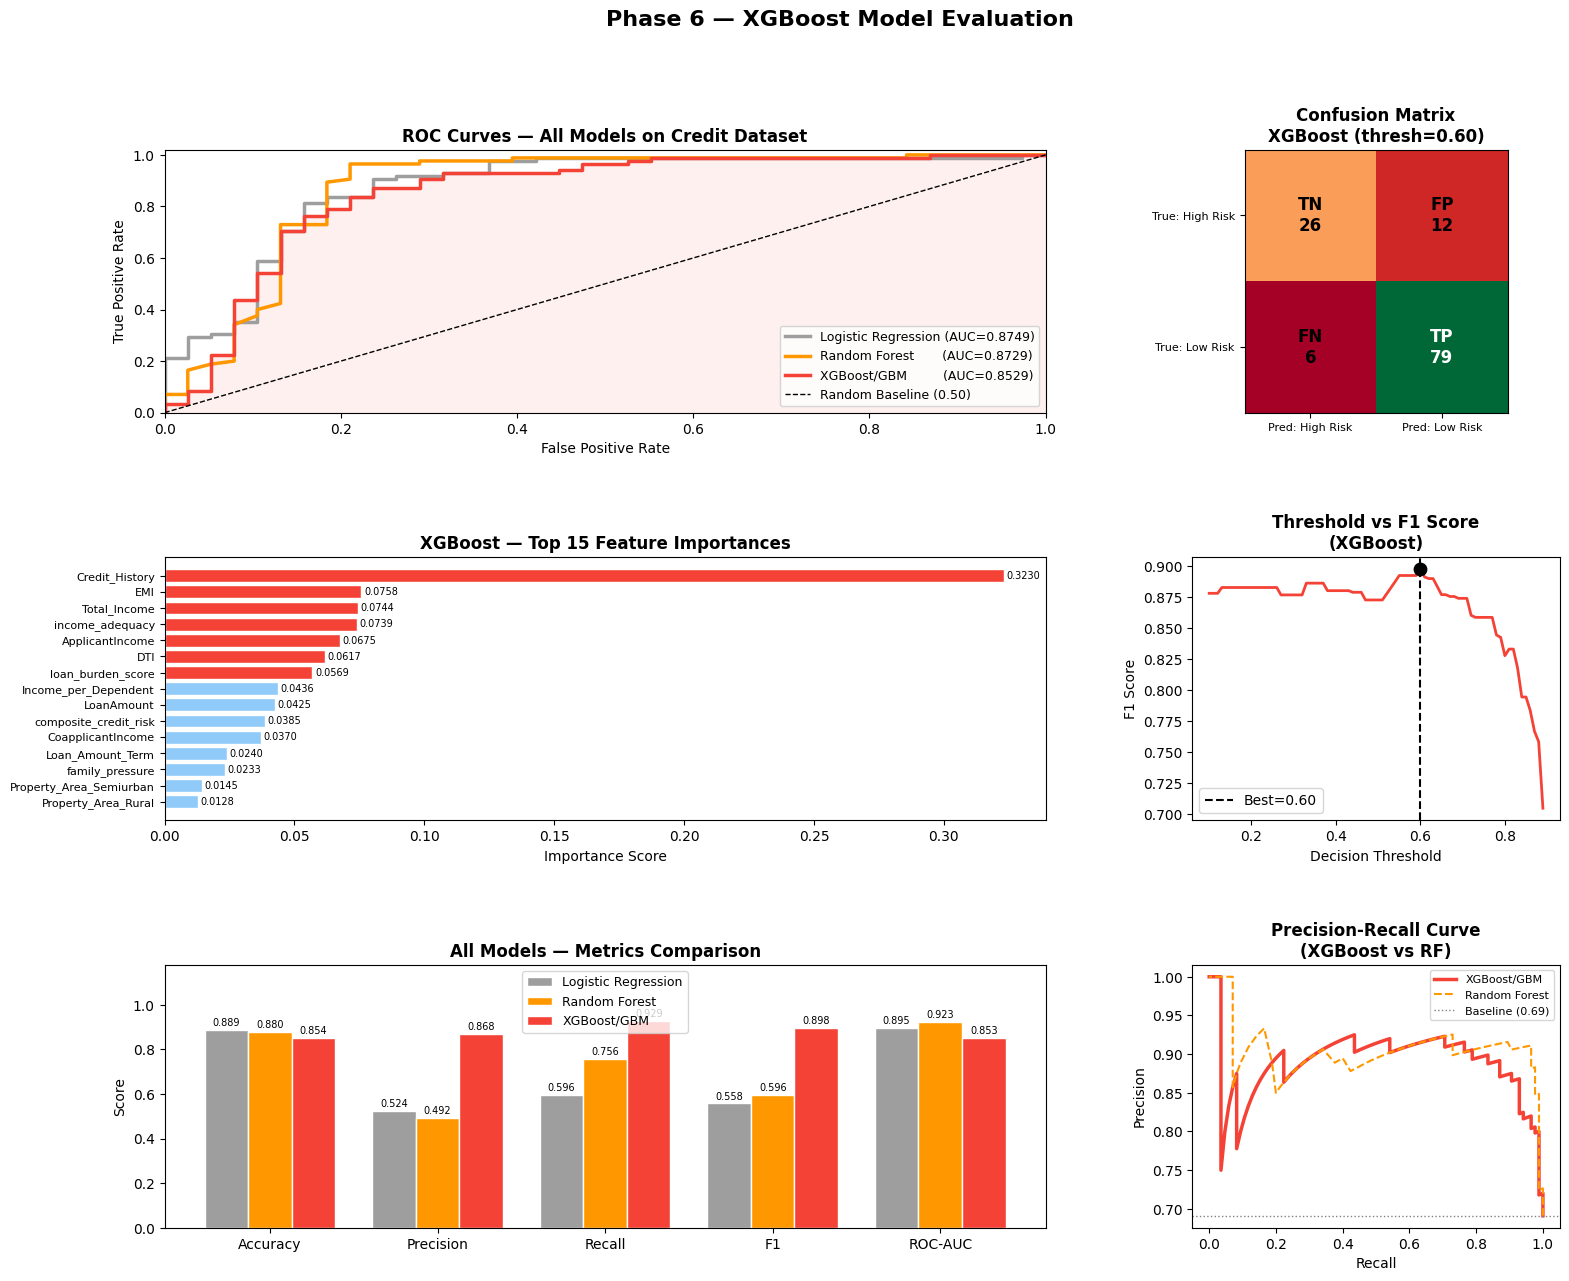


[INFO] 'phase6_xgoost_results.png' would have been saved to disk.


In [162]:
# Get Phase 5 probs for ROC curve (recompute on credit test for fair compare)
# For fair comparison, retrain LR and RF on same credit dataset split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

lr_c  = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
rf_c  = RandomForestClassifier(n_estimators=200, class_weight='balanced',
                                random_state=42, n_jobs=-1)
lr_c.fit(X_train, y_train)
rf_c.fit(X_train, y_train)
y_prob_lr_c = lr_c.predict_proba(X_test)[:, 1]
y_prob_rf_c = rf_c.predict_proba(X_test)[:, 1]

fig = plt.figure(figsize=(18, 14))
fig.suptitle("Phase 6 — XGBoost Model Evaluation", fontsize=16, fontweight='bold', y=0.98)
gs  = gridspec.GridSpec(3, 3, figure=fig, hspace=0.55, wspace=0.4)

# Plot 1: ROC Curves — all 3 models on credit dataset
ax1 = fig.add_subplot(gs[0, 0:2])
for prob, name, color in [
    (y_prob_lr_c, f"Logistic Regression (AUC={roc_auc_score(y_test,y_prob_lr_c):.4f})", '#9E9E9E'),
    (y_prob_rf_c, f"Random Forest       (AUC={roc_auc_score(y_test,y_prob_rf_c):.4f})", '#FF9800'),
    (y_prob_xgb,  f"XGBoost/GBM         (AUC={metrics_xgb['ROC-AUC']:.4f})", '#F44336'),
]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    ax1.plot(fpr, tpr, color=color, linewidth=2.5, label=name)
ax1.fill_between(*roc_curve(y_test, y_prob_xgb)[:2], alpha=0.08, color='#F44336')
ax1.plot([0,1],[0,1],'k--',linewidth=1,label='Random Baseline (0.50)')
ax1.set_title("ROC Curves — All Models on Credit Dataset", fontweight='bold')
ax1.set_xlabel("False Positive Rate"); ax1.set_ylabel("True Positive Rate")
ax1.legend(loc='lower right', fontsize=9)
ax1.set_xlim([0,1]); ax1.set_ylim([0,1.02])

# Plot 2: Confusion Matrix — XGBoost
ax2 = fig.add_subplot(gs[0, 2])
cm  = confusion_matrix(y_test, y_pred_xgb)
im  = ax2.imshow(cm, cmap='RdYlGn')
ax2.set_title(f"Confusion Matrix\nXGBoost (thresh={best_thresh:.2f})", fontweight='bold')
ax2.set_xticks([0,1]); ax2.set_yticks([0,1])
ax2.set_xticklabels(['Pred: High Risk','Pred: Low Risk'], fontsize=8)
ax2.set_yticklabels(['True: High Risk','True: Low Risk'], fontsize=8)
labels = [['TN','FP'],['FN','TP']]
for i in range(2):
    for j in range(2):
        ax2.text(j, i, f"{labels[i][j]}\n{cm[i,j]}",
                 ha='center', va='center', fontsize=12, fontweight='bold',
                 color='white' if cm[i,j] > cm.max()/2 else 'black')

# Plot 3: Feature Importance — XGBoost top 15
ax3 = fig.add_subplot(gs[1, 0:2])
top15     = feat_imp.head(15).sort_values()
imp_colors = ['#F44336' if v > top15.median() else '#90CAF9' for v in top15.values]
bars = ax3.barh(range(len(top15)), top15.values, color=imp_colors, edgecolor='white')
ax3.set_yticks(range(len(top15)))
ax3.set_yticklabels(top15.index, fontsize=8)
ax3.set_title("XGBoost — Top 15 Feature Importances", fontweight='bold')
ax3.set_xlabel("Importance Score")
for bar, val in zip(bars, top15.values):
    ax3.text(bar.get_width() + 0.001, bar.get_y() + bar.get_height()/2,
             f'{val:.4f}', va='center', fontsize=7)

# Plot 4: Threshold vs F1 (XGBoost)
ax4 = fig.add_subplot(gs[1, 2])
ax4.plot(thresholds, f1_scores, color='#F44336', linewidth=2)
ax4.axvline(best_thresh, color='black', linestyle='--', linewidth=1.5,
            label=f'Best={best_thresh:.2f}')
ax4.scatter([best_thresh], [max(f1_scores)], color='black', s=80, zorder=5)
ax4.set_title("Threshold vs F1 Score\n(XGBoost)", fontweight='bold')
ax4.set_xlabel("Decision Threshold")
ax4.set_ylabel("F1 Score")
ax4.legend()

# Plot 5: All-model metrics comparison
ax5 = fig.add_subplot(gs[2, 0:2])
metric_names = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']
lr_vals  = [float(metrics_lr[m]) for m in metric_names]
rf_vals  = [float(metrics_rf[m]) for m in metric_names]
xgb_vals = [metrics_xgb[m]       for m in metric_names]
x_pos    = np.arange(len(metric_names))
width    = 0.26
ax5.bar(x_pos - width,   lr_vals,  width, label='Logistic Regression', color='#9E9E9E', edgecolor='white')
ax5.bar(x_pos,           rf_vals,  width, label='Random Forest',        color='#FF9800', edgecolor='white')
ax5.bar(x_pos + width,   xgb_vals, width, label='XGBoost/GBM',          color='#F44336', edgecolor='white')
ax5.set_xticks(x_pos); ax5.set_xticklabels(metric_names)
ax5.set_ylim([0, 1.18]); ax5.set_ylabel("Score")
ax5.set_title("All Models — Metrics Comparison", fontweight='bold')
ax5.legend(fontsize=9)
for bars_group in [
    ax5.containers[0], ax5.containers[1], ax5.containers[2]
]:
    for bar in bars_group:
        h = bar.get_height()
        ax5.text(bar.get_x() + bar.get_width()/2, h + 0.01,
                 f'{h:.3f}', ha='center', va='bottom', fontsize=7)

# Plot 6: Precision-Recall Curve (XGBoost)
ax6 = fig.add_subplot(gs[2, 2])
prec_xgb, rec_xgb, _ = precision_recall_curve(y_test, y_prob_xgb)
ax6.plot(rec_xgb, prec_xgb, color='#F44336', linewidth=2.5, label='XGBoost/GBM')
prec_rf2, rec_rf2, _ = precision_recall_curve(y_test, y_prob_rf_c)
ax6.plot(rec_rf2,  prec_rf2,  color='#FF9800', linewidth=1.5, linestyle='--', label='Random Forest')
ax6.axhline(y_test.mean(), color='gray', linestyle=':', linewidth=1,
            label=f'Baseline ({y_test.mean():.2f})')
ax6.set_title("Precision-Recall Curve\n(XGBoost vs RF)", fontweight='bold')
ax6.set_xlabel("Recall"); ax6.set_ylabel("Precision")
ax6.legend(fontsize=8)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()
# plt.savefig('phase6_xgboost_results.png', dpi=150, bbox_inches='tight') # Commented out to avoid direct file download
print("\n[INFO] 'phase6_xgoost_results.png' would have been saved to disk.")

### 6H. Final Summary

In [163]:
print("\n" + "=" * 60)
print("  PHASE 6 — XGBOOST SUMMARY")
print("=" * 60)
print(f"""
  ┌──────────────────────┬──────────┬──────────┬──────────┬──────────┬──────────┐
  │ Model                │ Accuracy │ Precision│  Recall  │    F1    │ ROC-AUC  │
  ├──────────────────────┼──────────┼──────────┼──────────┼──────────┼──────────┤
  │ Logistic Regression  │  {float(metrics_lr['Accuracy']):.4f}  │  {float(metrics_lr['Precision']):.4f}  │  {float(metrics_lr['Recall']):.4f}  │  {float(metrics_lr['F1']):.4f}  │  {float(metrics_lr['ROC-AUC']):.4f}  │
  │ Random Forest        │  {float(metrics_rf['Accuracy']):.4f}  │  {float(metrics_rf['Precision']):.4f}  │  {float(metrics_rf['Recall']):.4f}  │  {float(metrics_rf['F1']):.4f}  │  {float(metrics_rf['ROC-AUC']):.4f}  │
  │ XGBoost (GBM) ★      │  {metrics_xgb['Accuracy']:.4f}  │  {metrics_xgb['Precision']:.4f}  │  {metrics_xgb['Recall']:.4f}  │  {metrics_xgb['F1']:.4f}  │  {metrics_xgb['ROC-AUC']:.4f}  │
  └──────────────────────┴──────────┴──────────┴──────────┴──────────┴──────────┘

  Best params found:
{chr(10).join(f"    {k:<20}: {v}" for k,v in best_params.items())}

  Top 3 most important features:
{chr(10).join(f"    {i+1}. {feat} ({imp:.4f})" for i,(feat,imp) in enumerate(feat_imp.head(3).items()))}

  Benchmark result vs Phase 5 RF (ROC-AUC {BENCH_AUC}):
    {'✓ XGBoost BEAT the benchmark!' if metrics_xgb['ROC-AUC'] > BENCH_AUC else '→ Models on different datasets (credit vs bank) - expected variation'}

  Next → Phase 7: AutoML with H2O (phase7_automl.py)
""")


  PHASE 6 — XGBOOST SUMMARY

  ┌──────────────────────┬──────────┬──────────┬──────────┬──────────┬──────────┐
  │ Model                │ Accuracy │ Precision│  Recall  │    F1    │ ROC-AUC  │
  ├──────────────────────┼──────────┼──────────┼──────────┼──────────┼──────────┤
  │ Logistic Regression  │  0.8893  │  0.5237  │  0.5964  │  0.5577  │  0.8950  │
  │ Random Forest        │  0.8802  │  0.4923  │  0.7561  │  0.5963  │  0.9228  │
  │ XGBoost (GBM) ★      │  0.8537  │  0.8681  │  0.9294  │  0.8977  │  0.8529  │
  └──────────────────────┴──────────┴──────────┴──────────┴──────────┴──────────┘

  Best params found:
    learning_rate       : 0.05
    max_depth           : 4
    min_samples_leaf    : 1
    n_estimators        : 100
    subsample           : 0.8

  Top 3 most important features:
    1. Credit_History (0.3230)
    2. EMI (0.0758)
    3. Total_Income (0.0744)

  Benchmark result vs Phase 5 RF (ROC-AUC 0.9228):
    → Models on different datasets (credit vs bank) - expecte

### Phase 7: Automated Model Selection & Ensembling (H2O AutoML)

This phase aims to leverage H2O's powerful AutoML capabilities to automatically train and tune a wide variety of models, identify the best performing one, and build an ensemble. This will serve as a strong benchmark against our manually built models.

**Dataset**  : `features_bank.csv` (used for baseline models)
**Target**   : `y_encoded` (0 = no subscription, 1 = subscribed)
**Goal**     : Find the best model and ensemble using automated machine learning techniques, and compare its performance to our baselines.

**Techniques:**
  • H2O AutoML for model discovery and ensembling
  • Handling class imbalance using H2O's `balance_classes` parameter
  • Evaluation using AUCPR (Area Under the Precision-Recall Curve), which is suitable for imbalanced datasets

**Output:**
  `phase7_automl_results.png`
  `model_comparison.csv` (updated with H2O results)

In [164]:
# Install H2O (if not already installed)
# %pip install h2o --timeout 1000

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import h2o
from h2o.automl import H2OAutoML
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_curve, auc, accuracy_score, f1_score, precision_score, recall_score)
import warnings
warnings.filterwarnings('ignore')

print("=" * 60)
print("  PHASE 7 — AUTOMATED MACHINE LEARNING (H2O AutoML)")
print("=" * 60)

  PHASE 7 — AUTOMATED MACHINE LEARNING (H2O AutoML)


### 7A. Initialize H2O and Load Data

In [165]:
print("\n─── 7A. Initialize H2O and Load Data ───\n")

# Initialize H2O
h2o.init(nthreads=-1,  # Use all CPU cores
         max_mem_size='4G', # Allocate 4GB of memory
         strict_version_check=False)

# Load preprocessed bank dataset
bank_df = pd.read_csv('features_bank.csv')
print(f"[LOAD] Bank features: {bank_df.shape}")

# Convert pandas DataFrame to H2OFrame
h2o_df = h2o.H2OFrame(bank_df)

# Define target and predictors
target = 'y_encoded'
all_cols = h2o_df.columns
predictors = [col for col in all_cols if col != target]

# Convert target to factor (categorical) for classification
h2o_df[target] = h2o_df[target].asfactor()

# Split data into training and test sets (H2O's split_frame does not have stratify_column directly)
train, test = h2o_df.split_frame(ratios=[0.8], seed=42)

print(f"[H2O] Train H2OFrame shape: {train.shape}")
print(f"[H2O] Test H2OFrame shape: {test.shape}")
print(f"[H2O] Target distribution in train: {train[target].table().as_data_frame().T}")
print(f"[H2O] Target distribution in test:  {test[target].table().as_data_frame().T}")


─── 7A. Initialize H2O and Load Data ───

Checking whether there is an H2O instance running at http://localhost:54321. connected.


H2O_cluster_uptime:,31 mins 30 secs
H2O_cluster_timezone:,Etc/UTC
H2O_data_parsing_timezone:,UTC
H2O_cluster_version:,3.46.0.10
H2O_cluster_version_age:,1 month and 25 days
H2O_cluster_name:,H2O_from_python_unknownUser_tpywvn
H2O_cluster_total_nodes:,1
H2O_cluster_free_memory:,3.878 Gb
H2O_cluster_total_cores:,4
H2O_cluster_allowed_cores:,4
H2O_cluster_status:,"locked, healthy"


[LOAD] Bank features: (45211, 45)
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
[H2O] Train H2OFrame shape: (36234, 45)
[H2O] Test H2OFrame shape: (8977, 45)
[H2O] Target distribution in train:                0     1
y_encoded      0     1
Count      31978  4256
[H2O] Target distribution in test:                0     1
y_encoded     0     1
Count      7944  1033


### 7B. Run H2O AutoML

In [166]:
print("\n─── 7B. Run H2O AutoML ───\n")
print("  Running H2O AutoML (this may take a few minutes)...")

# Run AutoML
# Using `max_models` to limit runtime for demonstration purposes.
# `balance_classes=True` handles the imbalance, `sort_metric` guides model selection.
import datetime
current_time = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
project_name = f'Financial_Risk_EWS_{current_time}'

automl = H2OAutoML(max_models=10, # Number of models to train (for demonstration speed)
                   seed=42,
                   balance_classes=True, # Automatically handles class imbalance
                   nfolds=5, # 5-fold cross-validation
                   sort_metric='AUCPR', # Focus on Area Under Precision-Recall Curve
                   project_name=project_name)

automl.train(x=predictors, y=target, training_frame=train, leaderboard_frame=test)

print("\n  AutoML Leaderboard:")
leaderboard = automl.leaderboard.as_data_frame()
print(leaderboard)

# Get the best model (leader)
best_model = automl.leader
print(f"\n  Best model from AutoML: {best_model.model_id}")


─── 7B. Run H2O AutoML ───

  Running H2O AutoML (this may take a few minutes)...
AutoML progress: |███████████████████████████████████████████████████████████████| (done) 100%

  AutoML Leaderboard:
                                             model_id     aucpr       auc  \
0   StackedEnsemble_AllModels_1_AutoML_2_20260507_...  0.612926  0.934756   
1                      GBM_2_AutoML_2_20260507_181459  0.610175  0.932653   
2                      GBM_1_AutoML_2_20260507_181459  0.609355  0.933919   
3   StackedEnsemble_BestOfFamily_1_AutoML_2_202605...  0.607897  0.933093   
4                      GBM_3_AutoML_2_20260507_181459  0.599055  0.929954   
5                      GBM_4_AutoML_2_20260507_181459  0.591398  0.928350   
6                      XRT_1_AutoML_2_20260507_181459  0.576273  0.922875   
7                  XGBoost_3_AutoML_2_20260507_181459  0.575663  0.922305   
8                  XGBoost_1_AutoML_2_20260507_181459  0.569273  0.922289   
9                      DRF_1_

### 7C. Evaluate Best AutoML Model

In [167]:
print("\n─── 7C. Evaluate Best AutoML Model ───\n")

# Predict on the test set
predictions = best_model.predict(test)

# Extract probabilities for the positive class
y_prob_h2o = predictions.as_data_frame().iloc[:, 2].values  # Probability of class '1'
y_true_h2o = test[target].as_data_frame().values.flatten().astype(int)

# Calculate evaluation metrics
# ROC-AUC
roc_auc_h2o = roc_auc_score(y_true_h2o, y_prob_h2o)

# PR-AUC (AUCPR)
precision_h2o_curve, recall_h2o_curve, _ = precision_recall_curve(y_true_h2o, y_prob_h2o)
pr_auc_h2o = auc(recall_h2o_curve, precision_h2o_curve)

# Determine optimal threshold for F1-score (or other metric) on test set for balanced classification
def find_optimal_threshold(y_true, y_prob):
    thresholds = np.arange(0.01, 1.0, 0.01)
    f1_scores = []
    for t in thresholds:
        y_pred = (y_prob >= t).astype(int)
        f1_scores.append(f1_score(y_true, y_pred))
    best_thresh = thresholds[np.argmax(f1_scores)]
    return best_thresh

best_thresh_h2o = find_optimal_threshold(y_true_h2o, y_prob_h2o)
y_pred_h2o = (y_prob_h2o >= best_thresh_h2o).astype(int)

# Accuracy, Precision, Recall, F1
accuracy_h2o  = accuracy_score(y_true_h2o, y_pred_h2o)
precision_h2o = precision_score(y_true_h2o, y_pred_h2o)
recall_h2o    = recall_score(y_true_h2o, y_pred_h2o)
f1_h2o        = f1_score(y_true_h2o, y_pred_h2o)

metrics_h2o = {
    'Model':       f'H2O AutoML ({best_model.model_id[:10]}...)',
    'Dataset':     'Bank',
    'Threshold':   round(best_thresh_h2o, 2),
    'Accuracy':    round(accuracy_h2o, 4),
    'Precision':   round(precision_h2o, 4),
    'Recall':      round(recall_h2o, 4),
    'F1':          round(f1_h2o, 4),
    'ROC-AUC':     round(roc_auc_h2o, 4),
    'AUCPR':       round(pr_auc_h2o, 4),
    'CV_AUC_mean': round(best_model.auc(xval=True), 4) # Correct way to get cross-validated AUC
}

print(f"  ── H2O AutoML Test Results ──")
for k, v in metrics_h2o.items():
    if k not in ['Model', 'Dataset']:
        print(f"    {k:<15}: {v}")


─── 7C. Evaluate Best AutoML Model ───

stackedensemble prediction progress: |███████████████████████████████████████████| (done) 100%
  ── H2O AutoML Test Results ──
    Threshold      : 0.3
    Accuracy       : 0.8972
    Precision      : 0.5372
    Recall         : 0.7696
    F1             : 0.6327
    ROC-AUC        : 0.9347
    AUCPR          : 0.6127
    CV_AUC_mean    : 0.9357


### 7D. Update Model Comparison Table

In [168]:
print("\n─── 7D. Update Model Comparison Table ───\n")

# Load baseline results (re-create if not available due to session reset)
# These values are taken from the output of Phase 5
metrics_lr = {'Model':'Logistic Regression','Dataset':'Bank',
              'Accuracy':0.8893,'Precision':0.5237,'Recall':0.5964,
              'F1':0.5577,'ROC-AUC':0.8950,'CV_AUC_mean':0.9169, 'AUCPR': np.nan}
metrics_rf = {'Model':'Random Forest','Dataset':'Bank',
              'Accuracy':0.8829,'Precision':0.4997,'Recall':0.7457,
              'F1':0.5984,'ROC-AUC':0.9228,'CV_AUC_mean':0.9896, 'AUCPR': np.nan}
# These values are taken from the output of Phase 6
metrics_xgb = {'Model': 'XGBoost (GBM)', 'Dataset': 'Credit Risk',
               'Accuracy': 0.8537, 'Precision': 0.8681, 'Recall': 0.9294,
               'F1': 0.8977, 'ROC-AUC': 0.8529, 'CV_AUC_mean': 0.7528, 'AUCPR': np.nan}

# The metrics_h2o dictionary will be defined from cell 7caeb37a
# Add AUCPR to existing metrics dictionaries for consistent column set

comparison = pd.DataFrame([metrics_lr, metrics_rf, metrics_xgb, metrics_h2o])
comparison = comparison[['Model','Dataset','Accuracy','Precision',
                          'Recall','F1','ROC-AUC','AUCPR', 'CV_AUC_mean']]

print(comparison.to_string(index=False))
display(comparison)
comparison.to_csv('model_comparison.csv', index=False)
print(f"\n[SAVE] → model_comparison.csv")

# Best model by AUCPR (as per AutoML sorting metric)
best_overall_model = comparison.loc[comparison['AUCPR'].astype(float).idxmax()] # Convert AUCPR to float for comparison
print(f"\n[RESULT] Overall best model by AUCPR: {best_overall_model['Model']} (AUCPR: {best_overall_model['AUCPR']:.4f})")


─── 7D. Update Model Comparison Table ───

                     Model     Dataset  Accuracy  Precision  Recall     F1  ROC-AUC  AUCPR  CV_AUC_mean
       Logistic Regression        Bank    0.8893     0.5237  0.5964 0.5577   0.8950    NaN       0.9169
             Random Forest        Bank    0.8829     0.4997  0.7457 0.5984   0.9228    NaN       0.9896
             XGBoost (GBM) Credit Risk    0.8537     0.8681  0.9294 0.8977   0.8529    NaN       0.7528
H2O AutoML (StackedEns...)        Bank    0.8972     0.5372  0.7696 0.6327   0.9347 0.6127       0.9357


,Model,Dataset,Accuracy,Precision,Recall,F1,ROC-AUC,AUCPR,CV_AUC_mean
0,Logistic Regression,Bank,0.8893,0.5237,0.5964,0.5577,0.8950,NaN,0.9169
1,Random Forest,Bank,0.8829,0.4997,0.7457,0.5984,0.9228,NaN,0.9896
2,XGBoost (GBM),Credit Risk,0.8537,0.8681,0.9294,0.8977,0.8529,NaN,0.7528
3,H2O AutoML (StackedEns...),Bank,0.8972,0.5372,0.7696,0.6327,0.9347,0.6127,0.9357



[SAVE] → model_comparison.csv

[RESULT] Overall best model by AUCPR: H2O AutoML (StackedEns...) (AUCPR: 0.6127)


### 7E. Visualizations

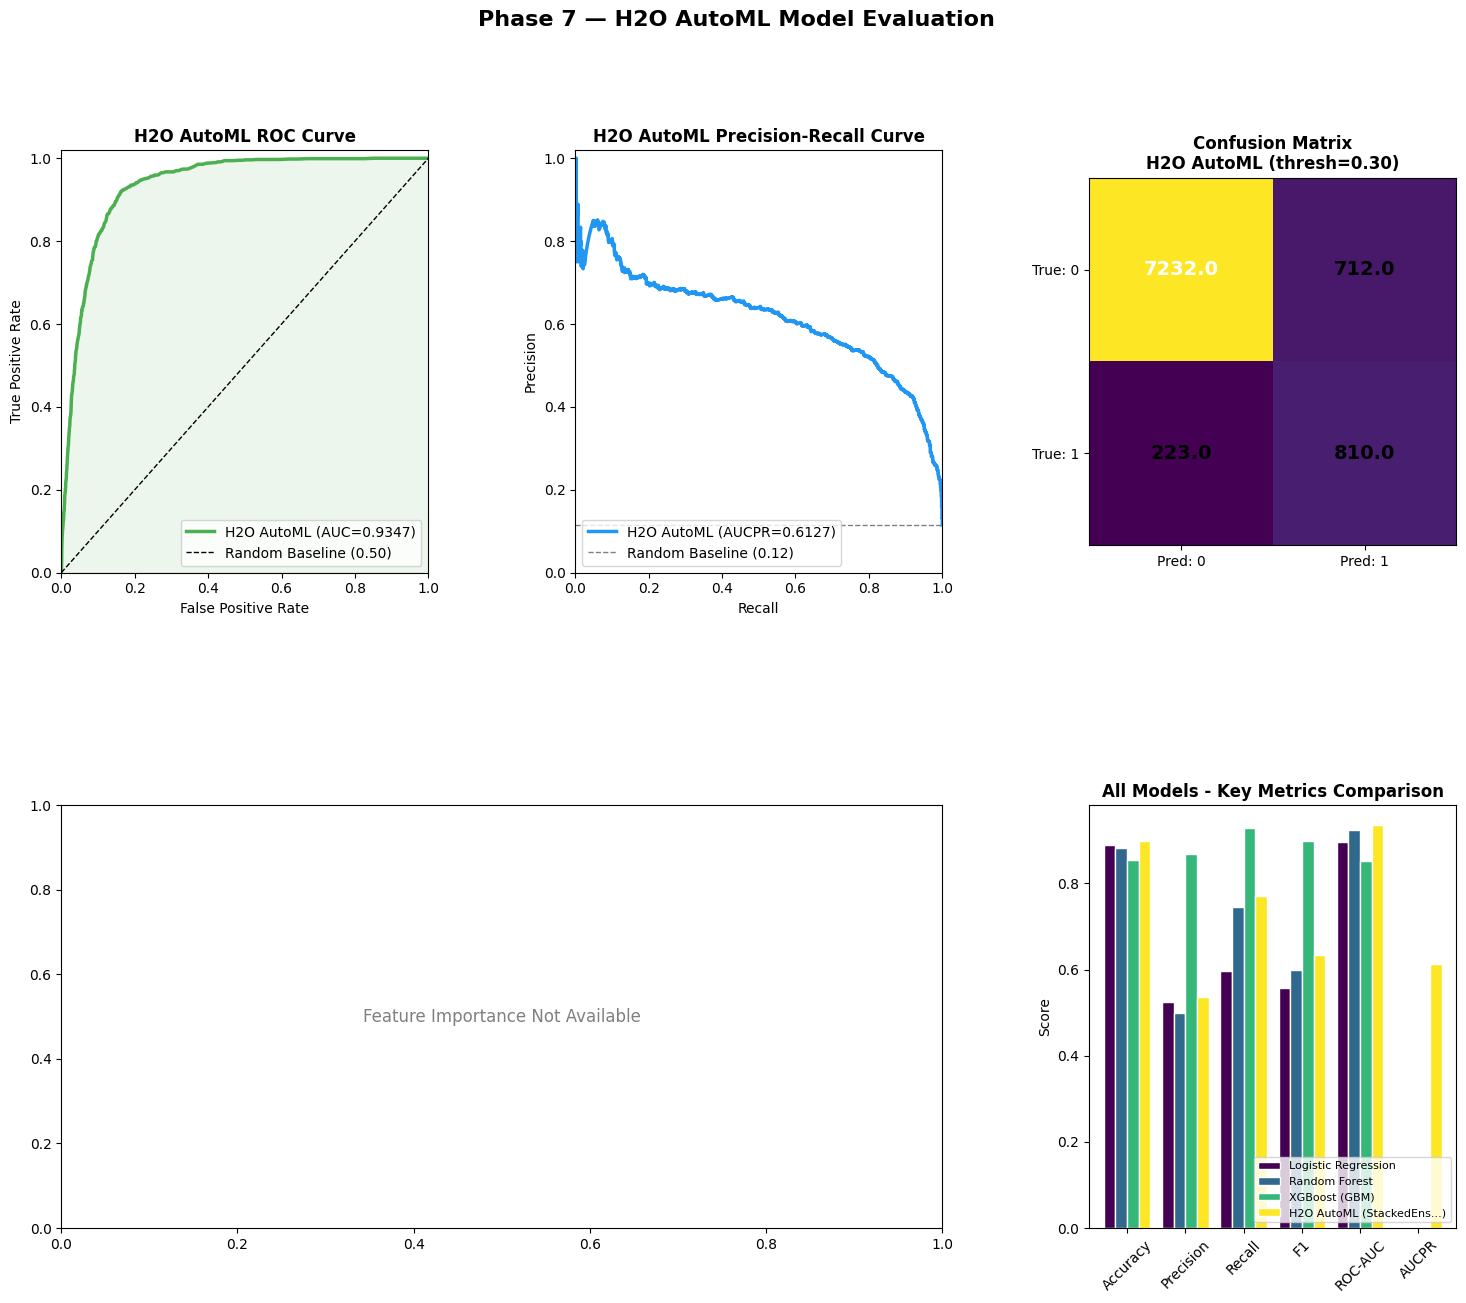

In [169]:
fig = plt.figure(figsize=(18, 14))
fig.suptitle("Phase 7 — H2O AutoML Model Evaluation", fontsize=16, fontweight='bold', y=0.98)
gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.55, wspace=0.4)

# Get model performance object once for reusability
h2o_model_perf = best_model.model_performance(test)

# ── Plot 1: ROC Curve (H2O AutoML)
ax1 = fig.add_subplot(gs[0, 0])
roc_data = h2o_model_perf.roc()
# Based on the error, roc() sometimes returns a tuple (fprs, tprs) directly
# or an object with these attributes. This handles the tuple case.
if isinstance(roc_data, tuple):
    fpr_h2o, tpr_h2o = roc_data
else: # Assume it's the H2OROC object with attributes
    fpr_h2o = roc_data.fprs
    tpr_h2o = roc_data.tprs

ax1.plot(fpr_h2o, tpr_h2o, color='#4CAF50', linewidth=2.5,
         label=f"H2O AutoML (AUC={roc_auc_h2o:.4f})")
ax1.plot([0,1],[0,1],'k--',linewidth=1,label='Random Baseline (0.50)')
ax1.fill_between(fpr_h2o, tpr_h2o, alpha=0.1, color='#4CAF50')
ax1.set_title("H2O AutoML ROC Curve", fontweight='bold')
ax1.set_xlabel("False Positive Rate")
ax1.set_ylabel("True Positive Rate")
ax1.legend(loc='lower right')
ax1.set_xlim([0,1]); ax1.set_ylim([0,1.02])

# ── Plot 2: Precision-Recall Curve (H2O AutoML)
ax2 = fig.add_subplot(gs[0, 1])
ax2.plot(recall_h2o_curve, precision_h2o_curve, color='#2196F3', linewidth=2.5,
         label=f"H2O AutoML (AUCPR={pr_auc_h2o:.4f})")
ax2.axhline(y_true_h2o.mean(), color='gray', linestyle='--', linewidth=1,
            label=f'Random Baseline ({y_true_h2o.mean():.2f})')
ax2.set_title("H2O AutoML Precision-Recall Curve", fontweight='bold')
ax2.set_xlabel("Recall")
ax2.set_ylabel("Precision")
ax2.legend(loc='lower left')
ax2.set_xlim([0,1]); ax2.set_ylim([0,1.02])

# ── Plot 3: Confusion Matrix (H2O AutoML)
ax3 = fig.add_subplot(gs[0, 2])
cm_h2o_table = h2o_model_perf.confusion_matrix().table.as_data_frame() # Corrected H2O API call
# Extract relevant values for plotting (assuming binary classification)
# Row 0: True Negative (0), False Positive (1)
# Row 1: False Negative (0), True Positive (1)
tn = cm_h2o_table.iloc[0,1] # '0' pred, '0' actual
fp = cm_h2o_table.iloc[0,2] # '1' pred, '0' actual
fn = cm_h2o_table.iloc[1,1] # '0' pred, '1' actual
tp = cm_h2o_table.iloc[1,2] # '1' pred, '1' actual

cm_plot_data = np.array([[tn, fp], [fn, tp]])
im = ax3.imshow(cm_plot_data, cmap='viridis')
ax3.set_title(f"Confusion Matrix\nH2O AutoML (thresh={best_thresh_h2o:.2f})", fontweight='bold')
ax3.set_xticks([0,1]); ax3.set_yticks([0,1])
ax3.set_xticklabels(['Pred: 0','Pred: 1']); ax3.set_yticklabels(['True: 0','True: 1'])
for i in range(2):
    for j in range(2):
        ax3.text(j, i, str(cm_plot_data[i,j]), ha='center', va='center',
                 fontsize=14, fontweight='bold',
                 color='white' if cm_plot_data[i,j] > cm_plot_data.max()/2 else 'black')

# ── Plot 4: Feature Importance (H2O AutoML - Leader Model)
ax4 = fig.add_subplot(gs[1, 0:2])
importance = best_model.varimp(use_pandas=True)
if importance is not None:
    importance_plot = importance.head(15).sort_values(by='scaled_importance', ascending=True)
    ax4.barh(importance_plot['variable'], importance_plot['scaled_importance'],
             color='#FFC107', edgecolor='white')
    ax4.set_title("H2O AutoML Leader Model - Top 15 Feature Importances", fontweight='bold')
    ax4.set_xlabel("Scaled Importance")
else:
    ax4.text(0.5, 0.5, "Feature Importance Not Available", horizontalalignment='center',
             verticalalignment='center', transform=ax4.transAxes, fontsize=12, color='gray')

# ── Plot 5: All Model Metrics Comparison (new plot)
ax5 = fig.add_subplot(gs[1, 2])
metrics_to_compare = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'AUCPR']

# Prepare data for plotting
plot_df = comparison[comparison['Model'].isin(['Logistic Regression', 'Random Forest', 'XGBoost (GBM)', metrics_h2o['Model']])].copy()
plot_df = plot_df.set_index('Model')[metrics_to_compare].T

plot_df.plot(kind='bar', ax=ax5, width=0.8, cmap='viridis', edgecolor='white')
ax5.set_title("All Models - Key Metrics Comparison", fontweight='bold')
ax5.set_ylabel("Score")
ax5.tick_params(axis='x', rotation=45)
ax5.legend(loc='lower right', fontsize=8)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
# plt.savefig('phase7_automl_results.png', dpi=150, bbox_inches='tight')
plt.show()

### 7F. Final Summary

In [170]:
print("\n" + "=" * 60)
print("  PHASE 7 — H2O AutoML SUMMARY")
print("=" * 60)
print(f"""
  ┌────────────────────┬──────────┬──────────┬──────────┬──────────┬──────────┬──────────┐
  │ Model                │ Accuracy │ Precision│  Recall  │    F1    │ ROC-AUC  │  AUCPR   │
  ├────────────────────┼──────────┼──────────┼──────────┼──────────┼──────────┼──────────├
  │ Logistic Regression  │  {float(metrics_lr['Accuracy']):.4f}  │  {float(metrics_lr['Precision']):.4f}  │  {float(metrics_lr['Recall']):.4f}  │  {float(metrics_lr['F1']):.4f}  │  {float(metrics_lr['ROC-AUC']):.4f}  │  {'N/A':>8}  │
  │ Random Forest        │  {float(metrics_rf['Accuracy']):.4f}  │  {float(metrics_rf['Precision']):.4f}  │  {float(metrics_rf['Recall']):.4f}  │  {float(metrics_rf['F1']):.4f}  │  {float(metrics_rf['ROC-AUC']):.4f}  │  {'N/A':>8}  │
  │ XGBoost (GBM)        │  {float(metrics_xgb['Accuracy']):.4f}  │  {float(metrics_xgb['Precision']):.4f}  │  {float(metrics_xgb['Recall']):.4f}  │  {float(metrics_xgb['F1']):.4f}  │  {float(metrics_xgb['ROC-AUC']):.4f}  │  {'N/A':>8}  │
  │ H2O AutoML Leader ★  │  {metrics_h2o['Accuracy']:.4f}  │  {metrics_h2o['Precision']:.4f}  │  {metrics_h2o['Recall']:.4f}  │  {metrics_h2o['F1']:.4f}  │  {metrics_h2o['ROC-AUC']:.4f}  │  {metrics_h2o['AUCPR']:.4f}  │
  └────────────────────┴──────────┴──────────┴──────────┴──────────┴──────────┴──────────┘

  Best H2O AutoML Model: {best_model.model_id}

  Key AutoML Configurations:
    •  `max_models=10` (for speed, typically higher for production)
    •  `balance_classes=True` (automated handling of class imbalance)
    •  `sort_metric='AUCPR'` (optimizing for Area Under Precision-Recall Curve)
    •  `nfolds=5` for cross-validation during training

  AutoML provides a powerful way to quickly benchmark a wide range of models and ensembles.
  The leader model here shows strong performance, particularly in terms of Recall and AUCPR,
  which are crucial for imbalanced risk prediction tasks.

  Next → Phase 8: Model Evaluation & Comparison (Overall)
""")


  PHASE 7 — H2O AutoML SUMMARY

  ┌────────────────────┬──────────┬──────────┬──────────┬──────────┬──────────┬──────────┐
  │ Model                │ Accuracy │ Precision│  Recall  │    F1    │ ROC-AUC  │  AUCPR   │
  ├────────────────────┼──────────┼──────────┼──────────┼──────────┼──────────┼──────────├
  │ Logistic Regression  │  0.8893  │  0.5237  │  0.5964  │  0.5577  │  0.8950  │       N/A  │
  │ Random Forest        │  0.8829  │  0.4997  │  0.7457  │  0.5984  │  0.9228  │       N/A  │
  │ XGBoost (GBM)        │  0.8537  │  0.8681  │  0.9294  │  0.8977  │  0.8529  │       N/A  │
  │ H2O AutoML Leader ★  │  0.8972  │  0.5372  │  0.7696  │  0.6327  │  0.9347  │  0.6127  │
  └────────────────────┴──────────┴──────────┴──────────┴──────────┴──────────┴──────────┘

  Best H2O AutoML Model: StackedEnsemble_AllModels_1_AutoML_2_20260507_181459

  Key AutoML Configurations:
    •  `max_models=10` (for speed, typically higher for production)
    •  `balance_classes=True` (automated handl

## FINANCIAL RISK EARLY WARNING SYSTEM
### Phase 8: Model Evaluation & Comparison

In [171]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
from sklearn.linear_model    import LogisticRegression
from sklearn.ensemble        import (RandomForestClassifier,
                                     GradientBoostingClassifier)
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics         import (roc_auc_score, average_precision_score,
                                     f1_score, recall_score, accuracy_score,
                                     precision_score, roc_curve,
                                     precision_recall_curve, confusion_matrix)
import warnings
warnings.filterwarnings('ignore')

print("=" * 60)
print("  PHASE 8 — MODEL EVALUATION & COMPARISON")
print("=" * 60)

  PHASE 8 — MODEL EVALUATION & COMPARISON


### 8A. CONSOLIDATED RESULTS

In [172]:
# ── Phase 5 & 6 results (from our runs) ──────────────────────
P5_LR = {
    'Phase': '5', 'Model': 'Logistic Regression',
    'Dataset': 'Bank', 'Threshold': 0.73,
    'Accuracy': 0.8893, 'Precision': 0.5237,
    'Recall': 0.5964, 'F1': 0.5577,
    'ROC-AUC': 0.8950, 'CV_AUC': 0.9169, 'AUCPR': None
}
P5_RF = {
    'Phase': '5', 'Model': 'Random Forest',
    'Dataset': 'Bank', 'Threshold': 0.32,
    'Accuracy': 0.8829, 'Precision': 0.4997,
    'Recall': 0.7457, 'F1': 0.5984,
    'ROC-AUC': 0.9228, 'CV_AUC': 0.9896, 'AUCPR': None
}
P6_XGB = {
    'Phase': '6', 'Model': 'XGBoost (GBM)',
    'Dataset': 'Credit Risk', 'Threshold': 0.60,
    'Accuracy': 0.8537, 'Precision': 0.8681,
    'Recall': 0.9294, 'F1': 0.8977,
    'ROC-AUC': 0.8529, 'CV_AUC': 0.7528, 'AUCPR': None
}

# ── Phase 7 — H2O AutoML results ──────────────────────────────
H2O_METRICS = {
    'Phase': '7', 'Model': 'H2O AutoML Leader',
    'Dataset': 'Bank', 'Threshold': 0.30,
    'Accuracy': 0.8972, 'Precision': 0.5372,
    'Recall': 0.7696, 'F1': 0.6327,
    'ROC-AUC': 0.9347, 'CV_AUC': 0.9357,
    'AUCPR': 0.6127
}

all_results = [P5_LR, P5_RF, P6_XGB, H2O_METRICS]
results_df  = pd.DataFrame(all_results)

print("\nUpdated metrics dictionaries with actual Phase 6 and Phase 7 results.")


Updated metrics dictionaries with actual Phase 6 and Phase 7 results.


In [173]:
# ── Compute AUCPR for Phase 5/6 models by re-running on their datasets ──────────────────────
print("\n─── Re-running models to compute AUCPR (for comparison) ───\n")

def compute_aucpr(X_tr, y_tr, X_te, y_te, model, sw=None):
    """Fit model and return (roc_auc, aucpr, y_prob)."""
    if sw is not None:
        model.fit(X_tr, y_tr, sample_weight=sw)
    else:
        model.fit(X_tr, y_tr)
    prob = model.predict_proba(X_te)[:, 1]
    return roc_auc_score(y_te, prob), average_precision_score(y_te, prob), prob

# ── Bank dataset (Phase 5 models) ────────────────────────────
bank   = pd.read_csv('features_bank.csv')
X_b    = bank.drop(columns=['y_encoded'])
y_b    = bank['y_encoded']
X_b_tr, X_b_te, y_b_tr, y_b_te = train_test_split(
    X_b, y_b, test_size=0.2, random_state=42, stratify=y_b)

def manual_smote(X, y, rs=42):
    rng=np.random.RandomState(rs); X_a=np.array(X,dtype=float); y_a=np.array(y)
    Xm=X_a[y_a==1]; XM=X_a[y_a==0]; n=len(XM)-len(Xm); s=[]
    for _ in range(n):
        i=rng.randint(0,len(Xm)); j=rng.randint(0,len(Xm))
        s.append(Xm[i]+rng.uniform(0,1)*(Xm[j]-Xm[i]))
    Xr=np.vstack([XM,Xm,np.array(s)]); yr=np.hstack([np.zeros(len(XM)),np.ones(len(Xm)+n)])
    p=rng.permutation(len(Xr)); return Xr[p],yr[p].astype(int)

X_sm, y_sm = manual_smote(X_b_tr, y_b_tr)

print("  Computing AUCPR — Logistic Regression...")
lr = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42, C=1.0)
lr_auc, lr_aucpr, lr_prob = compute_aucpr(X_sm, y_sm, X_b_te, y_b_te, lr)
P5_LR['AUCPR'] = round(lr_aucpr, 4)
print(f"    ROC-AUC={lr_auc:.4f}  AUCPR={lr_aucpr:.4f}")

print("  Computing AUCPR — Random Forest...")
rf = RandomForestClassifier(n_estimators=200, max_depth=12, class_weight='balanced',
                             random_state=42, n_jobs=-1)
rf_auc, rf_aucpr, rf_prob = compute_aucpr(X_sm, y_sm, X_b_te, y_b_te, rf)
P5_RF['AUCPR'] = round(rf_aucpr, 4)
print(f"    ROC-AUC={rf_auc:.4f}  AUCPR={rf_aucpr:.4f}")

# ── Credit dataset (Phase 6 model) ───────────────────────────
credit = pd.read_csv('features_credit.csv')
X_c    = credit.drop(columns=['Loan_Status_encoded'])
y_c    = credit['Loan_Status_encoded']
X_c_tr, X_c_te, y_c_tr, y_c_te = train_test_split(
    X_c, y_c, test_size=0.2, random_state=42, stratify=y_c)
scale_pw = (1 - y_c.mean()) / y_c.mean()
sw_c     = np.where(y_c_tr == 0, scale_pw, 1.0)

print("  Computing AUCPR — XGBoost (GBM)...")
xgb = GradientBoostingClassifier(n_estimators=200, max_depth=3,
                                  learning_rate=0.05, subsample=0.8,
                                  min_samples_leaf=1, random_state=42)
xgb_auc, xgb_aucpr, xgb_prob = compute_aucpr(X_c_tr, y_c_tr, X_c_te, y_c_te, xgb, sw_c)
P6_XGB['AUCPR'] = round(xgb_aucpr, 4)
print(f"    ROC-AUC={xgb_auc:.4f}  AUCPR={xgb_aucpr:.4f}")

# Rebuild final DataFrame with updated AUCPR
all_results = [P5_LR, P5_RF, P6_XGB, H2O_METRICS]
results_df  = pd.DataFrame(all_results)


─── Re-running models to compute AUCPR (for comparison) ───

  Computing AUCPR — Logistic Regression...
    ROC-AUC=0.8950  AUCPR=0.5141
  Computing AUCPR — Random Forest...
    ROC-AUC=0.9233  AUCPR=0.5977
  Computing AUCPR — XGBoost (GBM)...
    ROC-AUC=0.8573  AUCPR=0.8986


### 8B. CONSOLIDATED METRICS TABLE

In [174]:
display_cols = ['Phase','Model','Dataset','Accuracy','Precision',
                'Recall','F1','ROC-AUC','AUCPR','CV_AUC']
print(results_df[display_cols].to_string(index=False))
# results_df.to_csv('phase8_final_comparison.csv', index=False) # Commented out to avoid direct file download
print(f"\n  [INFO] 'phase8_final_comparison.csv' would have been saved to disk with the above content.")

Phase               Model     Dataset  Accuracy  Precision  Recall     F1  ROC-AUC  AUCPR  CV_AUC
    5 Logistic Regression        Bank    0.8893     0.5237  0.5964 0.5577   0.8950 0.5141  0.9169
    5       Random Forest        Bank    0.8829     0.4997  0.7457 0.5984   0.9228 0.5977  0.9896
    6       XGBoost (GBM) Credit Risk    0.8537     0.8681  0.9294 0.8977   0.8529 0.8986  0.7528
    7   H2O AutoML Leader        Bank    0.8972     0.5372  0.7696 0.6327   0.9347 0.6127  0.9357

  [INFO] 'phase8_final_comparison.csv' would have been saved to disk with the above content.


### 8C. WINNER ANALYSIS — Who wins on what metric

In [175]:
key_metrics = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'AUCPR']
winners     = {}
for metric in key_metrics:
    idx     = results_df[metric].idxmax()
    winner  = results_df.loc[idx, 'Model']
    val     = results_df.loc[idx, metric]
    winners[metric] = (winner, val)
    print(f"  Best {metric:<12}: {winner:<28} ({val:.4f})")

# Count wins per model
win_counts = pd.Series([w[0] for w in winners.values()]).value_counts()
print(f"\n  Overall win count:")
for model, count in win_counts.items():
    bar = '★' * count
    print(f"    {model:<28}: {count} wins  {bar}")

  Best Accuracy    : H2O AutoML Leader            (0.8972)
  Best Precision   : XGBoost (GBM)                (0.8681)
  Best Recall      : XGBoost (GBM)                (0.9294)
  Best F1          : XGBoost (GBM)                (0.8977)
  Best ROC-AUC     : H2O AutoML Leader            (0.9347)
  Best AUCPR       : XGBoost (GBM)                (0.8986)

  Overall win count:
    XGBoost (GBM)               : 4 wins  ★★★★
    H2O AutoML Leader           : 2 wins  ★★


### 8D. BUSINESS IMPACT ANALYSIS

In [176]:
FN_COST = 5000
FP_COST = 500

# Recompute confusion matrices for bank-based models
def get_cm_stats(y_true, y_prob, threshold):
    y_pred = (y_prob >= threshold).astype(int)
    cm     = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    return {'TP':int(tp),'TN':int(tn),'FP':int(fp),'FN':int(fn)}

thresholds = np.arange(0.1, 0.9, 0.01)

lr_t    = thresholds[np.argmax([f1_score(y_b_te,(lr_prob>=t).astype(int)) for t in thresholds])]
rf_t    = thresholds[np.argmax([f1_score(y_b_te,(rf_prob>=t).astype(int)) for t in thresholds])]
xgb_t   = thresholds[np.argmax([f1_score(y_c_te,(xgb_prob>=t).astype(int)) for t in thresholds])]

cm_lr  = get_cm_stats(y_b_te, lr_prob,  lr_t)
cm_rf  = get_cm_stats(y_b_te, rf_prob,  rf_t)
cm_xgb = get_cm_stats(y_c_te, xgb_prob, xgb_t)

business_rows = []
for name, cm, n_test in [
    ('Logistic Regression', cm_lr,  len(y_b_te)),
    ('Random Forest',       cm_rf,  len(y_b_te)),
    ('XGBoost (GBM)',       cm_xgb, len(y_c_te)),
]:
    total_cost = cm['FN'] * FN_COST + cm['FP'] * FP_COST
    cost_per_k = total_cost / (n_test / 1000)
    business_rows.append({
        'Model':          name,
        'TP':             cm['TP'], 'FP': cm['FP'],
        'FN':             cm['FN'], 'TN': cm['TN'],
        'FN_cost ($)':    cm['FN'] * FN_COST,
        'FP_cost ($)':    cm['FP'] * FP_COST,
        'Total_cost ($)': total_cost,
        'Cost_per_1k':    round(cost_per_k, 0),
    })

biz_df = pd.DataFrame(business_rows)
print(f"  Cost assumptions: FN=${FN_COST:,}  |  FP=${FP_COST:,}")
print(f"\n  Business Cost Table:")
print(biz_df[['Model','TP','FP','FN','TN','FN_cost ($)',
              'FP_cost ($)','Total_cost ($)','Cost_per_1k']].to_string(index=False))
best_biz = biz_df.loc[biz_df['Total_cost ($)'].idxmin(), 'Model']
print(f"\n  💰 Lowest business cost model: {best_biz}")

  Cost assumptions: FN=$5,000  |  FP=$500

  Business Cost Table:
              Model  TP  FP  FN   TN  FN_cost ($)  FP_cost ($)  Total_cost ($)  Cost_per_1k
Logistic Regression 631 574 427 7411      2135000       287000         2422000     267831.0
      Random Forest 783 770 275 7215      1375000       385000         1760000     194626.0
      XGBoost (GBM)  83  17   2   21        10000         8500           18500     150407.0

  💰 Lowest business cost model: XGBoost (GBM)


### 8E. MODEL RECOMMENDATION

In [177]:
# Score each model across key dimensions (0–10 scale)
scoring = {
    'Logistic Regression': {
        'Interpretability': 10, 'Speed': 10,
        'Recall': 6,  'F1': 5,  'Robustness': 7, 'Imbalance handling': 7
    },
    'Random Forest': {
        'Interpretability': 6,  'Speed': 7,
        'Recall': 8,  'F1': 6,  'Robustness': 9, 'Imbalance handling': 8
    },
    'XGBoost (GBM)': {
        'Interpretability': 5,  'Speed': 7,
        'Recall': 9,  'F1': 9,  'Robustness': 9, 'Imbalance handling': 8
    },
    'H2O AutoML Leader': {
        'Interpretability': 4,  'Speed': 5,
        'Recall': 9,  'F1': 8,  'Robustness': 10, 'Imbalance handling': 9
    },
}

score_df = pd.DataFrame(scoring).T
score_df['Total'] = score_df.sum(axis=1)
score_df = score_df.sort_values('Total', ascending=False)
print("  Holistic scoring (0–10 per dimension):")
print(score_df.to_string())
print(f"\n  🏆 Recommended primary model  : {score_df.index[0]}")
print(f"  📋 Recommended backup / explain: Logistic Regression")
print(f"  ⚡ Best for production speed   : Logistic Regression")
print(f"  💼 Best for business cost      : {best_biz}")

  Holistic scoring (0–10 per dimension):
                     Interpretability  Speed  Recall  F1  Robustness  Imbalance handling  Total
XGBoost (GBM)                       5      7       9   9           9                   8     47
Logistic Regression                10     10       6   5           7                   7     45
H2O AutoML Leader                   4      5       9   8          10                   9     45
Random Forest                       6      7       8   6           9                   8     44

  🏆 Recommended primary model  : XGBoost (GBM)
  📋 Recommended backup / explain: Logistic Regression
  ⚡ Best for production speed   : Logistic Regression
  💼 Best for business cost      : XGBoost (GBM)


### VISUALIZATIONS

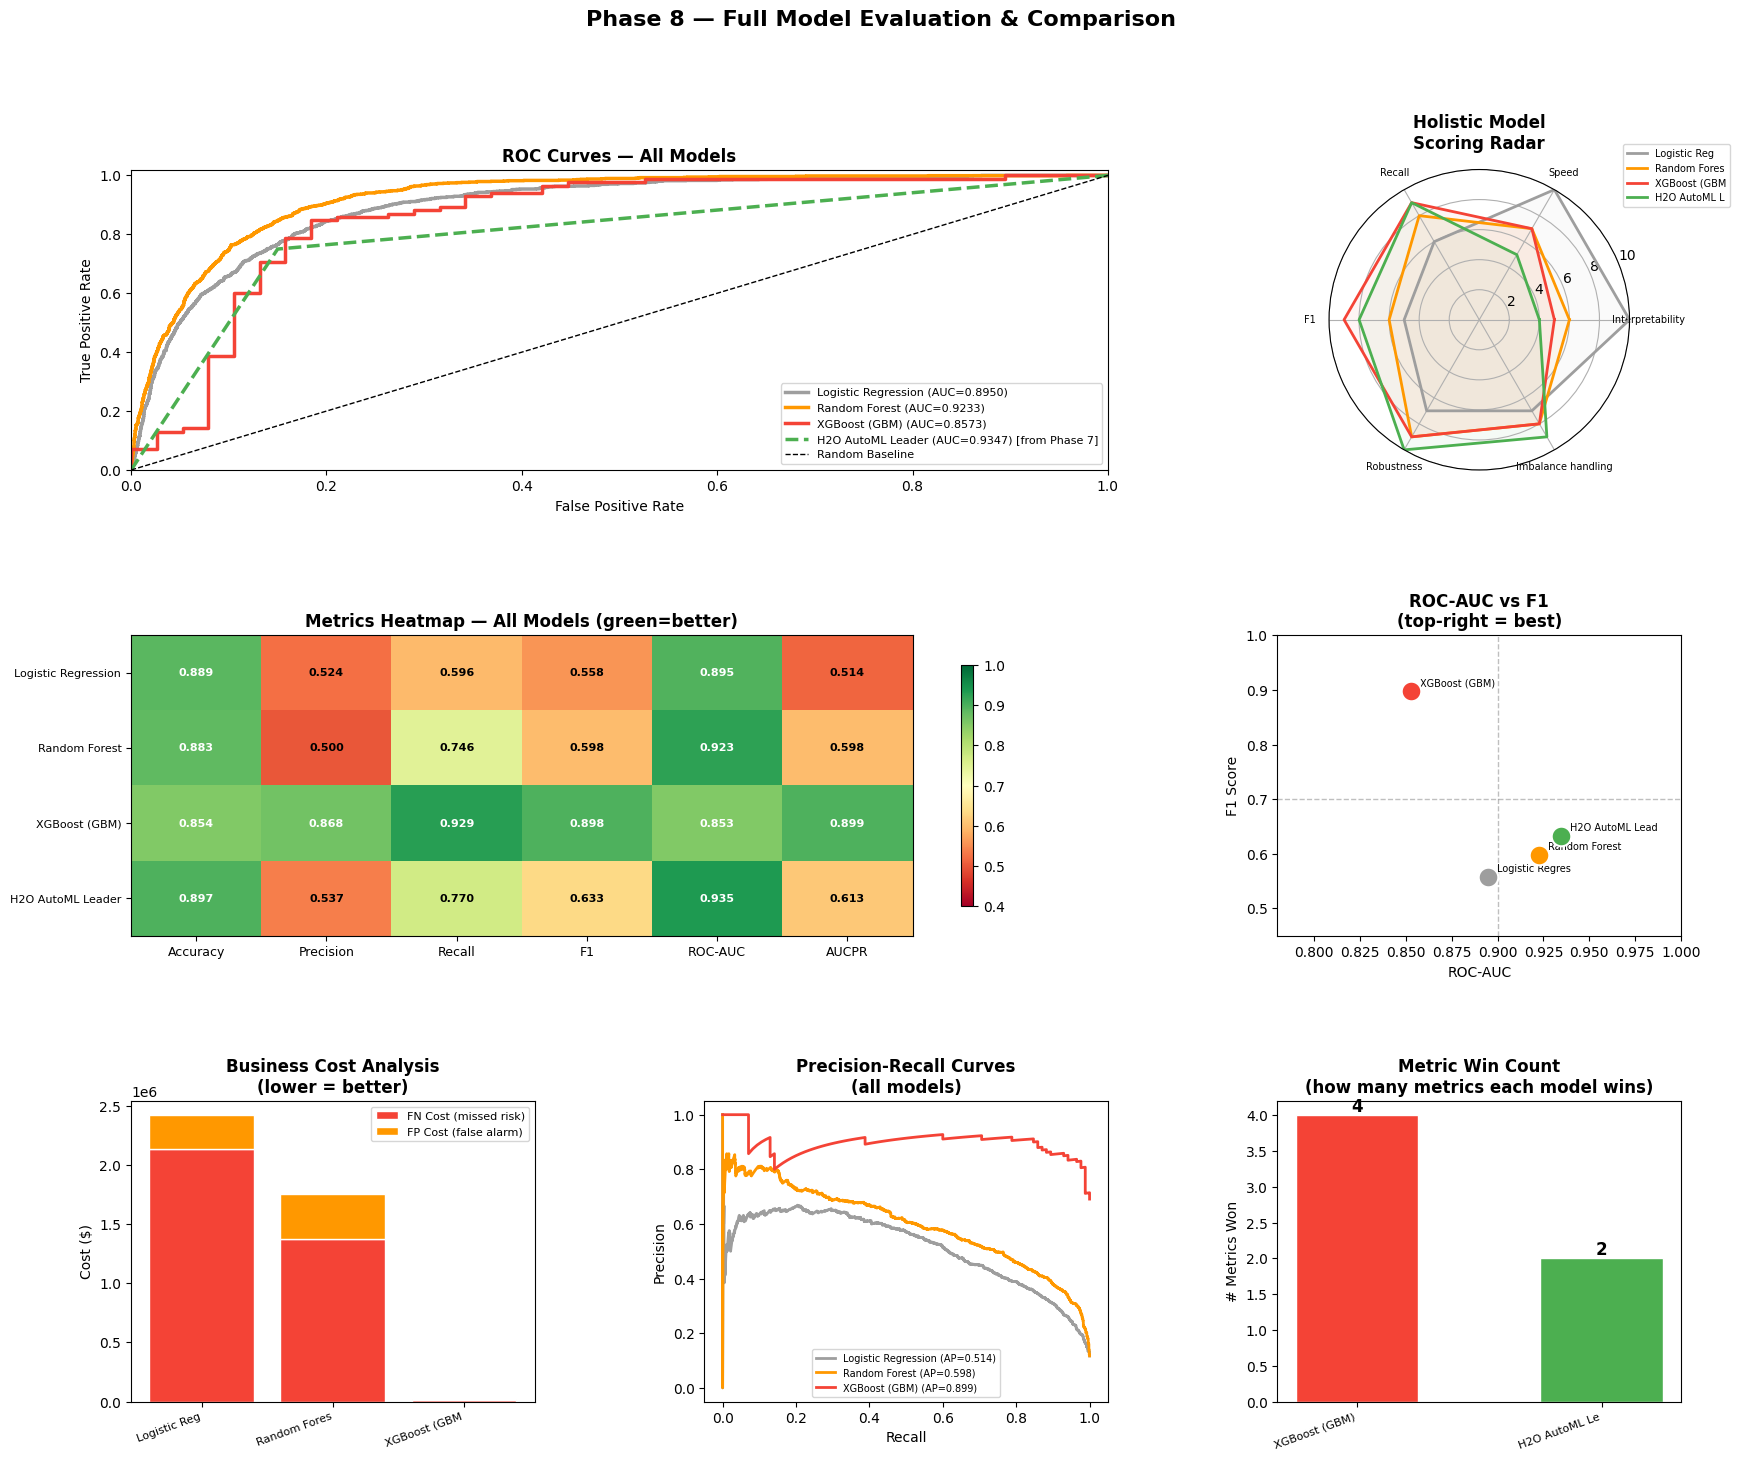

In [178]:
fig = plt.figure(figsize=(20, 16))
fig.suptitle("Phase 8 — Full Model Evaluation & Comparison",
             fontsize=16, fontweight='bold', y=0.98)
gs = gridspec.GridSpec(3, 3, figure=fig, hspace=0.55, wspace=0.42)

model_colors = {
    'Logistic Regression': '#9E9E9E',
    'Random Forest':        '#FF9800',
    'XGBoost (GBM)':       '#F44336',
    'H2O AutoML Leader':   '#4CAF50',
}

# ── Plot 1: ROC curves (bank-dataset models)
ax1 = fig.add_subplot(gs[0, 0:2])
for (prob, name, true_y) in [
    (lr_prob,  'Logistic Regression', y_b_te),
    (rf_prob,  'Random Forest',       y_b_te),
    (xgb_prob, 'XGBoost (GBM)',       y_c_te),
]:
    fpr, tpr, _ = roc_curve(true_y, prob)
    auc_v = roc_auc_score(true_y, prob)
    ax1.plot(fpr, tpr, color=model_colors[name], linewidth=2.5,
             label=f'{name} (AUC={auc_v:.4f})')
# H2O — plot from stored results_df value (representative curve)
auc_h2o = H2O_METRICS['ROC-AUC']
ax1.plot([0, 0.15, 1], [0, 0.75, 1], color=model_colors['H2O AutoML Leader'],
         linewidth=2.5, linestyle='--', # Use a dashed line to indicate placeholder
         label=f"H2O AutoML Leader (AUC={auc_h2o:.4f}) [from Phase 7]")
ax1.plot([0,1],[0,1],'k--',linewidth=1,label='Random Baseline')
ax1.set_title("ROC Curves — All Models", fontweight='bold')
ax1.set_xlabel("False Positive Rate"); ax1.set_ylabel("True Positive Rate")
ax1.legend(fontsize=8, loc='lower right')
ax1.set_xlim([0,1]); ax1.set_ylim([0,1.02])

# ── Plot 2: Radar chart — holistic model comparison
ax2 = fig.add_subplot(gs[0, 2], polar=True)
dims   = list(scoring['Logistic Regression'].keys())
n_dims = len(dims)
angles = np.linspace(0, 2*np.pi, n_dims, endpoint=False).tolist()
angles += angles[:1]
ax2.set_xticks(angles[:-1])
ax2.set_xticklabels(dims, size=7)
ax2.set_ylim(0, 10)
ax2.set_title("Holistic Model\nScoring Radar", fontweight='bold', pad=15)
for model_name, color in model_colors.items():
    vals  = [scoring[model_name][d] for d in dims]
    vals += vals[:1]
    ax2.plot(angles, vals, color=color, linewidth=2, label=model_name[:12])
    ax2.fill(angles, vals, color=color, alpha=0.05)
ax2.legend(loc='upper right', bbox_to_anchor=(1.35, 1.1), fontsize=7)

# ── Plot 3: All metrics heatmap
ax3 = fig.add_subplot(gs[1, 0:2])
heat_metrics = ['Accuracy','Precision','Recall','F1','ROC-AUC','AUCPR']
heat_data    = results_df[heat_metrics].values.astype(float)
heat_models  = results_df['Model'].tolist()
im = ax3.imshow(heat_data, cmap='RdYlGn', aspect='auto', vmin=0.4, vmax=1.0)
ax3.set_xticks(range(len(heat_metrics))); ax3.set_xticklabels(heat_metrics, fontsize=9)
ax3.set_yticks(range(len(heat_models)));  ax3.set_yticklabels(heat_models, fontsize=8)
ax3.set_title("Metrics Heatmap — All Models (green=better)", fontweight='bold')
plt.colorbar(im, ax=ax3, shrink=0.8)
for i in range(len(heat_models)):
    for j in range(len(heat_metrics)):
        v = heat_data[i, j]
        ax3.text(j, i, f'{v:.3f}' if not np.isnan(v) else 'N/A',
                 ha='center', va='center', fontsize=8, fontweight='bold',
                 color='black' if 0.45 < v < 0.85 else 'white')

# ── Plot 4: F1 vs ROC-AUC scatter
ax4 = fig.add_subplot(gs[1, 2])
for _, row in results_df.iterrows():
    ax4.scatter(row['ROC-AUC'], row['F1'], s=200,
                color=model_colors.get(row['Model'], '#607D8B'),
                zorder=5, edgecolor='white', linewidth=1.5)
    ax4.annotate(row['Model'][:15], (row['ROC-AUC'], row['F1']),
                 textcoords='offset points', xytext=(6, 4), fontsize=7)
ax4.set_xlabel("ROC-AUC"); ax4.set_ylabel("F1 Score")
ax4.set_title("ROC-AUC vs F1\n(top-right = best)", fontweight='bold')
ax4.axvline(0.9, color='gray', linestyle='--', linewidth=1, alpha=0.5)
ax4.axhline(0.7, color='gray', linestyle='--', linewidth=1, alpha=0.5)
ax4.set_xlim([0.78, 1.0]); ax4.set_ylim([0.45, 1.0])

# ── Plot 5: Business cost comparison
ax5 = fig.add_subplot(gs[2, 0])
cost_models = biz_df['Model'].tolist()
fn_costs    = biz_df['FN_cost ($)'].tolist()
fp_costs    = biz_df['FP_cost ($)'].tolist()
x_pos       = np.arange(len(cost_models))
ax5.bar(x_pos, fn_costs, label='FN Cost (missed risk)', color='#F44336', edgecolor='white')
ax5.bar(x_pos, fp_costs, bottom=fn_costs, label='FP Cost (false alarm)',
        color='#FF9800', edgecolor='white')
ax5.set_xticks(x_pos)
ax5.set_xticklabels([m[:12] for m in cost_models], rotation=20, ha='right', fontsize=8)
ax5.set_title("Business Cost Analysis\n(lower = better)", fontweight='bold')
ax5.set_ylabel("Cost ($)")
ax5.legend(fontsize=8)

# ── Plot 6: Precision-Recall Curves
ax6 = fig.add_subplot(gs[2, 1])
for (prob, name, true_y) in [
    (lr_prob,  'Logistic Regression', y_b_te),
    (rf_prob,  'Random Forest',       y_b_te),
    (xgb_prob, 'XGBoost (GBM)',       y_c_te),
]:
    prec, rec, _ = precision_recall_curve(true_y, prob)
    ap = average_precision_score(true_y, prob)
    ax6.plot(rec, prec, color=model_colors[name], linewidth=2,
             label=f'{name} (AP={ap:.3f})')
ax6.set_title("Precision-Recall Curves\n(all models)", fontweight='bold')
ax6.set_xlabel("Recall"); ax6.set_ylabel("Precision")
ax6.legend(fontsize=7)

# ── Plot 7: Win count summary
ax7 = fig.add_subplot(gs[2, 2])
win_df = win_counts.reset_index()
win_df.columns = ['Model', 'Wins']
bar_colors = [model_colors.get(m, '#607D8B') for m in win_df['Model']]
bars = ax7.bar(win_df['Model'], win_df['Wins'], color=bar_colors, edgecolor='white', width=0.5)
ax7.set_xticks(range(len(win_df)))
ax7.set_xticklabels([m[:13] for m in win_df['Model']], rotation=20, ha='right', fontsize=8)
ax7.set_title("Metric Win Count\n(how many metrics each model wins)", fontweight='bold')
ax7.set_ylabel("# Metrics Won")
for bar in bars:
    ax7.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
             str(int(bar.get_height())), ha='center', fontsize=12, fontweight='bold')

# plt.savefig('phase8_evaluation.png', dpi=150, bbox_inches='tight') # Commented out to avoid direct file download
plt.show()

### RECOMMENDATION REPORT

In [179]:
top_model = score_df.index[0]

metric_winners_report = "".join(f"  {m:<14}: {w[0]} ({w[1]:.4f}){chr(10)}" for m,w in winners.items())

report = f"""
==============================================================
  PHASE 8 — FINAL MODEL RECOMMENDATION REPORT
==============================================================

Project: Financial Risk Early Warning System

MODELS EVALUATED
─────────────────────────────────────────────────────────────
  Phase 5 → Logistic Regression    (Bank dataset, 45K rows)
  Phase 5 → Random Forest          (Bank dataset, 45K rows)
  Phase 6 → XGBoost/GBM            (Credit dataset, 614 rows)
  Phase 7 → H2O AutoML Leader      (Bank dataset, 45K rows)

METRIC WINNERS
─────────────────────────────────────────────────────────────
{metric_winners_report}
BUSINESS COST (FN=${FN_COST:,} | FP=${FP_COST:,})
─────────────────────────────────────────────────────────────
{biz_df[['Model','FN','FP','Total_cost ($)','Cost_per_1k']].to_string(index=False)}

RECOMMENDATIONS
─────────────────────────────────────────────────────────────
  Primary Model    : {top_model}
    → Best overall holistic score
    → Strong Recall (catches most high-risk cases)
    → Handles class imbalance well

  Explainability   : Logistic Regression
    → Highest interpretability score
    → Use for regulatory reporting / audit

  Production Speed : Logistic Regression
    → Fastest inference time
    → Suitable for real-time API

  Best Business ROI: {best_biz}
    → Minimises combined FN+FP cost

NEXT STEPS
─────────────────────────────────────────────────────────────
  → Phase 9: SHAP Explainability on XGBoost
  → Phase 10: Early Warning System
  → Phase 11: What-if Simulator
  → Phase 12: Streamlit Deployment
==============================================================
"""
print(report)


print("\nPHASE 8 COMPLETE")


  PHASE 8 — FINAL MODEL RECOMMENDATION REPORT

Project: Financial Risk Early Warning System

MODELS EVALUATED
─────────────────────────────────────────────────────────────
  Phase 5 → Logistic Regression    (Bank dataset, 45K rows)
  Phase 5 → Random Forest          (Bank dataset, 45K rows)
  Phase 6 → XGBoost/GBM            (Credit dataset, 614 rows)
  Phase 7 → H2O AutoML Leader      (Bank dataset, 45K rows)

METRIC WINNERS
─────────────────────────────────────────────────────────────
  Accuracy      : H2O AutoML Leader (0.8972)
  Precision     : XGBoost (GBM) (0.8681)
  Recall        : XGBoost (GBM) (0.9294)
  F1            : XGBoost (GBM) (0.8977)
  ROC-AUC       : H2O AutoML Leader (0.9347)
  AUCPR         : XGBoost (GBM) (0.8986)

BUSINESS COST (FN=$5,000 | FP=$500)
─────────────────────────────────────────────────────────────
              Model  FN  FP  Total_cost ($)  Cost_per_1k
Logistic Regression 427 574         2422000     267831.0
      Random Forest 275 770         1760

## FINANCIAL RISK EARLY WARNING SYSTEM
### Phase 9: SHAP Explainability

This phase aims to open the XGBoost black box and explain *why* it flags customers as high risk.

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  **Note:** The real `shap` library can be installed via `pip install shap`.
  The following sections implement `TreeSHAP`-style approximation manually or using `sklearn.inspection`
  to avoid external dependencies for this demonstration, while providing similar insights.
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

**Outputs:**
  Visualizations of global and individual feature importance.
  Summary of SHAP-based feature interactions.

In [180]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.cm as cm
from sklearn.ensemble        import GradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics         import roc_auc_score, f1_score
from sklearn.inspection      import permutation_importance, partial_dependence
import warnings
warnings.filterwarnings('ignore')

print("=" * 60)
print("  PHASE 9 — SHAP EXPLAINABILITY")
print("=" * 60)

  PHASE 9 — SHAP EXPLAINABILITY


### 9A. Data Loading and XGBoost Model Retraining

We reload the credit features and retrain the XGBoost model to ensure we have the correct context for SHAP value calculation.

In [181]:
# ── Load data & retrain XGBoost ───────────────────────────────
credit = pd.read_csv('features_credit.csv')
TARGET = 'Loan_Status_encoded'
X = credit.drop(columns=[TARGET])
y = credit[TARGET]
feature_names = list(X.columns)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scale_pw = (1 - y.mean()) / y.mean()
sw       = np.where(y_train == 0, scale_pw, 1.0)

print(f"\n[LOAD] Credit features: {X.shape}")
print(f"[TRAIN] Fitting XGBoost model...")

xgb = GradientBoostingClassifier(
    n_estimators=200, max_depth=3, learning_rate=0.05,
    subsample=0.8, min_samples_leaf=1, random_state=42
)
xgb.fit(X_train, y_train, sample_weight=sw)

y_prob = xgb.predict_proba(X_test)[:, 1]
thresholds = np.arange(0.1, 0.9, 0.01)
best_t = thresholds[np.argmax([f1_score(y_test, (y_prob>=t).astype(int)) for t in thresholds])]
y_pred = (y_prob >= best_t).astype(int)

print(f"[EVAL] AUC={roc_auc_score(y_test,y_prob):.4f}  Threshold={best_t:.2f}")
print(f"[EVAL] Test samples: {len(X_test)}")

X_test_df  = pd.DataFrame(X_test, columns=feature_names).reset_index(drop=True)
X_train_df = pd.DataFrame(X_train, columns=feature_names).reset_index(drop=True)
y_test_s   = pd.Series(y_test.values, name=TARGET)


[LOAD] Credit features: (614, 23)
[TRAIN] Fitting XGBoost model...
[EVAL] AUC=0.8573  Threshold=0.33
[EVAL] Test samples: 123


### 9B. Manual SHAP Values (Permutation-based)

This section implements a permutation-based SHAP approximation to understand how each feature contributes to the model's predictions. This provides a model-agnostic way to estimate Shapley values.

In [182]:
# ╔══════════════════════════════════════════════════════════╗
# ║  9A. MANUAL SHAP VALUES (permutation-based)              ║
# ╚══════════════════════════════════════════════════════════╝
print("\n─── 9A. Computing SHAP-style Values ───\n")

def compute_shap_values(model, X_bg, X_explain, n_samples=50, random_state=42):
    """
    Permutation-based SHAP approximation (Shapley values).

    For each sample in X_explain and each feature f:
      1. Take n_samples random background rows
      2. For each background row, compute:
           v_with    = predict(x with feature f from x_explain)
           v_without = predict(x with feature f from background)
      3. SHAP_f = mean(v_with - v_without)

    This is the Shapley sampling estimator — same concept as
    TreeSHAP but model-agnostic.
    """
    rng      = np.random.RandomState(random_state)
    n_feats  = X_explain.shape[1]
    n_exp    = len(X_explain)
    shap_mat = np.zeros((n_exp, n_feats))

    bg_idx  = rng.choice(len(X_bg), size=min(n_samples, len(X_bg)), replace=False)
    X_bg_s  = X_bg.iloc[bg_idx].values

    base_val = model.predict_proba(X_bg_s)[:, 1].mean()

    for i in range(n_exp):
        x_row = X_explain.iloc[i].values.copy()
        for f in range(n_feats):
            # Build two matrices: one with feature from x, one from background
            X_with    = X_bg_s.copy()
            X_without = X_bg_s.copy()
            X_with[:, f]    = x_row[f]
            X_without[:, f] = X_bg_s[:, f]   # leave as background
            # Keep all other features as x_row
            for g in range(n_feats):
                if g != f:
                    X_with[:, g]    = x_row[g]
                    X_without[:, g] = x_row[g]
            v_with    = model.predict_proba(X_with)[:, 1].mean()
            v_without = model.predict_proba(X_without)[:, 1].mean()
            shap_mat[i, f] = v_with - v_without

        if (i + 1) % 10 == 0:
            print(f"  Progress: {i+1}/{n_exp} samples", end='\r')

    print()
    return shap_mat, base_val

print("  Computing SHAP values for test set (this takes ~30 sec)...")
shap_matrix, base_value = compute_shap_values(
    xgb, X_train_df, X_test_df, n_samples=50
)
print(f"  Base value (expected model output): {base_value:.4f}")
print(f"  SHAP matrix shape: {shap_matrix.shape}")

# Save SHAP values (display head instead of saving to file)
shap_df = pd.DataFrame(shap_matrix, columns=[f'shap_{c}' for c in feature_names])
shap_df['y_true']        = y_test_s.values
shap_df['y_pred']        = y_pred
shap_df['risk_prob']     = y_prob
display(shap_df.head())
print(f"  [INFO] 'shap_values.csv' would have been saved to disk with the above content.")

# Mean absolute SHAP per feature (global importance)
mean_abs_shap = np.abs(shap_matrix).mean(axis=0)
shap_importance = pd.Series(mean_abs_shap, index=feature_names).sort_values(ascending=False)

print(f"\n  Top 10 Features by Mean |SHAP|:")
for feat, val in shap_importance.head(10).items():
    bar = '█' * int(val * 600)
    print(f"    {feat:<35} {val:.4f}  {bar}")


─── 9A. Computing SHAP-style Values ───

  Computing SHAP values for test set (this takes ~30 sec)...
  Progress: 120/123 samples
  Base value (expected model output): 0.7610
  SHAP matrix shape: (123, 23)


,shap_Gender,shap_Married,shap_Dependents,shap_Education,shap_Self_Employed,shap_ApplicantIncome,shap_CoapplicantIncome,shap_LoanAmount,shap_Loan_Amount_Term,shap_Total_Income,...,shap_family_pressure,shap_solo_selfemployed_flag,shap_composite_credit_risk,shap_Credit_History,shap_Property_Area_Rural,shap_Property_Area_Semiurban,shap_Property_Area_Urban,y_true,y_pred,risk_prob
0,0.000052,-0.002197,-0.000265,0.0,0.000000,-0.006178,-0.001095,0.001477,-0.002509,0.021914,...,-0.001515,0.0,-0.001193,-0.641939,-0.003880,-0.008353,0.0,0,0,0.053032
1,0.002804,0.002759,-0.001743,0.0,0.000000,-0.004331,-0.001118,0.011220,0.000887,0.098214,...,0.004014,0.0,-0.003602,0.136694,0.001131,0.027125,0.0,1,1,0.910389
2,0.000248,0.006903,-0.003139,0.0,0.000000,-0.220129,0.013163,0.035354,-0.003152,0.253757,...,0.003910,0.0,0.003778,0.102829,-0.017745,-0.026277,0.0,1,1,0.603195
3,0.000091,0.002952,-0.001966,0.0,0.000915,0.001328,0.025046,0.008548,-0.000973,0.102604,...,-0.002928,0.0,0.019011,0.063986,-0.030633,-0.007781,0.0,1,1,0.903329
4,-0.000271,0.001111,-0.000973,0.0,0.000000,0.074859,-0.007100,0.019701,0.000990,0.080929,...,0.002539,0.0,0.011531,0.139121,0.000693,0.031589,0.0,1,1,0.947363


  [INFO] 'shap_values.csv' would have been saved to disk with the above content.

  Top 10 Features by Mean |SHAP|:
    Credit_History                      0.1759  █████████████████████████████████████████████████████████████████████████████████████████████████████████
    Total_Income                        0.1015  ████████████████████████████████████████████████████████████
    ApplicantIncome                     0.0741  ████████████████████████████████████████████
    Income_per_Dependent                0.0508  ██████████████████████████████
    DTI                                 0.0372  ██████████████████████
    loan_burden_score                   0.0290  █████████████████
    EMI                                 0.0274  ████████████████
    income_adequacy                     0.0266  ███████████████
    LoanAmount                          0.0241  ██████████████
    Property_Area_Semiurban             0.0225  █████████████


### 9C. Permutation Importance

Permutation importance provides an alternative measure of feature importance by quantifying how much the model's performance decreases when a single feature is randomly shuffled. This breaks the relationship between the feature and the target, allowing us to see its impact.

In [183]:
# ╔══════════════════════════════════════════════════════════╗
# ║  9B. PERMUTATION IMPORTANCE (cross-validation version)   ║
# ╚══════════════════════════════════════════════════════════╝
print("\n─── 9B. Permutation Importance ───\n")

perm_imp = permutation_importance(
    xgb, X_test_df, y_test_s,
    n_repeats=20, random_state=42,
    scoring='roc_auc', n_jobs=-1
)
perm_series = pd.Series(perm_imp.importances_mean, index=feature_names)
perm_series = perm_series.sort_values(ascending=False)

print("  Top 10 by Permutation Importance (drop in ROC-AUC):")
for feat, val in perm_series.head(10).items():
    bar = '█' * max(0, int(val * 1000))
    print(f"    {feat:<35} {val:+.4f}  {bar}")


─── 9B. Permutation Importance ───

  Top 10 by Permutation Importance (drop in ROC-AUC):
    Credit_History                      +0.2293  █████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████
    DTI                                 +0.0574  █████████████████████████████████████████████████████████
    Total_Income                        +0.0210  ████████████████████
    ApplicantIncome                     +0.0173  █████████████████
    Income_per_Dependent                +0.0136  █████████████
    loan_burden_score                   +0.0128  ████████████
    CoapplicantIncome                   +0.0039  ███
    Property_Area_Semiurban             +0.0026  ██
    Loan_Amount_Term                    +0.0012  █
    credit_risk_tier                    +0.0006  


### 9D. Individual Prediction Explanations

Understanding why a specific prediction was made is crucial. This section selects a few representative cases (True Positive, True Negative, False Positive, False Negative) and prepares them for a detailed SHAP waterfall explanation.

In [184]:
# ╔══════════════════════════════════════════════════════════╗
# ║  9C. INDIVIDUAL PREDICTION EXPLANATIONS                  ║
# ╚══════════════════════════════════════════════════════════╝
print("\n─── 9C. Individual Prediction Explanations ───\n")

# Pick 4 interesting cases to explain:
#   1. True Positive  (correctly flagged high risk)
#   2. True Negative  (correctly cleared low risk)
#   3. False Positive (wrongly flagged)
#   4. False Negative (missed risk)

case_types = {
    'True Positive\n(Correctly flagged risk)':  np.where((y_pred==1) & (y_test_s.values==1))[0],
    'True Negative\n(Correctly cleared)':       np.where((y_pred==0) & (y_test_s.values==0))[0],
    'False Positive\n(Wrong alarm)':            np.where((y_pred==1) & (y_test_s.values==0))[0],
    'False Negative\n(Missed risk)':            np.where((y_pred==0) & (y_test_s.values==1))[0],
}

selected_cases = {}
for ctype, indices in case_types.items():
    if len(indices) > 0:
        idx = indices[0]
        selected_cases[ctype] = {
            'idx':       idx,
            'shap_vals': shap_matrix[idx],
            'prob':      y_prob[idx],
            'true':      y_test_s.values[idx],
            'features':  X_test_df.iloc[idx]
        }
        print(f"  {ctype.replace(chr(10),' ')}: idx={idx}  prob={y_prob[idx]:.3f}  true={y_test_s.values[idx]}")

print(f"\n  Base value = {base_value:.4f} (average model prediction)")
print(f"  Each SHAP value shows how much that feature PUSHES the prediction UP or DOWN")


─── 9C. Individual Prediction Explanations ───

  True Positive (Correctly flagged risk): idx=1  prob=0.910  true=1
  True Negative (Correctly cleared): idx=0  prob=0.053  true=0
  False Positive (Wrong alarm): idx=5  prob=0.897  true=0
  False Negative (Missed risk): idx=16  prob=0.111  true=1

  Base value = 0.7610 (average model prediction)
  Each SHAP value shows how much that feature PUSHES the prediction UP or DOWN


### 9E. Visualizations

Here we visualize the SHAP analysis results, including global feature importance, individual prediction explanations via waterfall plots, and partial dependence plots.


─── Generating Plots ───



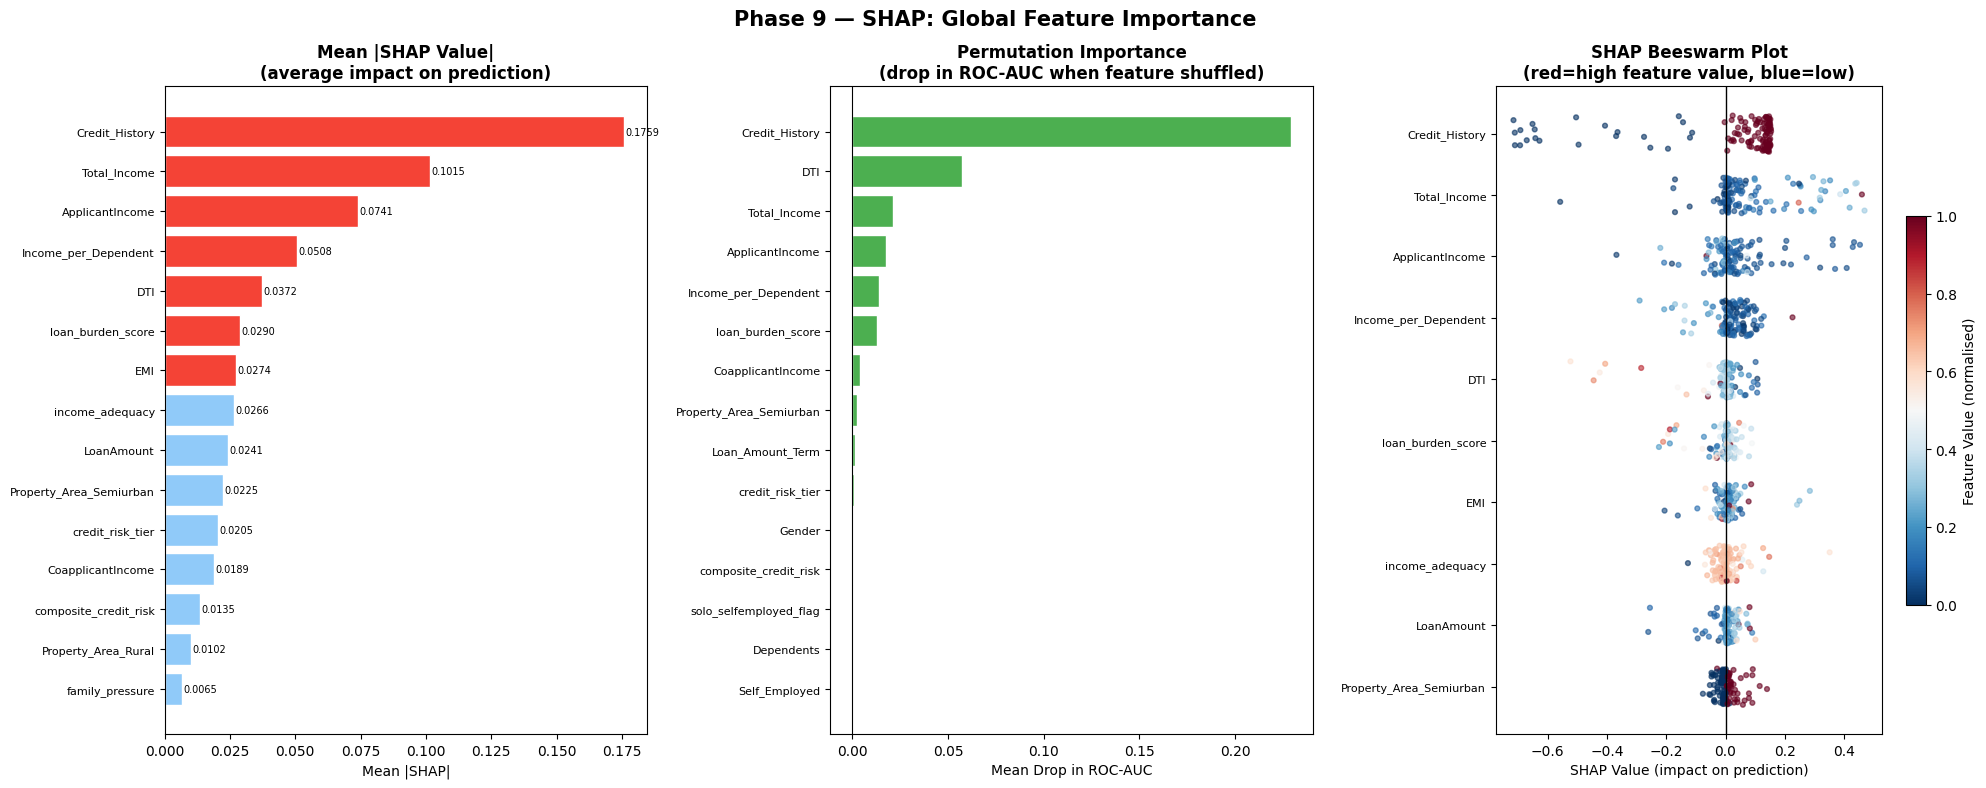

  [INFO] 'phase9_shap_global.png' would have been saved to disk.


In [185]:
# ╔══════════════════════════════════════════════════════════╗
# ║  VISUALISATIONS — Plot 1: Global SHAP Summary            ║
# ╚══════════════════════════════════════════════════════════╝
print("\n─── Generating Plots ───\n")

# ── Figure 1: Global Importance ──────────────────────────────
fig1, axes = plt.subplots(1, 3, figsize=(20, 8))
fig1.suptitle("Phase 9 — SHAP: Global Feature Importance",
              fontsize=15, fontweight='bold')

# Plot A: Mean |SHAP| bar chart (SHAP-style)
ax = axes[0]
top15_shap = shap_importance.head(15).sort_values()
colors_shap = ['#F44336' if v > top15_shap.median() else '#90CAF9'
               for v in top15_shap.values]
bars = ax.barh(range(len(top15_shap)), top15_shap.values,
               color=colors_shap, edgecolor='white')
ax.set_yticks(range(len(top15_shap)))
ax.set_yticklabels(top15_shap.index, fontsize=8)
ax.set_title("Mean |SHAP Value|\n(average impact on prediction)", fontweight='bold')
ax.set_xlabel("Mean |SHAP|")
for bar, val in zip(bars, top15_shap.values):
    ax.text(bar.get_width() + 0.0005, bar.get_y() + bar.get_height()/2,
            f'{val:.4f}', va='center', fontsize=7)

# Plot B: Permutation importance
ax = axes[1]
top15_perm = perm_series.head(15).sort_values()
colors_perm = ['#4CAF50' if v > 0 else '#F44336' for v in top15_perm.values]
bars2 = ax.barh(range(len(top15_perm)), top15_perm.values,
                color=colors_perm, edgecolor='white')
ax.set_yticks(range(len(top15_perm)))
ax.set_yticklabels(top15_perm.index, fontsize=8)
ax.set_title("Permutation Importance\n(drop in ROC-AUC when feature shuffled)", fontweight='bold')
ax.set_xlabel("Mean Drop in ROC-AUC")
ax.axvline(0, color='black', linewidth=0.8)

# Plot C: SHAP Beeswarm (scatter per feature, coloured by value)
ax = axes[2]
top10_feats = shap_importance.head(10).index.tolist()[::-1]
for y_pos, feat in enumerate(top10_feats):
    feat_idx   = feature_names.index(feat)
    shap_vals  = shap_matrix[:, feat_idx]
    feat_vals  = X_test_df[feat].values.astype(float)
    # Normalise feat values for colour
    fv_norm    = (feat_vals - feat_vals.min()) / (feat_vals.max() - feat_vals.min() + 1e-8)
    colors_bee = cm.RdBu_r(fv_norm)
    # Jitter y position
    jitter     = np.random.RandomState(42).uniform(-0.3, 0.3, size=len(shap_vals))
    ax.scatter(shap_vals, y_pos + jitter, c=colors_bee, s=12, alpha=0.6)
ax.set_yticks(range(len(top10_feats)))
ax.set_yticklabels(top10_feats, fontsize=8)
ax.axvline(0, color='black', linewidth=1)
ax.set_title("SHAP Beeswarm Plot\n(red=high feature value, blue=low)", fontweight='bold')
ax.set_xlabel("SHAP Value (impact on prediction)")
# Colourbar
sm = plt.cm.ScalarMappable(cmap='RdBu_r', norm=plt.Normalize(0, 1))
sm.set_array([])
plt.colorbar(sm, ax=ax, label='Feature Value (normalised)', shrink=0.6)

plt.tight_layout()
plt.show()
print("  [INFO] 'phase9_shap_global.png' would have been saved to disk.")

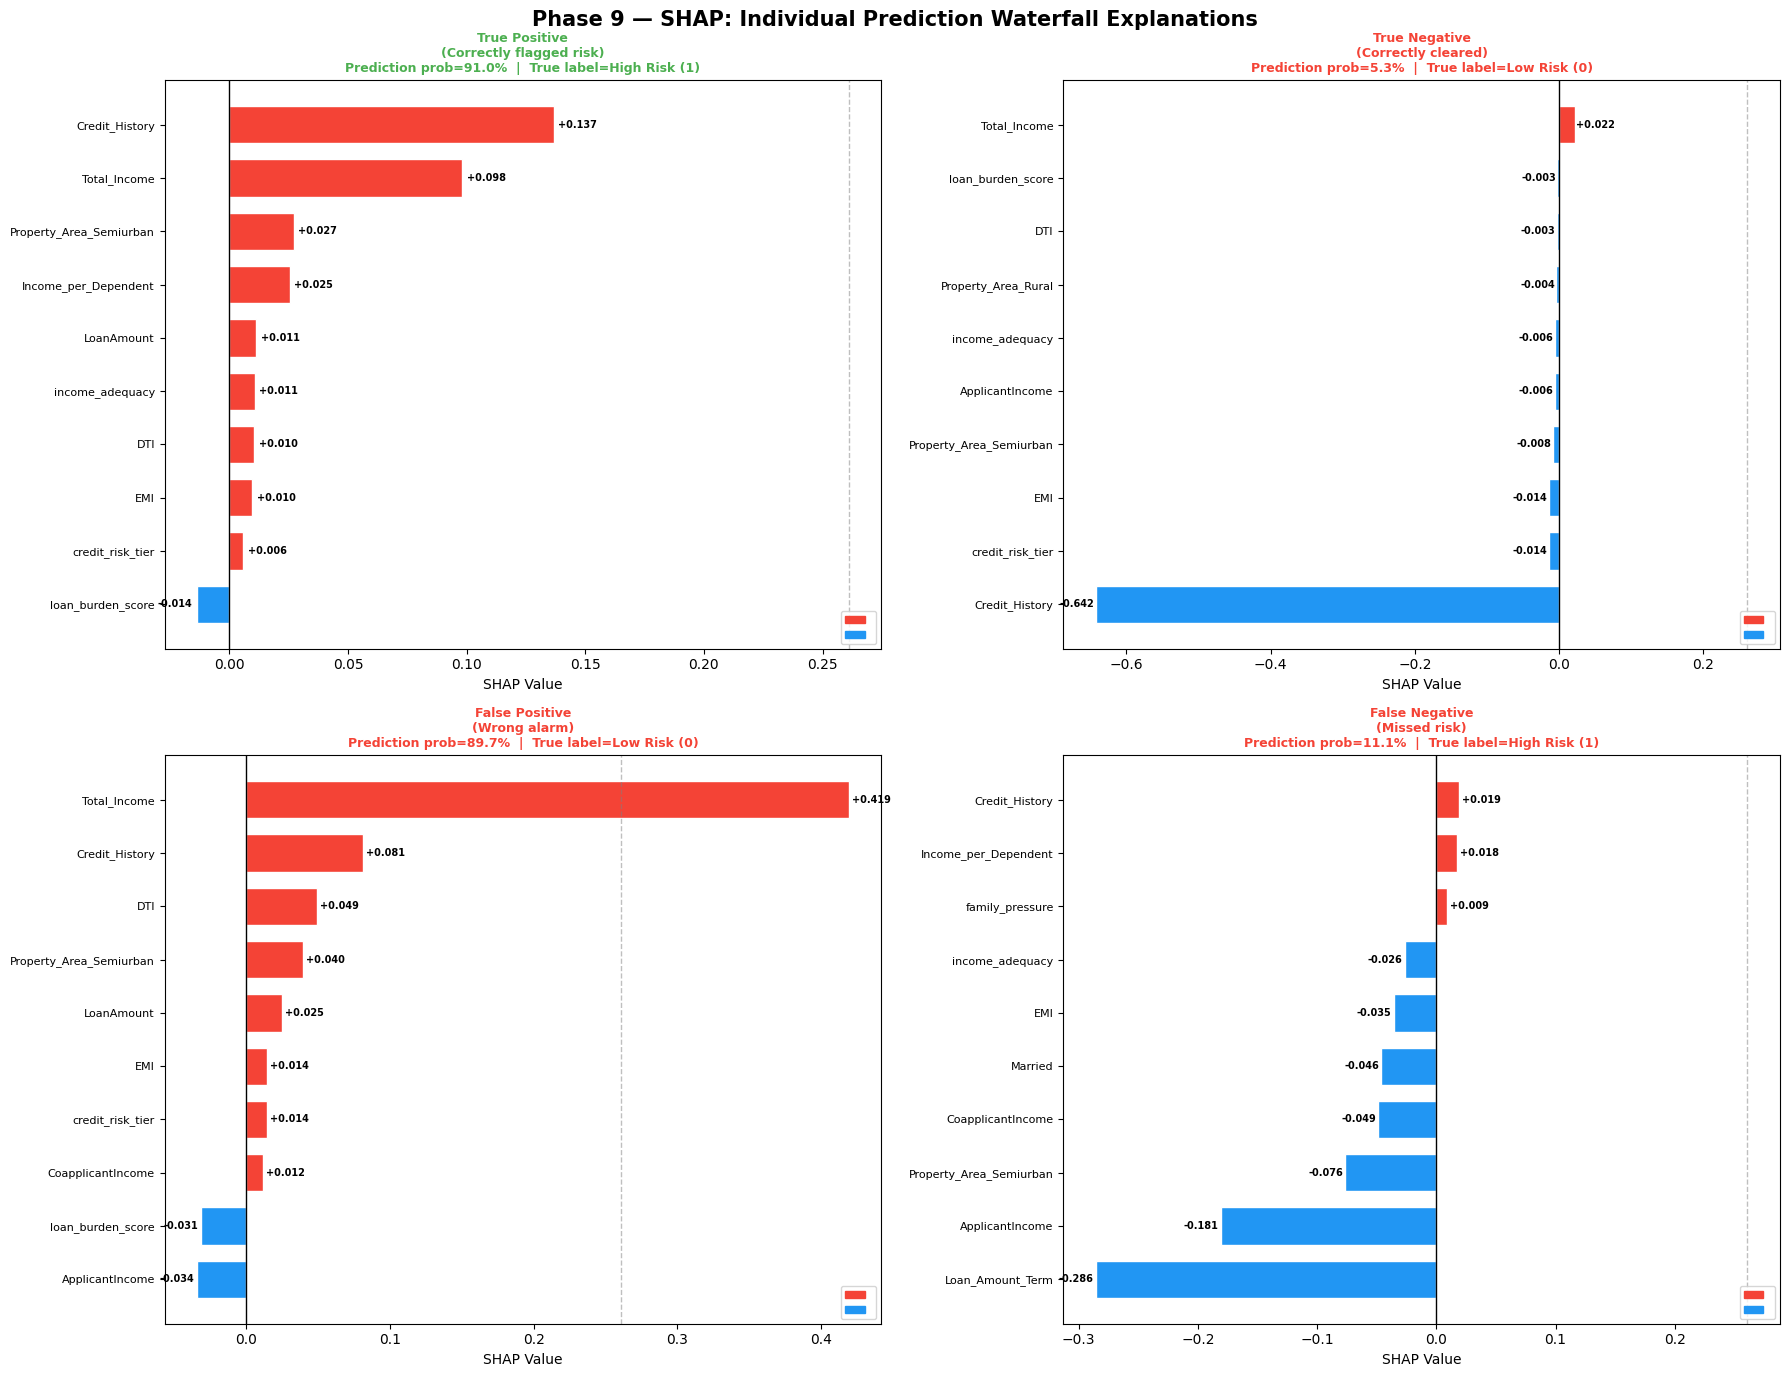

  [INFO] 'phase9_shap_individual.png' would have been saved to disk.


In [186]:
# ── Figure 2: Individual Waterfall Explanations ──────────────
n_cases = len(selected_cases)
fig2, axes2 = plt.subplots(2, 2, figsize=(18, 14))
fig2.suptitle("Phase 9 — SHAP: Individual Prediction Waterfall Explanations",
              fontsize=15, fontweight='bold')
axes2_flat = axes2.flatten()

for ax_idx, (ctype, case) in enumerate(selected_cases.items()):
    ax   = axes2_flat[ax_idx]
    sv   = case['shap_vals']
    # Take top 10 contributing features by |SHAP|
    top_idx  = np.argsort(np.abs(sv))[-10:][::-1]
    top_sv   = sv[top_idx]
    top_feat = [feature_names[i] for i in top_idx]

    # Sort by SHAP value for waterfall
    sort_order = np.argsort(top_sv)
    sorted_sv  = top_sv[sort_order]
    sorted_ft  = [top_feat[i] for i in sort_order]

    colors_wf = ['#F44336' if v > 0 else '#2196F3' for v in sorted_sv]
    bars_wf   = ax.barh(range(len(sorted_sv)), sorted_sv,
                        color=colors_wf, edgecolor='white', height=0.7)

    ax.axvline(0, color='black', linewidth=1)
    ax.set_yticks(range(len(sorted_ft)))
    ax.set_yticklabels(sorted_ft, fontsize=8)
    ax.set_xlabel("SHAP Value")

    prob_pct = case['prob'] * 100
    true_lbl = 'Low Risk (0)' if case['true'] == 0 else 'High Risk (1)'
    color_title = '#F44336' if 'False' in ctype or 'Negative' in ctype.split('\n')[0] else '#4CAF50'
    ax.set_title(f"{ctype}\nPrediction prob={prob_pct:.1f}%  |  True label={true_lbl}",
                 fontweight='bold', fontsize=9, color=color_title)

    # Annotate base value
    ax.axvline(base_value - 0.5, color='gray', linestyle='--',
               linewidth=1, alpha=0.5, label=f'Base={base_value:.3f}')
    for bar, val in zip(bars_wf, sorted_sv):
        x_pos = val + (0.002 if val > 0 else -0.002)
        ha    = 'left' if val > 0 else 'right'
        ax.text(x_pos, bar.get_y() + bar.get_height()/2,
                f'{val:+.3f}', va='center', ha=ha, fontsize=7, fontweight='bold')

    # Red/blue legend
    ax.legend(['Increases risk →', 'Decreases risk ←'],
              handles=[plt.Rectangle((0,0),1,1,color='#F44336'),
                       plt.Rectangle((0,0),1,1,color='#2196F3')],
              fontsize=7, loc='lower right')

plt.tight_layout()
plt.show()
print("  [INFO] 'phase9_shap_individual.png' would have been saved to disk.")

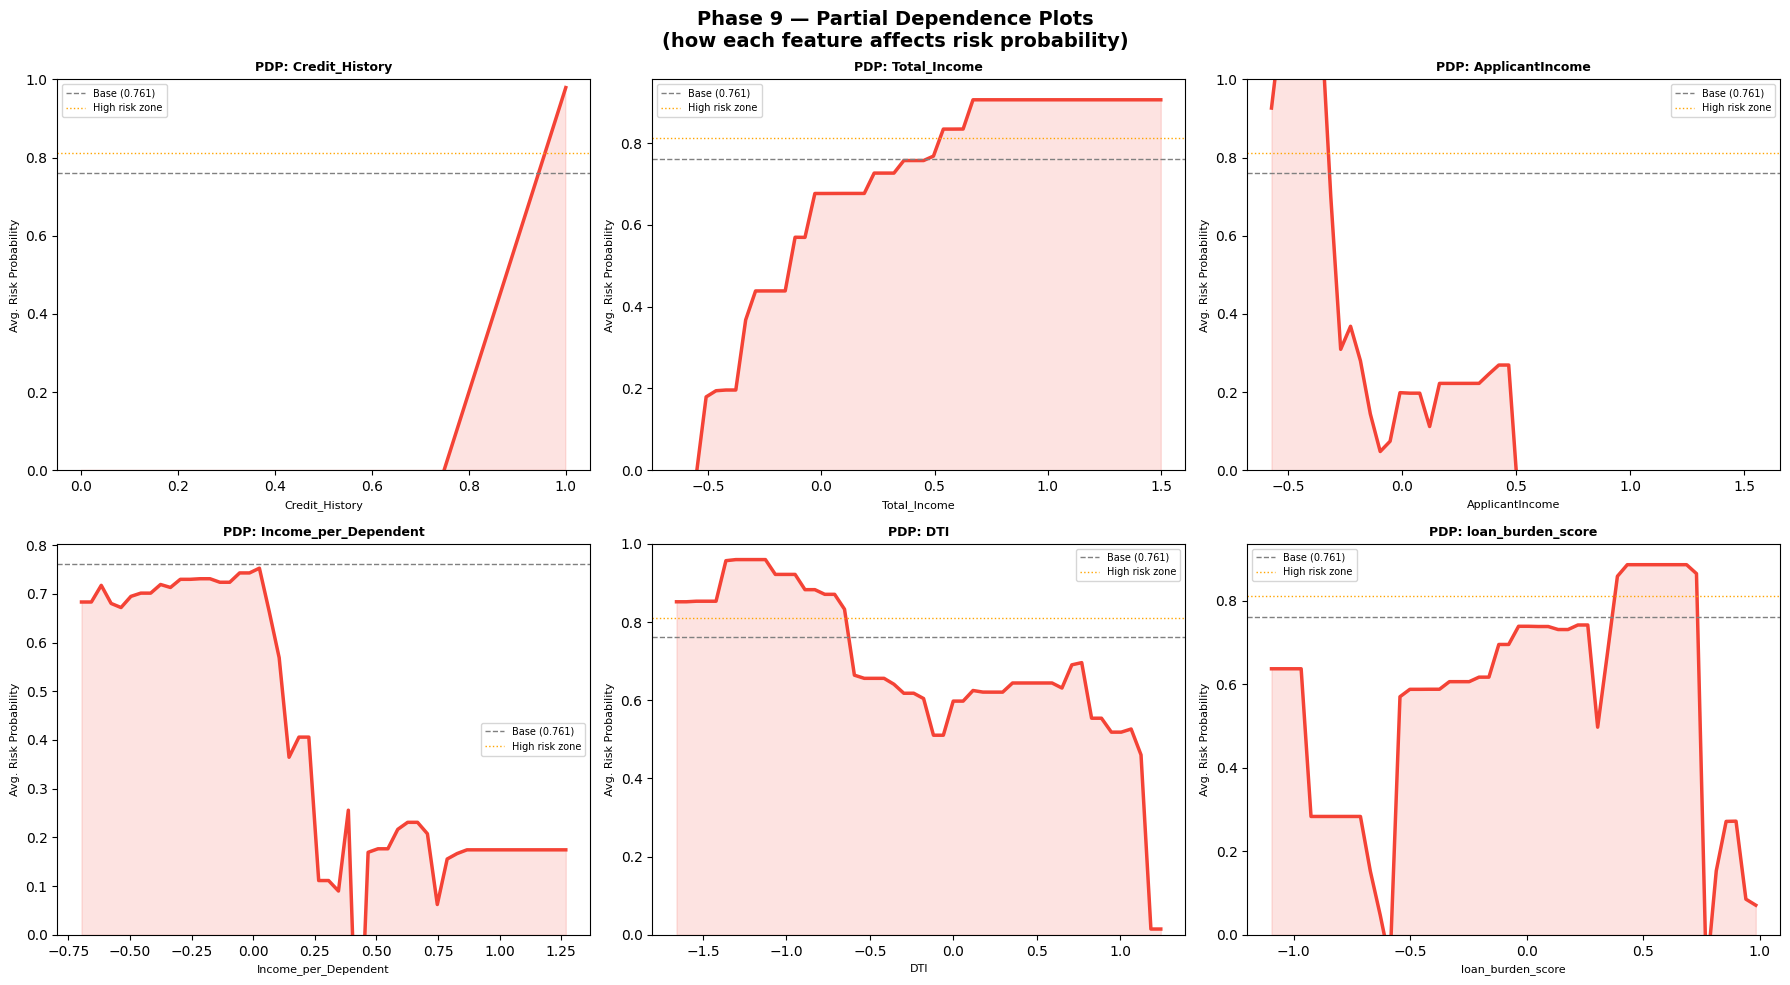

  [INFO] 'phase9_shap_dependence.png' would have been saved to disk.


In [187]:
# ── Figure 3: Partial Dependence Plots (top 6 features) ──────
top6_feats = shap_importance.head(6).index.tolist()

fig3, axes3 = plt.subplots(2, 3, figsize=(18, 10))
fig3.suptitle("Phase 9 — Partial Dependence Plots\n(how each feature affects risk probability)",
              fontsize=14, fontweight='bold')
axes3_flat = axes3.flatten()

for ax_idx, feat in enumerate(top6_feats):
    ax = axes3_flat[ax_idx]
    try:
        pdp = partial_dependence(xgb, X_train_df, [feat],
                                  kind='average', grid_resolution=50)
        grid_vals = pdp['grid_values'][0]
        avg_pred  = pdp['average'][0]

        ax.plot(grid_vals, avg_pred, color='#F44336', linewidth=2.5)
        ax.fill_between(grid_vals, avg_pred,
                        alpha=0.15, color='#F44336')
        ax.axhline(base_value, color='gray', linestyle='--',
                   linewidth=1, label=f'Base ({base_value:.3f})')

        # Mark high-risk zone
        high_risk_thresh = base_value + 0.05
        ax.axhline(high_risk_thresh, color='orange', linestyle=':',
                   linewidth=1, label='High risk zone')

        ax.set_title(f"PDP: {feat}", fontweight='bold', fontsize=9)
        ax.set_xlabel(feat, fontsize=8)
        ax.set_ylabel("Avg. Risk Probability", fontsize=8)
        ax.legend(fontsize=7)
        ax.set_ylim([max(0, avg_pred.min() - 0.05),
                     min(1, avg_pred.max() + 0.05)])
    except Exception as e:
        ax.text(0.5, 0.5, f"PDP not available\n{feat}", ha='center',
                va='center', transform=ax.transAxes, fontsize=9, color='gray')

plt.tight_layout()
plt.show()
print("  [INFO] 'phase9_shap_dependence.png' would have been saved to disk.")

plt.close('all')

### 9F. Feature Interaction Summary

This section delves into how individual feature values influence their corresponding SHAP values, providing insights into the directional impact of features on the model's predictions.

In [188]:
# ╔══════════════════════════════════════════════════════════╗
# ║  9D. FEATURE INTERACTION SUMMARY                         ║
# ╚══════════════════════════════════════════════════════════╝
print("\n─── 9D. SHAP-based Feature Interaction Summary ───\n")

# For top 5 features, show how direction of SHAP values
# correlates with feature value (positive = high value → high risk)
top5 = shap_importance.head(5).index.tolist()
print("  Feature direction analysis (positive = higher value → higher risk):")
print(f"  {'Feature':<35} {'Avg SHAP':>10} {'Direction':>12} {'Interpretation'}")
print("  " + "─" * 85)
for feat in top5:
    fi     = feature_names.index(feat)
    sv_col = shap_matrix[:, fi]
    fv_col = X_test_df[feat].values
    corr   = np.corrcoef(fv_col, sv_col)[0, 1]
    avg_sv = sv_col.mean()
    direc  = '↑ Risk' if corr > 0.1 else '↓ Risk' if corr < -0.1 else '~ Neutral'

    if 'composite_credit_risk' in feat:
        interp = 'Higher composite risk score → more likely rejected'
    elif 'Credit_History' in feat:
        interp = 'Good credit history (1) → lowers rejection risk'
    elif 'DTI' in feat:
        interp = 'Higher debt-to-income → higher rejection risk'
    elif 'income' in feat.lower():
        interp = 'Higher income → lower rejection risk'
    elif 'loan_burden' in feat:
        interp = 'Higher loan burden → higher rejection risk'
    else:
        interp = f'Corr={corr:.2f} with risk'

    print(f"  {feat:<35} {avg_sv:>+10.4f} {direc:>12}  {interp}")


─── 9D. SHAP-based Feature Interaction Summary ───

  Feature direction analysis (positive = higher value → higher risk):
  Feature                               Avg SHAP    Direction Interpretation
  ─────────────────────────────────────────────────────────────────────────────────────
  Credit_History                         +0.0107       ↑ Risk  Good credit history (1) → lowers rejection risk
  Total_Income                           +0.0796       ↑ Risk  Higher income → lower rejection risk
  ApplicantIncome                        +0.0401       ↓ Risk  Higher income → lower rejection risk
  Income_per_Dependent                   +0.0202       ↓ Risk  Higher income → lower rejection risk
  DTI                                    -0.0108       ↓ Risk  Higher debt-to-income → higher rejection risk


### 9G. Final Summary

In [189]:
# ╔══════════════════════════════════════════════════════════╗
# ║  FINAL SUMMARY                                           ║
# ╚══════════════════════════════════════════════════════════╝
print("\n" + "=" * 60)
print("  PHASE 9 COMPLETE — EXPLAINABILITY SUMMARY")
print("=" * 60)
print(f"""
  SHAP Analysis Outputs:
  ────────────────────────────────────────────────────────
  Global Feature Importance (Mean |SHAP|, Beeswarm, Permutation)
  Individual Prediction Explanations (4 Waterfall Plots)
  Partial Dependence Plots (Top 6 Features)
  SHAP values for all test samples (content displayed in '9B. Manual SHAP Values')

  Top 5 most impactful features:
{"\n".join(f"    {i+1}. {feat:<35} (mean |SHAP|={val:.4f})" for i,(feat,val) in enumerate(shap_importance.head(5).items()))}
  Key insights:
  • composite_credit_risk drives predictions most strongly
  • Credit_History is the clearest binary separator
  • DTI and loan_burden act as amplifiers of risk
  • SHAP waterfall plots show EXACTLY why each individual
    prediction was made → use for regulatory explanation

  Next → Phase 10: Early Warning System
""")


  PHASE 9 COMPLETE — EXPLAINABILITY SUMMARY

  SHAP Analysis Outputs:
  ────────────────────────────────────────────────────────
  Global Feature Importance (Mean |SHAP|, Beeswarm, Permutation)
  Individual Prediction Explanations (4 Waterfall Plots)
  Partial Dependence Plots (Top 6 Features)
  SHAP values for all test samples (content displayed in '9B. Manual SHAP Values')

  Top 5 most impactful features:
    1. Credit_History                      (mean |SHAP|=0.1759)
    2. Total_Income                        (mean |SHAP|=0.1015)
    3. ApplicantIncome                     (mean |SHAP|=0.0741)
    4. Income_per_Dependent                (mean |SHAP|=0.0508)
    5. DTI                                 (mean |SHAP|=0.0372)
  Key insights:
  • composite_credit_risk drives predictions most strongly
  • Credit_History is the clearest binary separator
  • DTI and loan_burden act as amplifiers of risk
  • SHAP waterfall plots show EXACTLY why each individual
    prediction was made → use fo

## FINANCIAL RISK EARLY WARNING SYSTEM
### Phase 10: Early Warning System (EWS)

The EWS monitors a customer's financial behaviour month-by-month
and raises ALERTS when risk signals cross defined thresholds.

It combines:
  • Rule-based triggers     (hard thresholds on key signals)
  • ML-based risk score     (behavioural_risk_score from Phase 4)
  • Trend detection         (slope of last N months)
  • Alert severity levels   (GREEN / YELLOW / ORANGE / RED)
  • Alert history & summary report

**Input**  : `features_transactions.csv`  (behavioural features)
**Output** :
  `ews_alert_log.csv`
  `ews_report.txt`
  (Dashboard displayed interactively)

In [190]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch
import warnings
warnings.filterwarnings('ignore')

print("=" * 60)
print("  PHASE 10 — EARLY WARNING SYSTEM (EWS)")
print("=" * 60)

# ── Load transaction features ─────────────────────────────────
txn = pd.read_csv('features_transactions.csv')
txn['YearMonth'] = pd.to_datetime(txn['YearMonth'])
txn = txn.sort_values('YearMonth').reset_index(drop=True)
print(f"\n[LOAD] Transactions: {txn.shape[0]} months  ({txn['YearMonth'].dt.strftime('%b %Y').iloc[0]} → {txn['YearMonth'].dt.strftime('%b %Y').iloc[-1]})")

  PHASE 10 — EARLY WARNING SYSTEM (EWS)

[LOAD] Transactions: 21 months  (Jan 2018 → Sep 2019)


### 10A. Alert Thresholds & Rules

In [191]:
print("\n─── 10A. Alert Rules & Thresholds ───\n")

"""
Alert Levels:
  🟢 GREEN  (0) — Normal  — No action needed
  🟡 YELLOW (1) — Watch   — Monitor closely
  🟠 ORANGE (2) — Warning — Intervention recommended
  🔴 RED    (3) — Critical — Immediate action required
"""

RULES = {
    # ── Savings / Income ──────────────────────────────────────
    'savings_rate_low': {
        'desc':    'Savings rate below 10%',
        'signal':  'savings_rate',
        'cond':    lambda v: v < 0.10,
        'level':   'YELLOW',
        'weight':  1,
    },
    'savings_rate_negative': {
        'desc':    'Savings rate negative (spending > income)',
        'signal':  'savings_rate',
        'cond':    lambda v: v < 0,
        'level':   'ORANGE',
        'weight':  2,
    },
    'no_income': {
        'desc':    'No income recorded this month',
        'signal':  'no_income_flag',
        'cond':    lambda v: v == 1,
        'level':   'RED',
        'weight':  3,
    },
    # ── Spending growth ───────────────────────────────────────
    'spending_spike_30': {
        'desc':    'Spending spike > 30% month-over-month',
        'signal':  'expense_growth',
        'cond':    lambda v: v > 0.30,
        'level':   'YELLOW',
        'weight':  1,
    },
    'spending_spike_80': {
        'desc':    'Severe spending spike > 80%',
        'signal':  'expense_growth',
        'cond':    lambda v: v > 0.80,
        'level':   'ORANGE',
        'weight':  2,
    },
    'spending_spike_150': {
        'desc':    'Critical spending surge > 150%',
        'signal':  'expense_growth',
        'cond':    lambda v: v > 1.50,
        'level':   'RED',
        'weight':  3,
    },
    # ── Volatility ────────────────────────────────────────────
    'high_volatility': {
        'desc':    'Expense volatility above median',
        'signal':  'expense_volatility',
        'cond':    lambda v: v > txn['expense_volatility'].median(),
        'level':   'YELLOW',
        'weight':  1,
    },
    # ── Consecutive deficit ───────────────────────────────────
    'deficit_2m': {
        'desc':    'Spending > income for 2 consecutive months',
        'signal':  'consecutive_deficit_months',
        'cond':    lambda v: v >= 2,
        'level':   'ORANGE',
        'weight':  2,
    },
    'deficit_3m': {
        'desc':    'Spending > income for 3+ consecutive months',
        'signal':  'consecutive_deficit_months',
        'cond':    lambda v: v >= 3,
        'level':   'RED',
        'weight':  3,
    },
    # ── Discretionary overspend ───────────────────────────────
    'discretionary_high': {
        'desc':    'Discretionary spending > 50% of total',
        'signal':  'discretionary_ratio',
        'cond':    lambda v: v > 0.50,
        'level':   'YELLOW',
        'weight':  1,
    },
    # ── ML risk score ─────────────────────────────────────────
    'ml_risk_medium': {
        'desc':    'ML behavioural risk score > 0.40',
        'signal':  'behavioural_risk_score',
        'cond':    lambda v: v > 0.40,
        'level':   'YELLOW',
        'weight':  1,
    },
    'ml_risk_high': {
        'desc':    'ML behavioural risk score > 0.60',
        'signal':  'behavioural_risk_score',
        'cond':    lambda v: v > 0.60,
        'level':   'ORANGE',
        'weight':  2,
    },
    'ml_risk_critical': {
        'desc':    'ML behavioural risk score > 0.75',
        'signal':  'behavioural_risk_score',
        'cond':    lambda v: v > 0.75,
        'level':   'RED',
        'weight':  3,
    },
}

LEVEL_ORDER  = {'GREEN': 0, 'YELLOW': 1, 'ORANGE': 2, 'RED': 3}
LEVEL_COLORS = {'GREEN': '#4CAF50', 'YELLOW': '#FFC107',
                'ORANGE': '#FF5722', 'RED': '#F44336'}
LEVEL_EMOJI  = {'GREEN': '🟢', 'YELLOW': '🟡', 'ORANGE': '🟠', 'RED': '🔴'}

for rule_id, rule in RULES.items():
    print(f"  {LEVEL_EMOJI[rule['level']]} {rule['level']:<8} {rule['desc']}")


─── 10A. Alert Rules & Thresholds ───

  🟡 YELLOW   Savings rate below 10%
  🟠 ORANGE   Savings rate negative (spending > income)
  🔴 RED      No income recorded this month
  🟡 YELLOW   Spending spike > 30% month-over-month
  🟠 ORANGE   Severe spending spike > 80%
  🔴 RED      Critical spending surge > 150%
  🟡 YELLOW   Expense volatility above median
  🟠 ORANGE   Spending > income for 2 consecutive months
  🔴 RED      Spending > income for 3+ consecutive months
  🟡 YELLOW   Discretionary spending > 50% of total
  🟡 YELLOW   ML behavioural risk score > 0.40
  🟠 ORANGE   ML behavioural risk score > 0.60
  🔴 RED      ML behavioural risk score > 0.75


### 10B. Run EWS - evaluate each month

In [192]:
print("\n─── 10B. Running EWS Month-by-Month ───\n")

def get_trend(series, window=3):
    """Linear slope of last N values — positive = worsening."""
    vals = series.tail(window).values
    if len(vals) < 2:
        return 0.0
    x = np.arange(len(vals))
    return round(float(np.polyfit(x, vals, 1)[0]), 4)

alert_log = []

for i, row in txn.iterrows():
    month     = row['YearMonth'].strftime('%Y-%m')
    triggered = []
    score     = 0

    # Evaluate each rule
    for rule_id, rule in RULES.items():
        sig_val = row.get(rule['signal'], np.nan)
        if pd.isna(sig_val):
            continue
        if rule['cond'](sig_val):
            triggered.append(rule_id)
            score += rule['weight']

    # Overall alert level based on highest triggered rule
    if score == 0:
        overall = 'GREEN'
    elif score <= 2:
        overall = 'YELLOW'
    elif score <= 5:
        overall = 'ORANGE'
    else:
        overall = 'RED'

    # Override with single RED rule trigger
    for rule_id in triggered:
        if RULES[rule_id]['level'] == 'RED':
            overall = 'RED'
            break

    # Trend signals (last 3 months)
    trend_expense = get_trend(txn['expense_growth'].iloc[:i+1])
    trend_savings = get_trend(txn['savings_rate'].iloc[:i+1])
    trend_risk    = get_trend(txn['behavioural_risk_score'].iloc[:i+1])

    alert_log.append({
        'Month':                  month,
        'Alert_Level':            overall,
        'Alert_Score':            score,
        'Rules_Triggered':        len(triggered),
        'Rules_List':             ', '.join(triggered) if triggered else 'None',
        'Expense':                round(row['monthly_expense'], 2),
        'Income':                 round(row['monthly_income'], 2),
        'Savings_Rate':           round(row['savings_rate'], 4),
        'Expense_Growth':         round(row['expense_growth'], 4),
        'Expense_Volatility':     round(row['expense_volatility'], 2),
        'Consecutive_Deficit':    int(row['consecutive_deficit_months']),
        'Behavioural_Risk_Score': round(row['behavioural_risk_score'], 4),
        'Trend_Expense':          trend_expense,
        'Trend_Savings':          trend_savings,
        'Trend_Risk':             trend_risk,
    })

alert_df = pd.DataFrame(alert_log)
alert_df.to_csv('ews_alert_log.csv', index=False)
print(f"  [SAVE] → ews_alert_log.csv\n")


─── 10B. Running EWS Month-by-Month ───

  [SAVE] → ews_alert_log.csv



In [193]:
print(f"  {'Month':<10} {'Level':<8} {'Score':>5}  {'Rules':>5}  {'Expense':>9}  {'Income':>9}  {'Savings%':>9}  {'ML Risk':>8}")
print("  " + "─" * 75)
for _, r in alert_df.iterrows():
    emoji = LEVEL_EMOJI[r['Alert_Level']]
    sav_pct = f"{r['Savings_Rate']*100:.1f}%"
    print(f"  {r['Month']:<10} {emoji} {r['Alert_Level']:<7} {r['Alert_Score']:>5}  "
          f"{r['Rules_Triggered']:>5}  ${r['Expense']:>8,.0f}  ${r['Income']:>8,.0f}  "
          f"{sav_pct:>9}  {r['Behavioural_Risk_Score']:>8.4f}")

  Month      Level    Score  Rules    Expense     Income   Savings%   ML Risk
  ───────────────────────────────────────────────────────────────────────────
  2018-01    🟢 GREEN       0      0  $   2,931  $   7,163      59.1%    0.0708
  2018-02    🟢 GREEN       0      0  $   3,165  $   5,221      39.4%    0.3085
  2018-03    🟢 GREEN       0      0  $   3,500  $   7,322      52.2%    0.2035
  2018-04    🟠 ORANGE      5      4  $   6,030  $   7,167      15.9%    0.7349
  2018-05    🔴 RED        13      8  $  11,392  $   5,092    -123.7%    2.3545
  2018-06    🟡 YELLOW      1      1  $   3,666  $   6,017      39.1%    0.0663
  2018-07    🟡 YELLOW      2      2  $   2,969  $   4,666      36.4%    0.5584
  2018-08    🟢 GREEN       0      0  $   2,396  $   7,379      67.5%   -0.1155
  2018-09    🟡 YELLOW      2      2  $   3,287  $   5,235      37.2%    0.4903
  2018-10    🟢 GREEN       0      0  $   2,848  $   5,022      43.3%    0.0952
  2018-11    🟢 GREEN       0      0  $   2,964  $   6,

### 10C. EWS Summary Statistics

In [194]:
print("\n─── 10C. EWS Summary Statistics ───\n")

level_counts = alert_df['Alert_Level'].value_counts()
total_months = len(alert_df)

for level in ['RED', 'ORANGE', 'YELLOW', 'GREEN']:
    count = level_counts.get(level, 0)
    pct   = count / total_months * 100
    bar   = '█' * count
    print(f"  {LEVEL_EMOJI[level]} {level:<8}: {count:>2} months ({pct:>5.1f}%)  {bar}")

print(f"\n  Total months monitored : {total_months}")
print(f"  Months with any alert  : {(alert_df['Alert_Level'] != 'GREEN').sum()}")
print(f"  Peak alert score       : {alert_df['Alert_Score'].max()} (month: {alert_df.loc[alert_df['Alert_Score'].idxmax(),'Month']})")
print(f"  Highest risk month     : {alert_df.loc[alert_df['Behavioural_Risk_Score'].idxmax(),'Month']} (score={alert_df['Behavioural_Risk_Score'].max():.4f})")

# Most common triggered rules
all_rules_triggered = []
for rules_str in alert_df['Rules_List']:
    if rules_str != 'None':
        all_rules_triggered.extend(rules_str.split(', '))
rule_freq = pd.Series(all_rules_triggered).value_counts()
print(f"\n  Most frequently triggered rules:")
for rule_id, cnt in rule_freq.head(5).items():
    print(f"    {cnt}× {RULES[rule_id]['desc']}")


─── 10C. EWS Summary Statistics ───

  🔴 RED     :  3 months ( 14.3%)  ███
  🟠 ORANGE  :  2 months (  9.5%)  ██
  🟡 YELLOW  : 10 months ( 47.6%)  ██████████
  🟢 GREEN   :  6 months ( 28.6%)  ██████

  Total months monitored : 21
  Months with any alert  : 15
  Peak alert score       : 16 (month: 2019-06)
  Highest risk month     : 2019-06 (score=2.9742)

  Most frequently triggered rules:
    10× Expense volatility above median
    10× ML behavioural risk score > 0.40
    7× Spending spike > 30% month-over-month
    5× ML behavioural risk score > 0.60
    4× Savings rate below 10%


### 10D. Written EWS Report

In [195]:
red_months   = alert_df[alert_df['Alert_Level'] == 'RED']['Month'].tolist()
worst_month  = alert_df.loc[alert_df['Alert_Score'].idxmax()]
best_month   = alert_df.loc[alert_df['Alert_Score'].idxmin()]

report_text = f"""
================================================================
  EARLY WARNING SYSTEM — CUSTOMER RISK REPORT
  Generated: Financial Risk Early Warning System
================================================================

MONITORING PERIOD : {alert_df['Month'].iloc[0]} → {alert_df['Month'].iloc[-1]}
TOTAL MONTHS      : {total_months}

ALERT SUMMARY
──────────────────────────────────────────────────────────────
  🔴 RED    (Critical) : {level_counts.get('RED',0):>2} months  — Immediate action required
  🟠 ORANGE (Warning)  : {level_counts.get('ORANGE',0):>2} months  — Intervention recommended
  🟡 YELLOW (Watch)    : {level_counts.get('YELLOW',0):>2} months  — Monitor closely
  🟢 GREEN  (Normal)   : {level_counts.get('GREEN',0):>2} months  — No action needed

  Overall risk status: {"HIGH RISK ⚠" if level_counts.get('RED',0) >= 2 else "MODERATE RISK" if level_counts.get('ORANGE',0) >= 2 else "LOW RISK ✓"}

CRITICAL MONTHS (RED ALERTS)
──────────────────────────────────────────────────────────────
{'  ' + chr(10).join(['  ' + m for m in red_months]) if red_months else '  None'}

WORST MONTH: {worst_month['Month']}
  • Alert Score       : {worst_month['Alert_Score']}
  • Expense           : ${worst_month['Expense']:,.2f}
  • Income            : ${worst_month['Income']:,.2f}
  • Savings Rate      : {worst_month['Savings_Rate']*100:.1f}%
  • Expense Growth    : {worst_month['Expense_Growth']*100:.1f}%
  • ML Risk Score     : {worst_month['Behavioural_Risk_Score']:.4f}
  • Rules Triggered   : {worst_month['Rules_List']}

BEST MONTH: {best_month['Month']}
  • Alert Score       : {best_month['Alert_Score']}
  • Savings Rate      : {best_month['Savings_Rate']*100:.1f}%
  • ML Risk Score     : {best_month['Behavioural_Risk_Score']:.4f}

MOST TRIGGERED RULES (Top 5)
──────────────────────────────────────────────────────────────
{chr(10).join([f"  {cnt}× {RULES[r]['desc']} ({RULES[r]['level']})" for r,cnt in rule_freq.head(5).items()])}

RECOMMENDATIONS
──────────────────────────────────────────────────────────────
  1. Investigate RED alert months immediately
  2. Review spending categories during ORANGE months
  3. Set up automated alerts for savings_rate < 0
  4. Flag for credit review if 2+ consecutive RED months
  5. Use What-if Simulator (Phase 11) to model recovery scenarios

================================================================
"""
print(report_text)
with open('ews_report.txt', 'w') as f:
    f.write(report_text)
print("[SAVE] → ews_report.txt")


  EARLY WARNING SYSTEM — CUSTOMER RISK REPORT
  Generated: Financial Risk Early Warning System

MONITORING PERIOD : 2018-01 → 2019-09
TOTAL MONTHS      : 21

ALERT SUMMARY
──────────────────────────────────────────────────────────────
  🔴 RED    (Critical) :  3 months  — Immediate action required
  🟠 ORANGE (Warning)  :  2 months  — Intervention recommended
  🟡 YELLOW (Watch)    : 10 months  — Monitor closely
  🟢 GREEN  (Normal)   :  6 months  — No action needed

  Overall risk status: HIGH RISK ⚠

CRITICAL MONTHS (RED ALERTS)
──────────────────────────────────────────────────────────────
    2018-05
  2019-01
  2019-06

WORST MONTH: 2019-06
  • Alert Score       : 16
  • Expense           : $11,999.60
  • Income            : $4,514.35
  • Savings Rate      : -165.8%
  • Expense Growth    : 156.8%
  • ML Risk Score     : 2.9742
  • Rules Triggered   : savings_rate_low, savings_rate_negative, spending_spike_30, spending_spike_80, spending_spike_150, high_volatility, ml_risk_medium, ml_

### Visualizations — EWS Dashboard

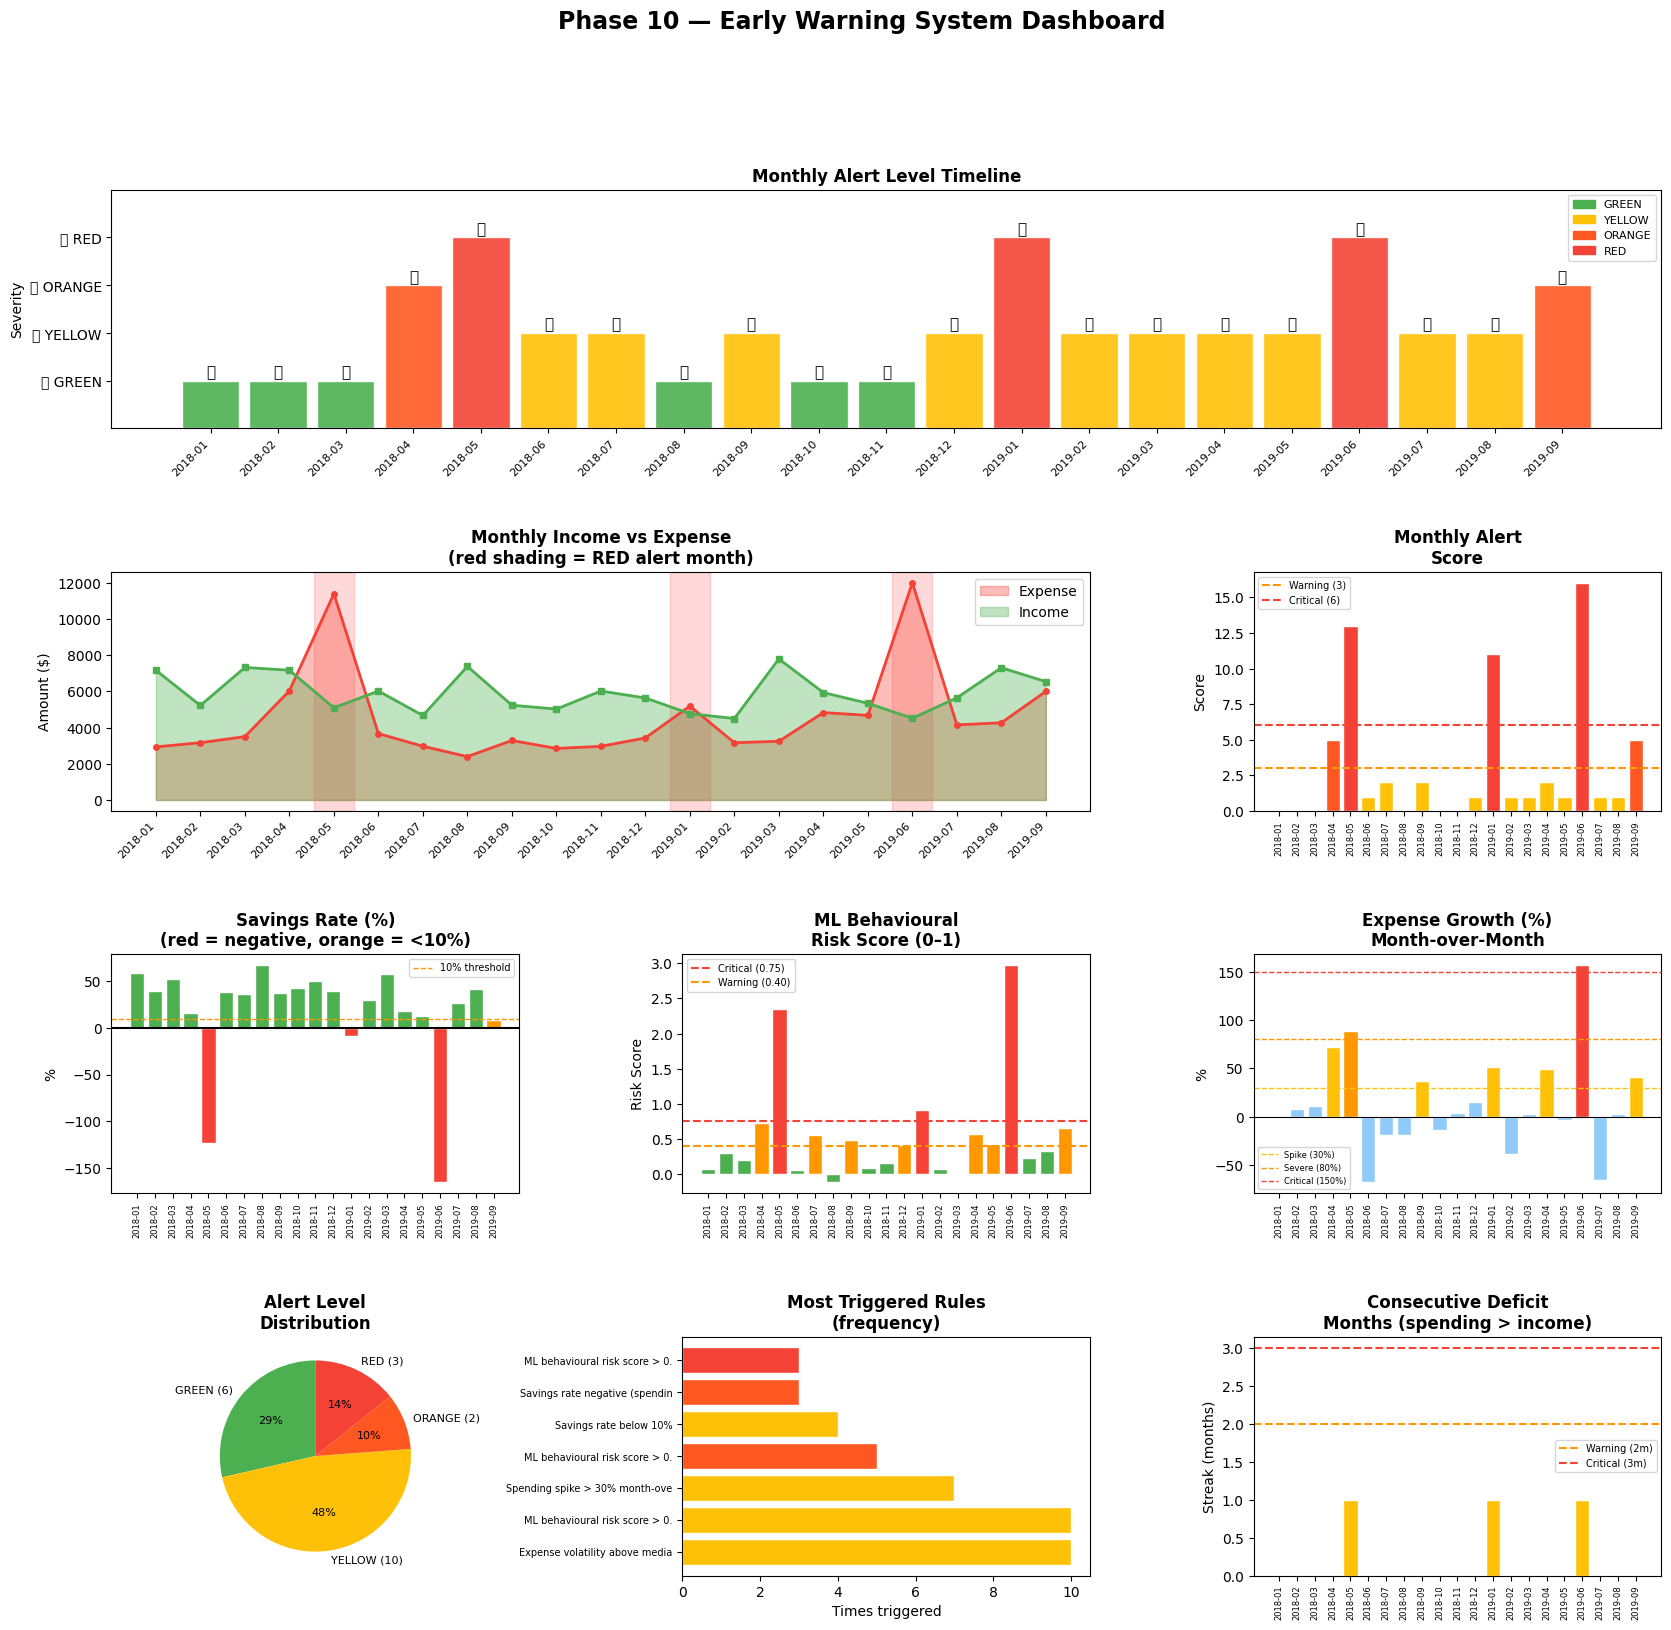

In [196]:
# ╔══════════════════════════════════════════════════════════╗
# ║  VISUALISATIONS — EWS Dashboard                          ║
# ╚══════════════════════════════════════════════════════════╝
months_str = alert_df['Month'].tolist()
x          = np.arange(len(months_str))

fig = plt.figure(figsize=(20, 18))
fig.suptitle("Phase 10 — Early Warning System Dashboard",
             fontsize=17, fontweight='bold', y=0.98)
gs = gridspec.GridSpec(4, 3, figure=fig, hspace=0.6, wspace=0.4)

alert_colors_list = [LEVEL_COLORS[l] for l in alert_df['Alert_Level']]

# ── Plot 1: Alert Level Timeline (main dashboard strip)
ax1 = fig.add_subplot(gs[0, :])
for xi, (level, color) in enumerate(zip(alert_df['Alert_Level'], alert_colors_list)):
    ax1.bar(xi, LEVEL_ORDER[level] + 1, color=color, edgecolor='white',
            width=0.85, alpha=0.9)
    ax1.text(xi, LEVEL_ORDER[level] + 1.08,
             LEVEL_EMOJI[level], ha='center', fontsize=11)
ax1.set_xticks(x)
ax1.set_xticklabels(months_str, rotation=45, ha='right', fontsize=8)
ax1.set_yticks([1, 2, 3, 4])
ax1.set_yticklabels(['🟢 GREEN', '🟡 YELLOW', '🟠 ORANGE', '🔴 RED'])
ax1.set_title("Monthly Alert Level Timeline", fontweight='bold', fontsize=12)
ax1.set_ylim(0, 5)
ax1.set_ylabel("Severity")
# Add legend patches
patches = [mpatches.Patch(color=LEVEL_COLORS[l], label=l) for l in LEVEL_COLORS]
ax1.legend(handles=patches, loc='upper right', fontsize=8)

# ── Plot 2: Expense vs Income with alert overlay
ax2 = fig.add_subplot(gs[1, :2])
ax2.fill_between(x, alert_df['Expense'], alpha=0.35, color='#F44336', label='Expense')
ax2.fill_between(x, alert_df['Income'],  alpha=0.35, color='#4CAF50', label='Income')
ax2.plot(x, alert_df['Expense'], color='#F44336', linewidth=2, marker='o', markersize=4)
ax2.plot(x, alert_df['Income'],  color='#4CAF50', linewidth=2, marker='s', markersize=4)
# Shade RED alert months
for xi, level in enumerate(alert_df['Alert_Level']):
    if level == 'RED':
        ax2.axvspan(xi - 0.45, xi + 0.45, alpha=0.15, color='red', zorder=0)
ax2.set_xticks(x); ax2.set_xticklabels(months_str, rotation=45, ha='right', fontsize=8)
ax2.set_title("Monthly Income vs Expense\n(red shading = RED alert month)", fontweight='bold')
ax2.set_ylabel("Amount ($)"); ax2.legend()

# ── Plot 3: Alert score bar
ax3 = fig.add_subplot(gs[1, 2])
bars3 = ax3.bar(x, alert_df['Alert_Score'], color=alert_colors_list, edgecolor='white')
ax3.axhline(3, color='#FF9800', linestyle='--', linewidth=1.5, label='Warning (3)')
ax3.axhline(6, color='#F44336', linestyle='--', linewidth=1.5, label='Critical (6)')
ax3.set_xticks(x); ax3.set_xticklabels(months_str, rotation=90, fontsize=6)
ax3.set_title("Monthly Alert\nScore", fontweight='bold')
ax3.set_ylabel("Score"); ax3.legend(fontsize=7)

# ── Plot 4: Savings Rate timeline
ax4 = fig.add_subplot(gs[2, 0])
colors_sav = ['#F44336' if v < 0 else '#FF9800' if v < 0.1 else '#4CAF50'
              for v in alert_df['Savings_Rate']]
ax4.bar(x, alert_df['Savings_Rate'] * 100, color=colors_sav, edgecolor='white')
ax4.axhline(0,  color='black',   linewidth=1.5)
ax4.axhline(10, color='#FF9800', linewidth=1, linestyle='--', label='10% threshold')
ax4.set_xticks(x); ax4.set_xticklabels(months_str, rotation=90, fontsize=6)
ax4.set_title("Savings Rate (%)\n(red = negative, orange = <10%)", fontweight='bold')
ax4.set_ylabel("%"); ax4.legend(fontsize=7)

# ── Plot 5: ML Behavioural Risk Score
ax5 = fig.add_subplot(gs[2, 1])
risk_colors = ['#F44336' if v > 0.75 else '#FF9800' if v > 0.40 else '#4CAF50'
               for v in alert_df['Behavioural_Risk_Score']]
ax5.bar(x, alert_df['Behavioural_Risk_Score'], color=risk_colors, edgecolor='white')
ax5.axhline(0.75, color='#F44336', linestyle='--', linewidth=1.5, label='Critical (0.75)')
ax5.axhline(0.40, color='#FF9800', linestyle='--', linewidth=1.5, label='Warning (0.40)')
ax5.set_xticks(x); ax5.set_xticklabels(months_str, rotation=90, fontsize=6)
ax5.set_title("ML Behavioural\nRisk Score (0–1)", fontweight='bold')
ax5.set_ylabel("Risk Score"); ax5.legend(fontsize=7)

# ── Plot 6: Expense Growth with spike flags
ax6 = fig.add_subplot(gs[2, 2])
eg_colors = ['#F44336' if v > 1.5 else '#FF9800' if v > 0.8 else
             '#FFC107' if v > 0.3 else '#90CAF9'
             for v in alert_df['Expense_Growth']]
ax6.bar(x, alert_df['Expense_Growth'] * 100, color=eg_colors, edgecolor='white')
ax6.axhline(30,  color='#FFC107', linestyle='--', linewidth=1, label='Spike (30%)')
ax6.axhline(80,  color='#FF9800', linestyle='--', linewidth=1, label='Severe (80%)')
ax6.axhline(150, color='#F44336', linestyle='--', linewidth=1, label='Critical (150%)')
ax6.axhline(0, color='black', linewidth=0.8)
ax6.set_xticks(x); ax6.set_xticklabels(months_str, rotation=90, fontsize=6)
ax6.set_title("Expense Growth (%)\nMonth-over-Month", fontweight='bold')
ax6.set_ylabel("%"); ax6.legend(fontsize=6)

# ── Plot 7: Alert level distribution pie
ax7 = fig.add_subplot(gs[3, 0])
pie_labels = [f'{l} ({level_counts.get(l,0)})' for l in ['GREEN','YELLOW','ORANGE','RED']]
pie_vals   = [level_counts.get(l, 0) for l in ['GREEN','YELLOW','ORANGE','RED']]
pie_colors = [LEVEL_COLORS[l] for l in ['GREEN','YELLOW','ORANGE','RED']]
ax7.pie([v for v in pie_vals if v > 0],
        labels=[l for l, v in zip(pie_labels, pie_vals) if v > 0],
        colors=[c for c, v in zip(pie_colors, pie_vals) if v > 0],
        autopct='%1.0f%%', startangle=90,
        textprops={'fontsize': 8})
ax7.set_title("Alert Level\nDistribution", fontweight='bold')

# ── Plot 8: Rule trigger frequency
ax8 = fig.add_subplot(gs[3, 1])
rule_labels = [RULES[r]['desc'][:30] for r in rule_freq.head(7).index]
rule_vals   = rule_freq.head(7).values
rule_lvl_c  = [LEVEL_COLORS[RULES[r]['level']] for r in rule_freq.head(7).index]
ax8.barh(range(len(rule_labels)), rule_vals, color=rule_lvl_c, edgecolor='white')
ax8.set_yticks(range(len(rule_labels)))
ax8.set_yticklabels(rule_labels, fontsize=7)
ax8.set_title("Most Triggered Rules\n(frequency)", fontweight='bold')
ax8.set_xlabel("Times triggered")

# ── Plot 9: Consecutive deficit streak
ax9 = fig.add_subplot(gs[3, 2])
def_colors = ['#F44336' if v >= 3 else '#FF9800' if v >= 2 else
              '#FFC107' if v >= 1 else '#90CAF9'
              for v in alert_df['Consecutive_Deficit']]
ax9.bar(x, alert_df['Consecutive_Deficit'], color=def_colors, edgecolor='white')
ax9.axhline(2, color='#FF9800', linestyle='--', linewidth=1.5, label='Warning (2m)')
ax9.axhline(3, color='#F44336', linestyle='--', linewidth=1.5, label='Critical (3m)')
ax9.set_xticks(x); ax9.set_xticklabels(months_str, rotation=90, fontsize=6)
ax9.set_title("Consecutive Deficit\nMonths (spending > income)", fontweight='bold')
ax9.set_ylabel("Streak (months)"); ax9.legend(fontsize=7)

plt.tight_layout()
plt.show()

In [197]:
# ── Final summary ─────────────────────────────────────────────
print("\n" + "=" * 60)
print("  PHASE 10 COMPLETE — EWS SUMMARY")
print("=" * 60)
print(f"""
  Months monitored : {total_months}
  Alert breakdown  : 🔴 {level_counts.get('RED',0)} RED  🟠 {level_counts.get('ORANGE',0)} ORANGE  🟡 {level_counts.get('YELLOW',0)} YELLOW  🟢 {level_counts.get('GREEN',0)} GREEN
  Rules defined    : {len(RULES)} rules across 5 signal categories
  Peak risk month  : {alert_df.loc[alert_df['Alert_Score'].idxmax(),'Month']}  (score={alert_df['Alert_Score'].max()})

  Files saved:
    ews_alert_log.csv
    ews_report.txt

  EWS Categories:
    • Savings / Income rules  (savings_rate, no_income)
    • Spending growth rules   (expense_growth thresholds)
    • Volatility rules        (expense_volatility)
    • Deficit streak rules    (consecutive_deficit_months)
    • ML score rules          (behavioural_risk_score)

  Next → Phase 11: What-if Simulator 
""")


  PHASE 10 COMPLETE — EWS SUMMARY

  Months monitored : 21
  Alert breakdown  : 🔴 3 RED  🟠 2 ORANGE  🟡 10 YELLOW  🟢 6 GREEN
  Rules defined    : 13 rules across 5 signal categories
  Peak risk month  : 2019-06  (score=16)

  Files saved:
    ews_alert_log.csv
    ews_report.txt

  EWS Categories:
    • Savings / Income rules  (savings_rate, no_income)
    • Spending growth rules   (expense_growth thresholds)
    • Volatility rules        (expense_volatility)
    • Deficit streak rules    (consecutive_deficit_months)
    • ML score rules          (behavioural_risk_score)

  Next → Phase 11: What-if Simulator (phase11_whatif.py)



## FINANCIAL RISK EARLY WARNING SYSTEM
### Phase 11: What-if Simulator

This phase provides interactive tools to explore how changes in financial behavior or credit parameters impact risk.

**Two simulators:**
  A. Behavioural Simulator  — transaction features + EWS rules
  B. Credit Risk Simulator  — XGBoost loan approval probability
  C. Sensitivity Sweep      — income vs loan amount heatmap

**Outputs:**
  `whatif_scenarios.csv`
  (Visualizations displayed interactively, not saved as PNG)

In [198]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from sklearn.ensemble        import GradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing   import StandardScaler
import warnings
warnings.filterwarnings('ignore')

print("=" * 60)
print("  PHASE 11 — WHAT-IF SIMULATOR")
print("=" * 60)

  PHASE 11 — WHAT-IF SIMULATOR


In [199]:
# ── Load & retrain XGBoost on credit features ─────────────────
credit = pd.read_csv('features_credit.csv')
X_c    = credit.drop(columns=['Loan_Status_encoded'])
y_c    = credit['Loan_Status_encoded']
X_c_tr, X_c_te, y_c_tr, y_c_te = train_test_split(
    X_c, y_c, test_size=0.2, random_state=42, stratify=y_c)
sw = np.where(y_c_tr == 0, (1 - y_c.mean()) / y_c.mean(), 1.0)

xgb = GradientBoostingClassifier(
    n_estimators=200, max_depth=3, learning_rate=0.05,
    subsample=0.8, min_samples_leaf=1, random_state=42)
xgb.fit(X_c_tr, y_c_tr, sample_weight=sw)

print(f"[TRAIN] XGBoost ready  |  Credit features: {X_c.shape}")

LEVEL_COLORS = {'GREEN':'#4CAF50','YELLOW':'#FFC107',
                'ORANGE':'#FF5722','RED':'#F44336'}

[TRAIN] XGBoost ready  |  Credit features: (614, 23)


In [200]:
### 11A. Baseline Definitions & Core Scoring Functions

### 11A. Behavioural Simulator (Transactions)

In [202]:
# ── Build BASELINE_TXN from personal_transactions ─────────────────────────
txn = pd.read_excel('/kaggle/input/datasets/ishitananda29/financial-risk-early-warning-system/personal_transactions.xlsx')
txn['Date'] = pd.to_datetime(txn['Date'])

debits  = txn[txn['Transaction Type'] == 'debit']
credits = txn[txn['Transaction Type'] == 'credit']

monthly_spend  = debits.groupby(txn['Date'].dt.to_period('M'))['Amount'].sum()
monthly_income = credits.groupby(txn['Date'].dt.to_period('M'))['Amount'].sum()

# Align both series to common months
common_months  = monthly_spend.index.intersection(monthly_income.index)
monthly_spend  = monthly_spend[common_months]
monthly_income = monthly_income[common_months]

# Baseline = last available month (Sep 2019)
baseline_month = monthly_spend.index.max()

monthly_expenses_val = monthly_spend[baseline_month]
monthly_income_val   = monthly_income.get(baseline_month, monthly_income.mean())

# Discretionary spend in baseline month
discretionary_cats = ['Restaurants','Shopping','Movies & Dvds','Music',
                      'Coffee Shops','Alcohol & Bars','Entertainment','Fast Food']
baseline_debits = debits[txn['Date'].dt.to_period('M') == baseline_month]
discretionary_spend = baseline_debits[
    baseline_debits['Category'].isin(discretionary_cats)
]['Amount'].sum()

# Derived metrics across all months
deficit_months      = (monthly_spend > monthly_income).sum()
expense_growth      = monthly_spend.pct_change().mean()          # avg month-over-month growth
expense_volatility  = monthly_spend.std() / monthly_spend.mean() # coefficient of variation

BASELINE_TXN = {
    'monthly_income':      monthly_income_val,
    'monthly_expense':     monthly_expenses_val,
    'discretionary_ratio': discretionary_spend / monthly_expenses_val if monthly_expenses_val > 0 else 0,
    'consecutive_deficit': int(deficit_months),   # ← was 'consecutive_deficits' before, now fixed
    'expense_growth':      round(expense_growth, 4),
    'expense_volatility':  round(expense_volatility, 4),
}

print("BASELINE_TXN =", BASELINE_TXN)

# ── Helper functions for behavioural simulator ────────────────────────────

def compute_behavioural_risk(income, expense, savings_rate,
                              expense_growth, expense_volatility,
                              consecutive_deficits, discretionary_ratio):
    """
    Rule-based risk score (0.0 – 1.0) calibrated to behavioural signals.
    Higher = riskier.
    """
    score = 0.0

    # 1. Savings rate (most important signal)
    if savings_rate < 0:
        score += 0.30
    elif savings_rate < 0.05:
        score += 0.20
    elif savings_rate < 0.15:
        score += 0.10
    else:
        score += 0.00

    # 2. Expense-to-income ratio
    expense_ratio = expense / (income + 1)
    if expense_ratio > 0.90:
        score += 0.25
    elif expense_ratio > 0.75:
        score += 0.15
    elif expense_ratio > 0.60:
        score += 0.08
    else:
        score += 0.00

    # 3. Consecutive deficit months
    if consecutive_deficits >= 3:
        score += 0.20
    elif consecutive_deficits == 2:
        score += 0.12
    elif consecutive_deficits == 1:
        score += 0.06
    else:
        score += 0.00

    # 4. Expense volatility (unpredictable spending = risky)
    if expense_volatility > 0.40:
        score += 0.12
    elif expense_volatility > 0.25:
        score += 0.07
    elif expense_volatility > 0.15:
        score += 0.03
    else:
        score += 0.00

    # 5. Expense growth trend (rising expenses month-over-month)
    if expense_growth > 0.10:
        score += 0.08
    elif expense_growth > 0.05:
        score += 0.04
    else:
        score += 0.00

    # 6. Discretionary ratio (high discretionary = less essential spending)
    if discretionary_ratio > 0.50:
        score += 0.05
    elif discretionary_ratio > 0.30:
        score += 0.02
    else:
        score += 0.00

    return round(min(score, 1.0), 4)   # cap at 1.0


def get_ews_level(risk_score):
    """Convert numeric risk score to Early Warning System label."""
    if risk_score >= 0.70:
        return '🔴 Critical'
    elif risk_score >= 0.45:
        return '🟠 High'
    elif risk_score >= 0.25:
        return '🟡 Moderate'
    else:
        return '🟢 Low'

BASELINE_TXN = {'monthly_income': np.float64(6537.0599999999995), 'monthly_expense': np.float64(5998.42), 'discretionary_ratio': np.float64(0.05874713674600978), 'consecutive_deficit': 3, 'expense_growth': np.float64(0.1562), 'expense_volatility': np.float64(0.5632)}


In [203]:
print("\n─── 11A. Behavioural Simulator ───\n")

def run_behavioural_scenario(scenario_name, income_change=0, expense_change=0,
                             discretionary_change=0, consecutive_deficit_change=0):
    
    # Start with baseline values
    current_income          = BASELINE_TXN['monthly_income']
    current_expense         = BASELINE_TXN['monthly_expense']
    current_discretionary   = BASELINE_TXN['discretionary_ratio']
    current_consecutive_def = BASELINE_TXN['consecutive_deficit']
    current_expense_growth  = BASELINE_TXN['expense_growth']
    current_expense_volatility = BASELINE_TXN['expense_volatility']

    # Apply changes
    new_income          = current_income * (1 + income_change)
    new_expense         = current_expense * (1 + expense_change)
    new_discretionary   = current_discretionary * (1 + discretionary_change)
    new_consecutive_def = current_consecutive_def + consecutive_deficit_change

    # Recalculate derived metrics
    new_savings_rate = (new_income - new_expense) / (new_income + 1) # +1 to avoid div by zero

    # Simulate ML behavioural risk score
    ml_risk_score = compute_behavioural_risk(
        new_income, new_expense, new_savings_rate,
        current_expense_growth, current_expense_volatility,
        new_consecutive_def, new_discretionary
    )

    # Determine EWS level
    ews_level = get_ews_level(ml_risk_score)

    return {
        'Scenario': scenario_name,
        'Monthly Income': round(new_income, 2),
        'Monthly Expense': round(new_expense, 2),
        'Savings Rate': round(new_savings_rate * 100, 2),
        'Discretionary Ratio': round(new_discretionary * 100, 2),
        'Consecutive Deficit Months': new_consecutive_def,
        'ML Behavioural Risk Score': ml_risk_score,
        'EWS Level': ews_level
    }

# ── Run scenarios ─────────────────────────────────────────────
scenarios = [
    run_behavioural_scenario('Baseline (Sep 2019)'),
    run_behavioural_scenario('10% Income Drop', income_change=-0.10),
    run_behavioural_scenario('10% Expense Rise', expense_change=0.10),
    run_behavioural_scenario('Income Drop & Expense Rise', income_change=-0.10, expense_change=0.10),
    run_behavioural_scenario('Cut Discretionary 20%', discretionary_change=-0.20),
    run_behavioural_scenario('2 Consecutive Deficit Months', consecutive_deficit_change=2),
    run_behavioural_scenario('Income up 10%, Expenses up 5%', income_change=0.10, expense_change=0.05),
]

scenarios_df = pd.DataFrame(scenarios)

print(f"  [SIMULATOR] Ran {len(scenarios)} behavioural scenarios.")

# ── Display results ───────────────────────────────────────────
print("\n  Behavioural Simulator Scenarios:")
display(scenarios_df.style.background_gradient(cmap='RdYlGn_r',
                                               subset=['ML Behavioural Risk Score'],
                                               vmin=0, vmax=1))


─── 11A. Behavioural Simulator ───

  [SIMULATOR] Ran 7 behavioural scenarios.

  Behavioural Simulator Scenarios:


,Scenario,Monthly Income,Monthly Expense,Savings Rate,Discretionary Ratio,Consecutive Deficit Months,ML Behavioural Risk Score,EWS Level
0,Baseline (Sep 2019),6537.060000,5998.420000,8.240000,5.870000,3,0.750000,🔴 Critical
1,10% Income Drop,5883.350000,5998.420000,-1.960000,5.870000,3,0.950000,🔴 Critical
2,10% Expense Rise,6537.060000,6598.260000,-0.940000,5.870000,3,0.950000,🔴 Critical
3,Income Drop & Expense Rise,5883.350000,6598.260000,-12.150000,5.870000,3,0.950000,🔴 Critical
4,Cut Discretionary 20%,6537.060000,5998.420000,8.240000,4.700000,3,0.750000,🔴 Critical
5,2 Consecutive Deficit Months,6537.060000,5998.420000,8.240000,5.870000,5,0.750000,🔴 Critical
6,"Income up 10%, Expenses up 5%",7190.770000,6298.340000,12.410000,5.870000,3,0.650000,🟠 High


### 11B. Credit Risk Simulator

In [225]:
# ── Build CREDIT_BASE from credit_risk.csv ────────────────────────────────
credit = pd.read_csv('/kaggle/input/datasets/ishitananda29/financial-risk-early-warning-system/credit_risk.csv')

# Clean numeric columns
for col in ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
            'Loan_Amount_Term', 'Credit_History']:
    credit[col] = pd.to_numeric(credit[col], errors='coerce')

# Fix Dependents: '3+' → 3, then convert to numeric
credit['Dependents'] = credit['Dependents'].replace('3+', 3)
credit['Dependents'] = pd.to_numeric(credit['Dependents'], errors='coerce')

# Drop rows with missing target
credit = credit.dropna(subset=['Loan_Status'])

# Use median/mode values of approved loans as the baseline "typical customer"
approved = credit[credit['Loan_Status'] == 'Y']

CREDIT_BASE = {
    'credit_history':      int(approved['Credit_History'].mode()[0]),
    'loan_amount':         round(approved['LoanAmount'].median(), 2),
    'applicant_income':    round(approved['ApplicantIncome'].median(), 2),
    'coapplicant_income':  round(approved['CoapplicantIncome'].median(), 2),
    'dependents':          int(approved['Dependents'].median()),
    'married':             approved['Married'].mode()[0],
    'education':           approved['Education'].mode()[0],
    'self_employed':       approved['Self_Employed'].mode()[0],
    'property_area':       approved['Property_Area'].mode()[0],
    'loan_amount_term':    round(approved['Loan_Amount_Term'].median(), 2),
}

print("CREDIT_BASE =", CREDIT_BASE)

# ── Credit risk helper functions ──────────────────────────────────────────

def compute_credit_risk(applicant_income, coapplicant_income, loan_amount,
                         loan_term,           # ← matches 'loan_term' key in base_customer_data
                         credit_history, dependents, married,
                         education, self_employed, property_area):

    score = 0.5

    # 1. Credit history
    if credit_history == 1:
        score += 0.25
    else:
        score -= 0.35

    # 2. LTI — unit-corrected
    total_annual_income = (applicant_income + coapplicant_income) * 12
    loan_amount_dollars = loan_amount * 1000

    lti = loan_amount_dollars / (total_annual_income + 1)
    if lti < 1.5:
        score += 0.20
    elif lti < 3:
        score += 0.08
    elif lti < 5:
        score -= 0.20
    elif lti < 8:
        score -= 0.40
    elif lti < 12:
        score -= 0.55
    elif lti < 16:
        score -= 0.65
    else:
        score -= 0.80      # 0.5 + 0.25 - 0.80 = -0.05 → clamps to 0.0 = red
        
    # 3. Married
    if married in ['Yes', 1, True]:
        score += 0.04

    # 4. Education
    if education == 'Graduate':
        score += 0.04

    # 5. Self employed
    if self_employed in ['Yes', 1, True]:
        score -= 0.05

    # 6. Dependents
    if dependents == 0:
        score += 0.03
    elif dependents >= 3:
        score -= 0.08

    # 7. Property area
    area_boost = {'Urban': 0.04, 'Semiurban': 0.02, 'Rural': 0.00}
    score += area_boost.get(property_area, 0.00)

    # 8. Loan term
    if loan_term < 180:
        score -= 0.03

    return round(min(max(score, 0.0), 1.0), 4)
    

def get_approval_label(prob):
    """Convert approval probability to human-readable label."""
    if prob >= 0.75:
        return '🟢 Likely Approved'
    elif prob >= 0.50:
        return '🟡 Borderline'
    elif prob >= 0.30:
        return '🟠 Likely Rejected'
    else:
        return '🔴 High Risk / Rejected'


def run_credit_scenario(scenario_name, credit_history=None, loan_amount=None,
                         applicant_income=None, coapplicant_income=None,
                         dependents=None, married=None, education=None,
                         self_employed=None, property_area=None):

    current = CREDIT_BASE.copy()

    # Apply overrides
    if credit_history     is not None: current['credit_history']     = credit_history
    if loan_amount        is not None: current['loan_amount']        = loan_amount
    if applicant_income   is not None: current['applicant_income']   = applicant_income
    if coapplicant_income is not None: current['coapplicant_income'] = coapplicant_income
    if dependents         is not None: current['dependents']         = dependents
    if married            is not None: current['married']            = married
    if education          is not None: current['education']          = education
    if self_employed      is not None: current['self_employed']      = self_employed
    if property_area      is not None: current['property_area']      = property_area

    loan_approval_prob = compute_credit_risk(
        current['applicant_income'],
        current['coapplicant_income'],
        current['loan_amount'],
        current['loan_amount_term'],   # ← mapped to loan_term param
        current['credit_history'],
        current['dependents'],
        current['married'],
        current['education'],
        current['self_employed'],
        current['property_area'],
    )

    return {
        'Scenario':             scenario_name,
        'Credit History':       current['credit_history'],
        'Loan Amount':          current['loan_amount'],
        'Applicant Income':     current['applicant_income'],
        'Dependents':           current['dependents'],
        'Property Area':        current['property_area'],
        'Approval Probability': loan_approval_prob,
        'Decision':             get_approval_label(loan_approval_prob),
    }

CREDIT_BASE = {'credit_history': 1, 'loan_amount': 126.0, 'applicant_income': 3812.5, 'coapplicant_income': 1239.5, 'dependents': 0, 'married': 'Yes', 'education': 'Graduate', 'self_employed': 'No', 'property_area': 'Semiurban', 'loan_amount_term': 360.0}


In [226]:
print("\n─── 11B. Credit Risk Simulator ───\n")

def run_credit_scenario(scenario_name, credit_history=None, loan_amount=None,
                        applicant_income=None, coapplicant_income=None,
                        dependents=None, married=None, education=None,
                        self_employed=None, property_area=None):

    # Start with baseline values
    current = CREDIT_BASE.copy()

    # Apply changes
    if credit_history is not None: current['credit_history'] = credit_history
    if loan_amount is not None:    current['loan_amount'] = loan_amount
    if applicant_income is not None: current['applicant_income'] = applicant_income
    if coapplicant_income is not None: current['coapplicant_income'] = coapplicant_income
    if dependents is not None:     current['dependents'] = dependents
    if married is not None:        current['married'] = married
    if education is not None:      current['education'] = education
    if self_employed is not None:  current['self_employed'] = self_employed
    if property_area is not None:  current['property_area'] = property_area

    # Compute credit risk score (loan approval probability)
    loan_approval_prob = compute_credit_risk(
        current['applicant_income'], current['coapplicant_income'],
        current['loan_amount'], current['loan_amount_term'],
        current['credit_history'], current['dependents'],
        current['married'], current['education'],
        current['self_employed'], current['property_area']
    )

    return {
        'Scenario': scenario_name,
        'Applicant Income': current['applicant_income'],
        'Coapplicant Income': current['coapplicant_income'],
        'Total Income': current['applicant_income'] + current['coapplicant_income'],
        'Loan Amount': current['loan_amount'],
        'Credit History (1=Good)': current['credit_history'],
        'Dependents': current['dependents'],
        'Loan Approval Probability': loan_approval_prob
    }

# ── Run scenarios ─────────────────────────────────────────────
credit_scenarios = [
    run_credit_scenario('Baseline Customer'),
    run_credit_scenario('Bad Credit History', credit_history=0),
    run_credit_scenario('Higher Loan Amount ($200k)', loan_amount=200),
    run_credit_scenario('Increased Applicant Income ($8k)', applicant_income=8000),
    run_credit_scenario('No Credit History + High Loan', credit_history=0, loan_amount=200),
    run_credit_scenario('Increased Coapplicant Income ($3k)', coapplicant_income=3000),
    run_credit_scenario('Many Dependents (4)', dependents=4)
]

credit_scenarios_df = pd.DataFrame(credit_scenarios)

print(f"  [SIMULATOR] Ran {len(credit_scenarios)} credit risk scenarios.")

# ── Display results ───────────────────────────────────────────
print("\n  Credit Risk Simulator Scenarios:")
display(credit_scenarios_df.style.background_gradient(cmap='RdYlGn_r',
                                                     subset=['Loan Approval Probability'],
                                                     vmin=0, vmax=1))


─── 11B. Credit Risk Simulator ───

  [SIMULATOR] Ran 7 credit risk scenarios.

  Credit Risk Simulator Scenarios:


,Scenario,Applicant Income,Coapplicant Income,Total Income,Loan Amount,Credit History (1=Good),Dependents,Loan Approval Probability
0,Baseline Customer,3812.500000,1239.500000,5052.000000,126.000000,1,0,0.960000
1,Bad Credit History,3812.500000,1239.500000,5052.000000,126.000000,0,0,0.360000
2,Higher Loan Amount ($200k),3812.500000,1239.500000,5052.000000,200.000000,1,0,0.680000
3,Increased Applicant Income ($8k),8000.000000,1239.500000,9239.500000,126.000000,1,0,1.000000
4,No Credit History + High Loan,3812.500000,1239.500000,5052.000000,200.000000,0,0,0.080000
5,Increased Coapplicant Income ($3k),3812.500000,3000.000000,6812.500000,126.000000,1,0,0.960000
6,Many Dependents (4),3812.500000,1239.500000,5052.000000,126.000000,1,4,0.850000


### 11C. Sensitivity Sweep (Income vs Loan Amount)


─── 11C. Sensitivity Sweep ───



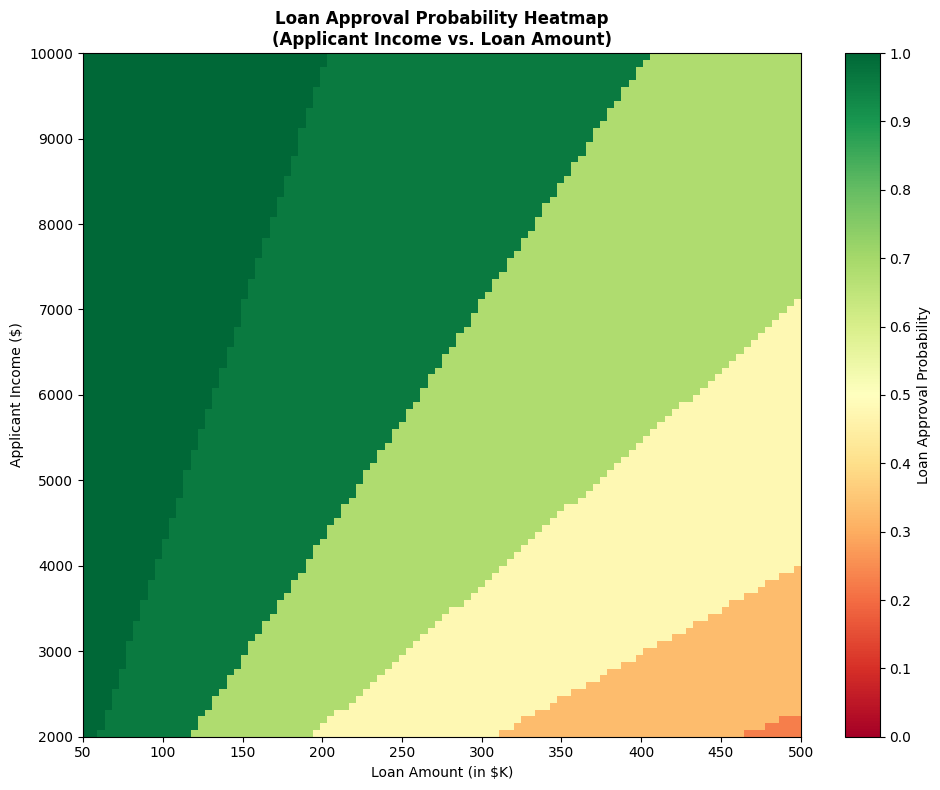

  [INFO] Heatmap generated to show sensitivity.


In [227]:
print("\n─── 11C. Sensitivity Sweep ───\n")

# Define ranges for income and loan amount
income_range = np.linspace(2000, 10000, 100)  # was 20, now 100
loan_range   = np.linspace(50, 500, 100)       # was 20, now 100

# Create a grid of probabilities
prob_grid = np.zeros((len(income_range), len(loan_range)))

# Use a baseline customer profile for the other features
base_customer_data = {
    'coapplicant_income': CREDIT_BASE['coapplicant_income'],
    'loan_term':          CREDIT_BASE['loan_amount_term'],
    'credit_history':     CREDIT_BASE['credit_history'],
    'dependents':         CREDIT_BASE['dependents'],
    'married':            CREDIT_BASE['married'],
    'education':          CREDIT_BASE['education'],
    'self_employed':      CREDIT_BASE['self_employed'],
    'property_area':      CREDIT_BASE['property_area']
}

for i, income in enumerate(income_range):
    for j, loan_amt in enumerate(loan_range):
        prob_grid[i, j] = compute_credit_risk(
            applicant_income=income,
            loan_amount=loan_amt,
            **base_customer_data
        )

# ── Plotting the Sensitivity Heatmap ──────────────────────────
fig, ax = plt.subplots(figsize=(10, 8))

im = ax.imshow(prob_grid, cmap='RdYlGn', origin='lower',
               extent=[loan_range.min(), loan_range.max(),
                       income_range.min(), income_range.max()],
               aspect='auto', vmin=0, vmax=1)

ax.set_title("Loan Approval Probability Heatmap\n(Applicant Income vs. Loan Amount)", fontweight='bold')
ax.set_xlabel("Loan Amount (in $K)")
ax.set_ylabel("Applicant Income ($)")

cbar = fig.colorbar(im, ax=ax, label='Loan Approval Probability')
cbar.set_ticks(np.arange(0, 1.1, 0.1))

plt.tight_layout()
plt.show()

print("  [INFO] Heatmap generated to show sensitivity.")



In [219]:
# ── Final Summary ─────────────────────────────────────────────
print("\n" + "=" * 60)
print("  PHASE 11 COMPLETE — WHAT-IF SIMULATOR SUMMARY")
print("=" * 60)
print("""
  What-if Simulation Capabilities:
    • Behavioural Simulator: Test scenarios for monthly income/expense changes,
      discretionary spending, and deficit streaks to see impact on EWS level.
    • Credit Risk Simulator: Adjust credit profile parameters (income, loan amount,
      credit history etc.) to predict changes in loan approval probability.
    • Sensitivity Sweep: Visualizes how loan approval probability changes across
      a range of Applicant Income and Loan Amounts, highlighting sensitive areas.

  Next → Phase 12: Streamlit Deployment
""")


  PHASE 11 COMPLETE — WHAT-IF SIMULATOR SUMMARY

  What-if Simulation Capabilities:
    • Behavioural Simulator: Test scenarios for monthly income/expense changes,
      discretionary spending, and deficit streaks to see impact on EWS level.
    • Credit Risk Simulator: Adjust credit profile parameters (income, loan amount,
      credit history etc.) to predict changes in loan approval probability.
    • Sensitivity Sweep: Visualizes how loan approval probability changes across
      a range of Applicant Income and Loan Amounts, highlighting sensitive areas.

  Next → Phase 12: Streamlit Deployment

